# Library

In [58]:
# Ignore the warnings
import warnings
# warnings.filterwarnings('always')
warnings.filterwarnings('ignore')

# System related and data input controls
import os

# Python path
import sys
base_folder = 'DataScience'
location_base = os.path.join(os.getcwd().split(base_folder)[0], base_folder)
location_module = [os.path.join(location_base, 'Module')] 
for each in location_module:
    if each not in sys.path:
        sys.path.append(each)

# Auto reload of library
%reload_ext autoreload
%autoreload 2

# Device Strategy
from import_KK import *
strategy, torch_device, num_gpus = DeviceStrategy()
from preprocessing_project_KK import *
from preprocessing_KK import *
from description_KK import *
from algorithm_machinelearning_KK import *
from algorithm_deeplearning_KK import *
from algorithm_causalml_KK import *
from evaluation_KK import *
from visualization_KK import *


=========== Device Strategy ===========
Detected GPUs:
 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TF isolated to CPU (All 24GB VRAM reserved exclusively for PyTorch/XGBoost)
======= GPU / CUDA / STATUS ========
Cuda Ready?         True
CUDA Version:       12.5.1
cuDNN Version:      9

TF Version:         2.20.0
Keras Version:      3.15.1

------- Torch Check ----------------
Torch CUDA Available: True
Torch Version:        2.14.0+cu130
Torch CUDA Version:   13.0
Torch cuDNN Version:  92600
Torch GPUs Available: 1
Use the GPU [0]:    NVIDIA GeForce RTX 5090 (Index: 0)



# Hyperparameters

In [70]:
# Data
# FOLDER_GDM, FOLDER_GDS = get_google_drivelocation(gdrive='z', glocation=os.path.join('Research', 'SavedData', 'NTIS'))
# FOLDER_LOCATION = FOLDER_GDM
FOLDER_LOCATION = os.path.join('.', 'Data')
FILENAME = 'service_rank1_preprocessed.csv'
FILE_LOCATION = os.path.join(FOLDER_LOCATION, FILENAME)
LANGUAGE = 'en'

# Data Filtering
YEAR_MIN = None
YEAR_MAX = None
AGE_MIN = None
AGE_MAX = None
GENDER = None # 'male', 'female', 'all'

# Preprocessing
Y_colname = 'bid_amount_krw'
Y_candidate = None
Time_colname = 'year'
T_colname = None
X_reverse = None
X_encoding = None
X_dummy = [
    'international_bid', 'urgent', 'industry_restriction', 'mandatory_joint_contract', 
    'contract_method', 'procurement_method', 'notice_status', 'service_field'
]
X_moderate = None
X_control = None
X_delYrelated = None
X_del = [
    '입찰공고번호', '입찰분류번호', '공고일', 'time_split', 'rank_group', 
    '공고기관코드', '수요기관코드', 'selected_rank', 'mandatory_joint_contract_N', 'international_bid_국내입찰'
]
X_delete = (X_delYrelated or []) + (X_del or [])
X_nullmax = None
X_nullmin = None
X_handle_nonres = False
X_nonres_col = None
WINSORIZE_YLIMITS = (0.01, 0.01)
# WINSORIZE_YLIMITS = None
# WINSORIZE_XLIMITS = (0.01, 0.01)
WINSORIZE_XLIMITS = None

TEST_SIZE = 'Time'
YEAR_VAL, YEAR_TEST = 1, 1 # Execute when TEST_SIZE = 'Time'
IMPUTE_METHOD = 'mice' # 'knn', 'mice', 'median'
RANDOM_STATE = 123
SAMPLING_METHOD = None    # 'auto'
# LABEL_LIST = ['Non-Violence', 'Violence']
LABEL_LIST = None

# Model
ALGO_NAMES_ML = ['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']
# ALGO_NAMES_ML = ['LightGBM', 'CatBoost']
ALGO_NAMES_DL = ['MLP', 'CNN', 'TabNet']
# ALGO_NAMES_DL = ['TabNet']
## Common
TUNE_TRIALS_ML = 100
TUNE_TRIALS_DL = 50
CV_SPLITS = 5
TUNE_METRIC_ML = 'RMSE' # Default('auto'): 'F1-score', 'RMSE' - 접두사 없어도 자동으로 validation set 기준으로 판단TUNE_METRIC = 'auto'
TUNE_METRIC_DL = 'val_RMSE' # 'AUC', 'Accuracy', 'F1-score', 'loss', 'val_AUC', 'val_Accuracy', 'val_F1-score', 'val_loss'
METRIC_FINAL = "RMSE"
## DL
CLASS_WEIGHT_METHOD = 'class' # class, sample, user_defined_dict
tf.random.set_seed(123)
NODE_MLP = [256, 512, 256, 128, 64]
NODE_CNN = [128, 256, 512]
VALIDATION_SPLIT = 0.2
if VALIDATION_SPLIT != None:
    VALIDATION_DATA = None
BATCH_SIZE = 1024
EPOCHS = 100
VERBOSE = 0
## XAI
SHAP = True
INTERACTION = False
INTERACTION_SAMPLES = 5000
INTERACTION_BATCH = 100
X_TOP_DISPLAY = 50
## Causal Inference
if T_colname != None:
    CAUSAL_CRITERION = 'het'
    CAUSAL_HONEST = True
    CAUSAL_INFERENCE = True
CV_CANDIDATE = [3,5,10]
N_ESTIMATORS = 1000
ROBUST_SAMPLES = 10000
CFSHAP_SAMPLES = 3000
CFSHAP_BATCH = 100

# Save
SAVE_NAME_PREDSTATTR = 'DescriptiveStatistics_BinaryPredTrain.csv'
SAVE_NAME_PREDSTATTE = 'DescriptiveStatistics_BinaryPredTest.csv'
SAVE_NAME_ML = 'Performance_ML'
SAVE_NAME_DL = 'Performance_DL'
SAVE_NAME_PERFORMANCE = 'Performance.csv'
SAVE_FOLDER_BASE = os.path.join('.', 'Result', 'Base')
SAVE_FOLDER_TEST = os.path.join('.', 'Result', 'Test')

# Data Preprocessing

In [67]:
# Data Loading
df_raw = pd.read_csv(os.path.join(FOLDER_LOCATION, FILENAME))
df_raw[Y_colname] = pd.to_numeric(df_raw[Y_colname]+1e-6, errors='coerce').astype(np.float64)

In [68]:
# # Preprocessing Data
# df_prep, YEAR_COLNAME, FEATURE_BLOCKS = preprocessing_CarbonFinance(
#     df_raw,
#     year_min=YEAR_MIN, 
#     year_max=YEAR_MAX,
#     Y_colname=Y_colname,          
#     drop_firm_dummies=True,        
#     create_lags=True,          
#     X_delete=X_delete
# )

# Preprocessing for Modeling
X_train, X_test, Y_train, Y_test, \
TASK, df_final, X_colname, \
CV_SPLITS, LABEL_LIST = preprocessing_modeling_KK(
    df_raw=df_raw, Y_colname=Y_colname, Time_colname=Time_colname, 
    X_reverse=X_reverse, X_encoding=X_encoding,
    X_dummy=X_dummy, X_moderate=X_moderate, X_control=X_control, X_delete=X_delete,
    winsorize_Ylimits=WINSORIZE_YLIMITS,
    winsorize_Xlimits=WINSORIZE_XLIMITS,
    test_size=TEST_SIZE, year_val=YEAR_VAL, year_test=YEAR_TEST,
    impute_method=IMPUTE_METHOD,
    sampling_method=SAMPLING_METHOD,
    label_list=LABEL_LIST,
)


Deleting Non-meaning & Data Leakage Variables...
Shape after dropping: (65571, 16)

▶ Detected Task Type: [ REGRESSION ] (Target: continuous)

Starting Preprocessing for REGRESSION...
Initial Shape: (65571, 16)

[OOT Split] Year Cutoff: Val @ 2024, Test @ 2025
▶ Target (Y) Winsorized (Train Quantiles): Low=16429902.4000, High=3625256520.0000
Dummy Feature Generating...
Dummy Feature Generating...

▶ Generating Regression Comparative Statistics...
[Baseline Characteristics Summary] (Continuous Target)
▶ Total X: 24 | Analysis X: 23
▶ Significant X (p <= 0.05): 23 (95.8%)

⚠️ Except/Skipped X (1):
   - [mandatory_joint_contract_N]: 단일값(상수 변수)
결과 파일 저장 완료: /workspace/DataScience/DIVE/Project/PublicProcurement/Result/DescriptiveStatistics_Regression.csv



Overall Sample  \
Feature                 Category / Metric                                 
budget_krw              Mean ± SD          517709749.05 ± 1152259476.31   
base_amount_krw         Mean ± SD          512679187.52 ± 1138097376.05   
estimated_price_krw     Mean ± SD          471923381.95 ± 1063098944.09   
contract_method_지명경쟁    0                               45,703 (90.23%)   
                        1                                 4,950 (9.77%)   
industry_restriction_Y  0                               18,010 (35.56%)   
                        1                               32,643 (64.44%)   
contract_method_일반경쟁    0                               38,126 (75.27%)   
                        1                               12,527 (24.73%)   
contract_method_제한경쟁    0                               17,477 (34.50%)   
                        1                               33,176 (65.50%)   
industry_restriction_N  0                               32,643 (64.44%)   
                        1                               18,010 (35.56%)   
service_field_기술용역      0                               16,900 (33.36%)   
                        1                               33,753 (66.64%)   
service_field_일반용역      0                               33,753 (66.64%)   
                        1                               16,900 (33.36%)   
urgent_미확인              0                               44,157 (87.18%)   
                        1                                6,496 (12.82%)   
procurement_method_자체조달 0                                7,074 (13.97%)   
                        1                               43,579 (86.03%)   
procurement_method_중앙조달 0                               43,579 (86.03%)   
                        1                                7,074 (13.97%)   
notice_month            Mean ± SD                           5.86 ± 3.54   
model_row_id            Mean ± SD                   30031.52 ± 17568.17   
urgent_N                0                               23,430 (46.26%)   
                        1                               27,223 (53.74%)   
international_bid_국제입찰  0                               49,600 (97.92%)   
                        1                                 1,053 (2.08%)   
international_bid_국내입찰  0                                 1,053 (2.08%)   
                        1                               49,600 (97.92%)   
notice_status_재공고       0                               49,374 (97.47%)   
                        1                                 1,279 (2.53%)   
notice_round            0                               47,117 (93.02%)   
                        1                                 2,930 (5.78%)   
                        2                                   466 (0.92%)   
                        3                                    95 (0.19%)   
                        4                                    35 (0.07%)   
                        5                                     7 (0.01%)   
                        6                                     1 (0.00%)   
                        12                                    1 (0.00%)   
                        13                                    1 (0.00%)   
notice_status_변경공고      0                               47,117 (93.02%)   
                        1                                 3,536 (6.98%)   
notice_status_등록공고      0                                 4,815 (9.51%)   
                        1                               45,838 (90.49%)   
urgent_Y                0                               33,719 (66.57%)   
                        1                               16,934 (33.43%)   

                                                    Target (Y) Subgroup  \
Feature                 Category / Metric                                 
budget_krw              Mean ± SD                                     -   
base_amount_krw         Mean ± SD                                     -   
estima


[X_delete] Dropping generated dummy columns: ['mandatory_joint_contract_N', 'international_bid_국내입찰']

Final Shapes -> Train: (50653, 22), Test: (14918, 22)
Total Preprocessing Time: 0:00:00
▶ Data Ready | CV Split Info: <class 'tuple'>



# Modeling

## Machine Learning

▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-15 02:12:15.787489


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}


Training Progress:  33%|███▎      | 33/100 [1:13:00<2:28:14, 132.75s/it]


  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': True, 'scaler_type': 'Normalizer'}
  ▶ [Trial 11] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 12] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 13] Params: {'fit_intercept': True, 'scaler_type': 'RobustS

,Features,Coef,Features,Coef
0,industry_restriction_Y,"2,248,146,944.0000",urgent_N,"-1,996,488,704.0000"
1,industry_restriction_N,"1,241,513,984.0000",urgent_Y,"-1,983,905,792.0000"
2,budget_krw,"486,195,200.0000",urgent_미확인,"-1,916,796,928.0000"
3,base_amount_krw,"343,441,408.0000",estimated_price_krw,"-699,777,024.0000"
4,international_bid_국제입찰,"131,964,928.0000",procurement_method_자체조달,"-369,098,752.0000"
5,model_row_id,"33,835,648.0000",contract_method_제한경쟁,"-357,564,416.0000"
6,contract_method_지명경쟁,"31,457,280.0000",procurement_method_중앙조달,"-268,435,456.0000"
7,notice_month,"19,297,472.0000",contract_method_일반경쟁,"-152,567,808.0000"
8,service_field_기술용역,"18,366,592.0000",notice_status_재공고,"-82,051,072.0000"
9,notice_round,"4,181,168.0000",notice_status_등록공고,"-62,521,344.0000"


Performance Evaluations...:  2026-10-15 02:14:02.521821
      ▶ [K-Fold Start] 총 5 Folds 교차검증 시작 (스레드: 6)...
      ▶ [Fold 1/5] 학습 진행 중... 완료 (0.02초)
      ▶ [Fold 2/5] 학습 진행 중... 완료 (0.02초)
      ▶ [Fold 3/5] 학습 진행 중... 완료 (0.02초)
      ▶ [Fold 4/5] 학습 진행 중... 완료 (0.02초)
      ▶ [Fold 5/5] 학습 진행 중... 완료 (0.02초)
Performance: 
   [Info] Linear Regression (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


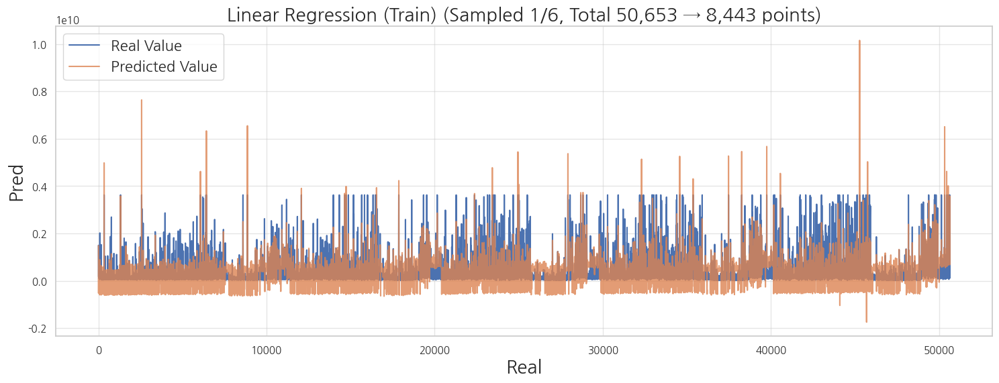

   [Info] Linear Regression (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


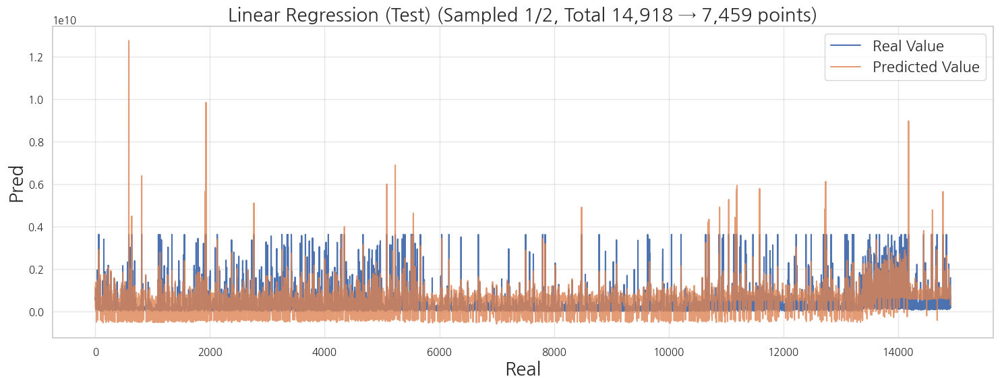

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,"581,442,805.0880",37.7672,"503,620,763.1186",4.0859,"412,890,834.0000",2.9212,0.1710
1,Linear Regression,Validation(CV),"433,555,081.7842",17.8616,"328,350,404.3811",2.6208,"278,149,568.0000",1.7439,0.5391
2,Linear Regression,Test set,"593,632,256.8612",49.7489,"497,980,438.8641",4.3455,"464,201,842.0000",2.9372,0.0893
3,Linear Regression,Entire population,"584,238,364.9588",40.4931,"502,337,537.9546",4.1450,"436,988,600.0000",2.9263,0.1535


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_Linear Regression_20261015_021403.pkl
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_Linear Regression_20261015_021403.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-15 02:14:03.274818


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

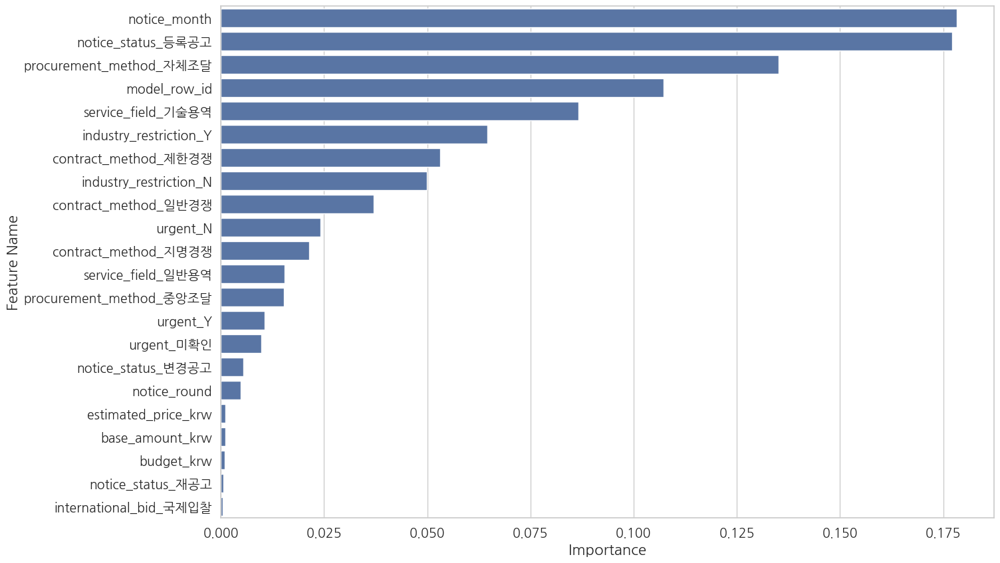

Performance Evaluations...:  2026-10-15 02:36:46.834515
      ▶ [K-Fold Start] 총 5 Folds 교차검증 시작 (스레드: 6)...
      ▶ [Fold 1/5] 학습 진행 중... 완료 (3.25초)
      ▶ [Fold 2/5] 학습 진행 중... 완료 (3.25초)
      ▶ [Fold 3/5] 학습 진행 중... 완료 (3.26초)
      ▶ [Fold 4/5] 학습 진행 중... 완료 (3.25초)
      ▶ [Fold 5/5] 학습 진행 중... 완료 (3.25초)
Performance: 
   [Info] Random Forest (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


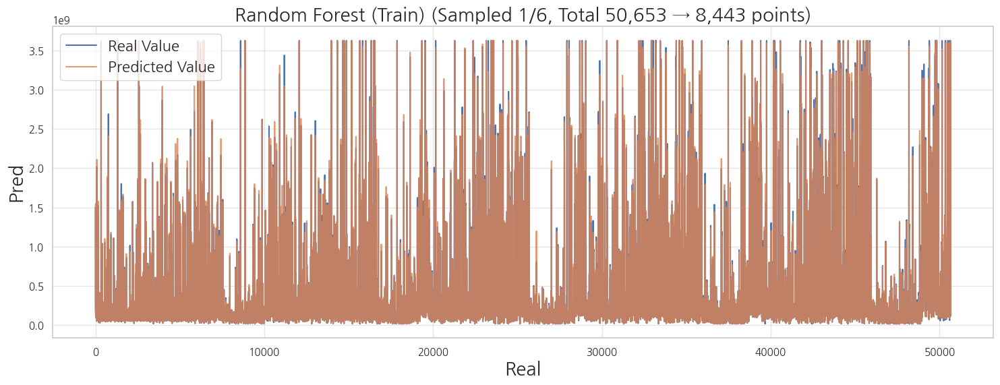

   [Info] Random Forest (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


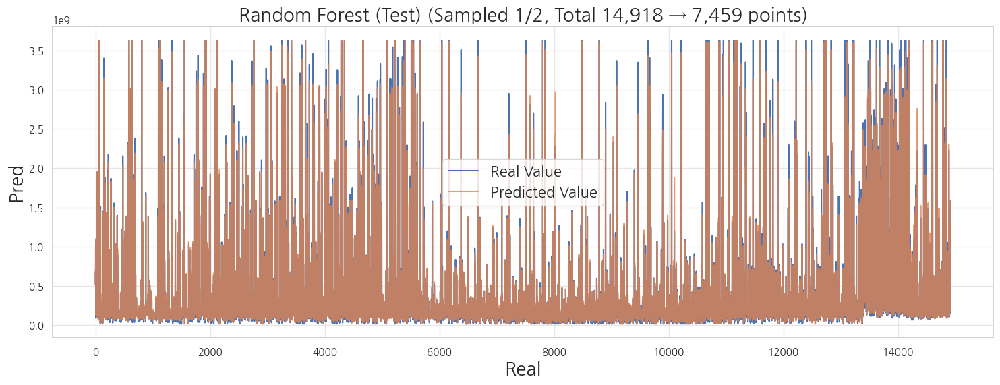

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,"27,891,388.5496",0.0039,"8,947,129.4876",0.0221,"1,354,544.0000",0.0095,0.9981
1,Random Forest,Validation(CV),"32,637,466.7796",0.0062,"10,516,327.3555",0.0266,"1,575,344.0000",0.0111,0.9974
2,Random Forest,Test set,"56,470,287.0029",0.1351,"24,653,287.0109",0.1590,"15,956,788.0000",0.0586,0.9918
3,Random Forest,Entire population,"36,420,403.3437",0.0338,"12,520,423.4428",0.0533,"2,149,296.0000",0.0127,0.9967


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_Random Forest_20261015_023703.pkl
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_Random Forest_20261015_023703.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-15 02:37:04.794648


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

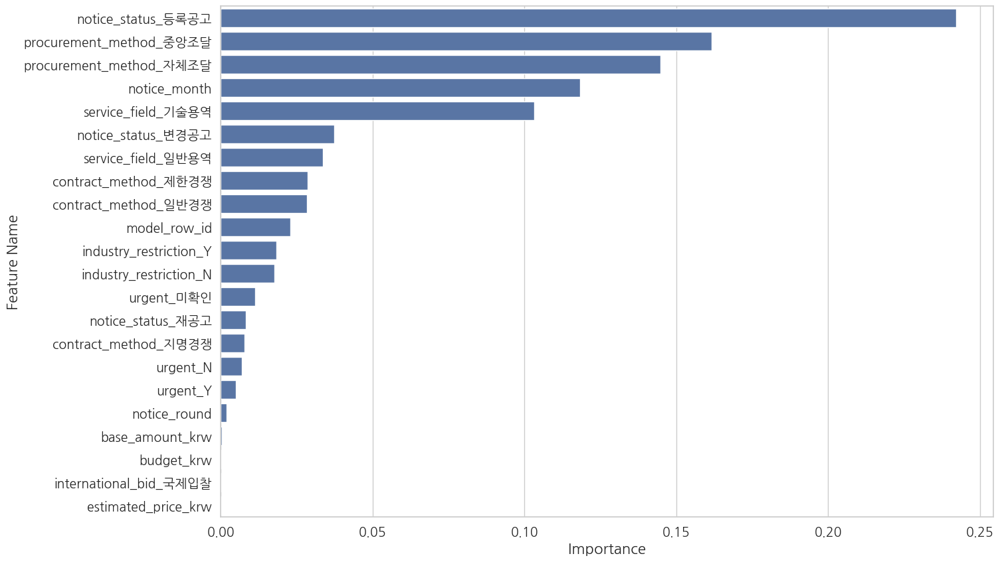

Performance Evaluations...:  2026-10-15 02:56:29.093823
      ▶ [K-Fold Start] 총 5 Folds 교차검증 시작 (스레드: 6)...
      ▶ [Fold 1/5] 학습 진행 중... 완료 (2.88초)
      ▶ [Fold 2/5] 학습 진행 중... 완료 (2.90초)
      ▶ [Fold 3/5] 학습 진행 중... 완료 (2.91초)
      ▶ [Fold 4/5] 학습 진행 중... 완료 (2.97초)
      ▶ [Fold 5/5] 학습 진행 중... 완료 (2.91초)
Performance: 
   [Info] XGBoost (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


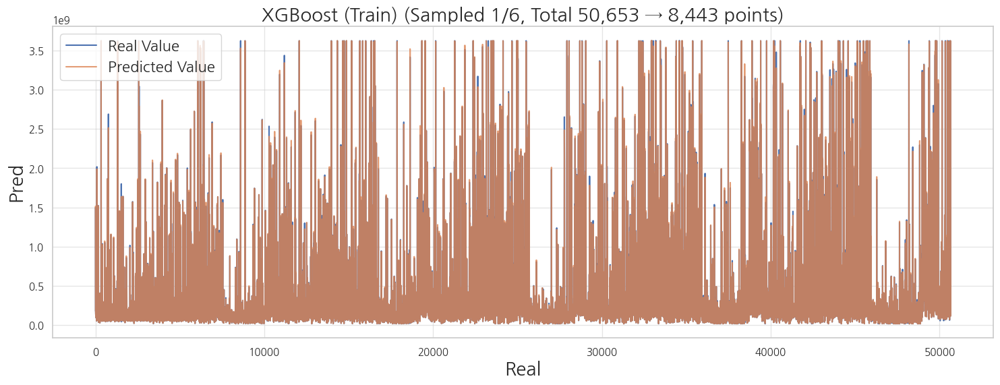

   [Info] XGBoost (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


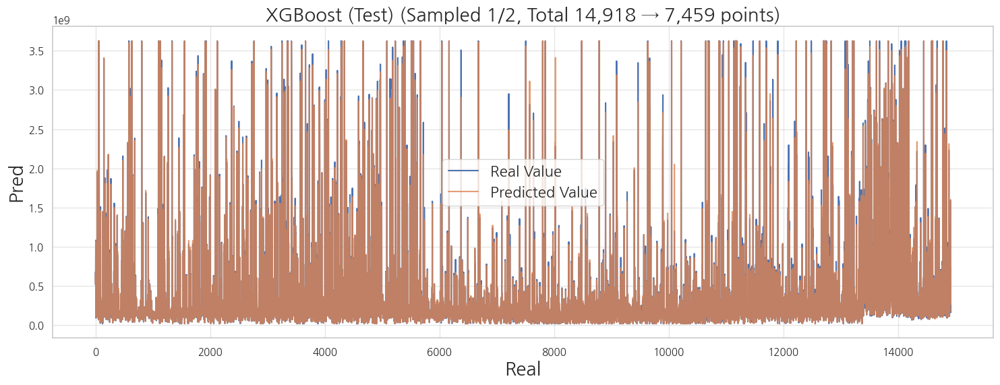

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,"12,118,109.1354",0.0012,"4,242,248.7317",0.0146,"1,154,408.0000",0.0074,0.9996
1,XGBoost,Validation(CV),"21,461,620.5635",0.0032,"6,858,669.4026",0.0205,"1,369,313.0000",0.0091,0.9989
2,XGBoost,Test set,"38,686,740.5682",0.0080,"12,324,947.0424",0.0386,"2,823,998.0000",0.0180,0.9961
3,XGBoost,Entire population,"21,305,958.2213",0.0028,"6,081,136.2490",0.0201,"1,394,120.0000",0.0087,0.9989


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_XGBoost_20261015_025644.pkl
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_XGBoost_20261015_025644.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-15 02:56:44.748679


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

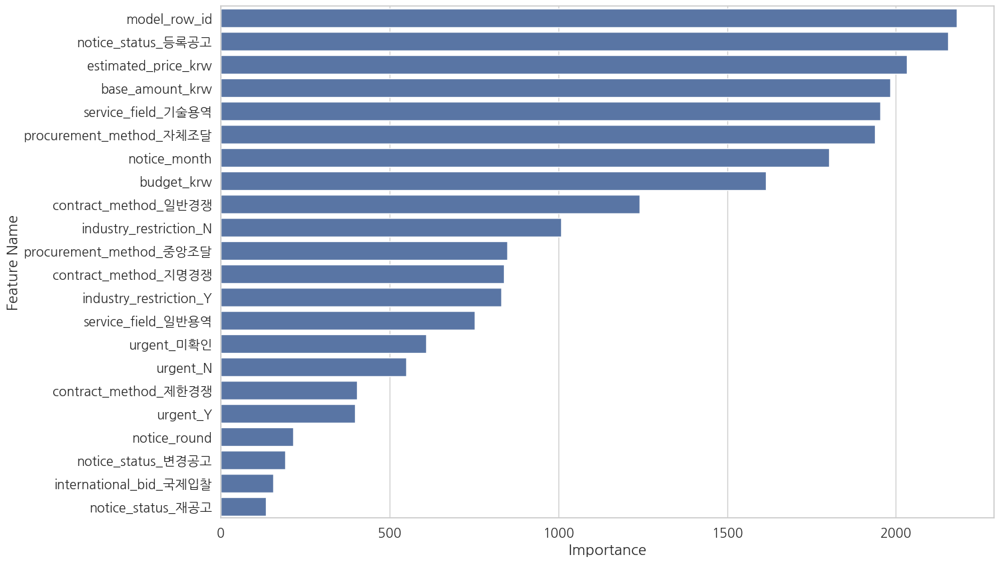

Performance Evaluations...:  2026-10-15 03:04:20.844514
      ▶ [K-Fold Start] 총 5 Folds 교차검증 시작 (스레드: 6)...
      ▶ [Fold 1/5] 학습 진행 중... 완료 (0.79초)
      ▶ [Fold 2/5] 학습 진행 중... 완료 (0.75초)
      ▶ [Fold 3/5] 학습 진행 중... 완료 (0.74초)
      ▶ [Fold 4/5] 학습 진행 중... 완료 (0.79초)
      ▶ [Fold 5/5] 학습 진행 중... 완료 (0.73초)
Performance: 
   [Info] LightGBM (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


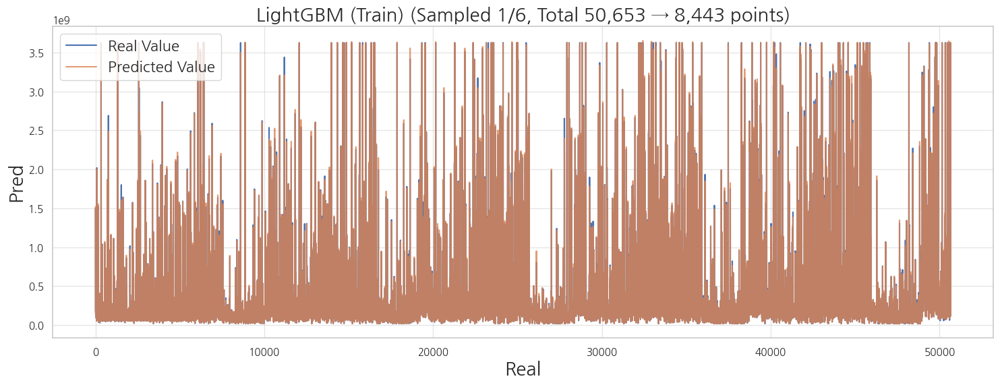

   [Info] LightGBM (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


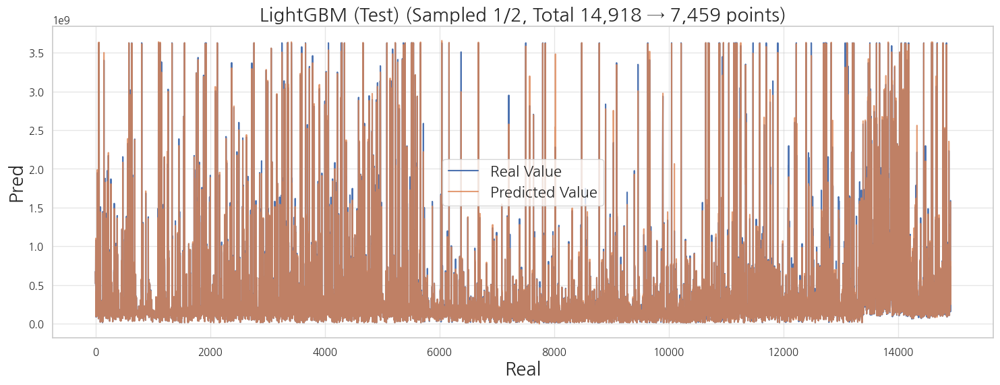

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,"15,388,689.9741",0.0023,"5,574,992.3231",0.0188,"1,343,920.8765",0.0087,0.9994
1,LightGBM,Validation(CV),"22,242,885.9821",0.0035,"7,193,615.5055",0.0214,"1,422,264.0000",0.0094,0.9988
2,LightGBM,Test set,"37,325,241.2144",0.0066,"10,381,544.9636",0.0294,"1,572,678.7339",0.0102,0.9964
3,LightGBM,Entire population,"22,358,323.6772",0.0032,"6,668,526.8473",0.0212,"1,392,209.5373",0.0090,0.9988


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_LightGBM_20261015_030425.pkl
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_LightGBM_20261015_030425.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-15 03:04:26.000902


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

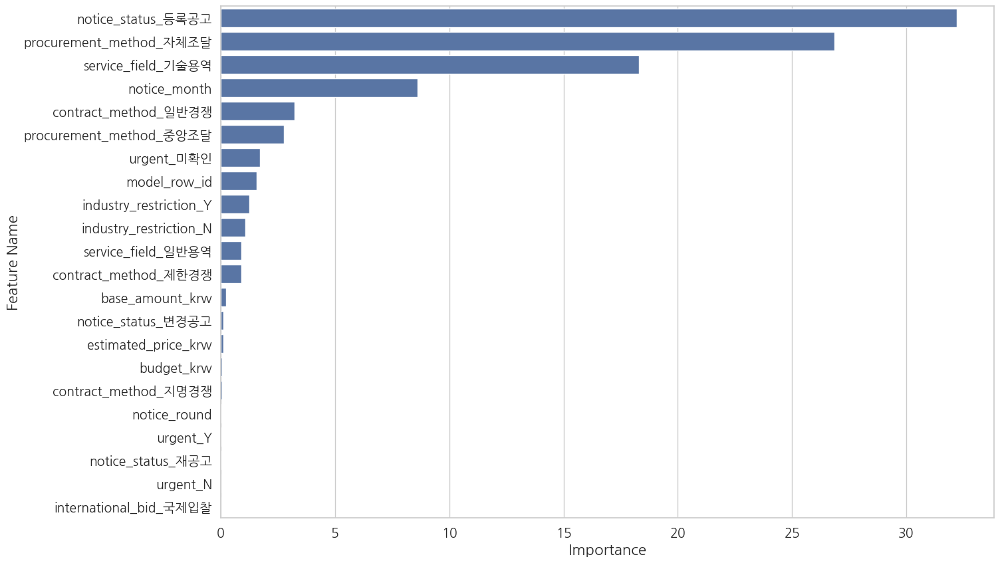

Performance Evaluations...:  2026-10-15 03:14:27.179184
      ▶ [K-Fold Start] 총 5 Folds 교차검증 시작 (스레드: 6)...
      ▶ [Fold 1/5] 학습 진행 중... 완료 (0.74초)
      ▶ [Fold 2/5] 학습 진행 중... 완료 (0.74초)
      ▶ [Fold 3/5] 학습 진행 중... 완료 (0.77초)
      ▶ [Fold 4/5] 학습 진행 중... 완료 (0.76초)
      ▶ [Fold 5/5] 학습 진행 중... 완료 (0.78초)
Performance: 
   [Info] CatBoost (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


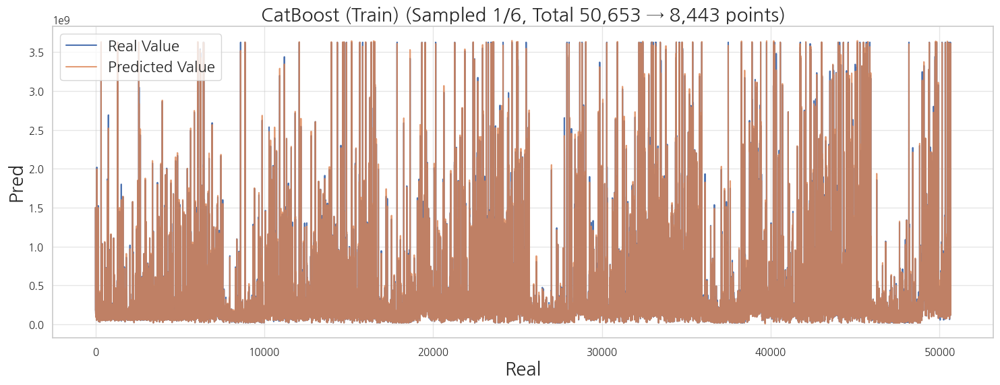

   [Info] CatBoost (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


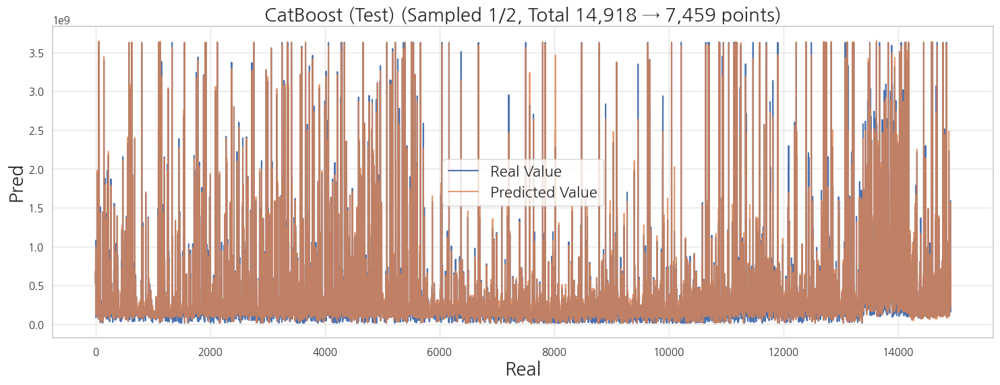

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,"17,840,709.7638",0.0032,"7,946,513.2228",0.0299,"2,944,660.7556",0.0187,0.9992
1,CatBoost,Validation(CV),"25,966,526.5638",0.0055,"9,652,149.4123",0.0327,"3,023,600.0000",0.0196,0.9983
2,CatBoost,Test set,"63,162,233.2501",0.5575,"41,370,438.6153",0.3591,"35,795,103.6368",0.0883,0.9897
3,CatBoost,Entire population,"33,963,467.0788",0.1293,"15,550,760.8171",0.1048,"3,770,892.2950",0.0225,0.9971


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_CatBoost_20261015_031431.pkl
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_CatBoost_20261015_031431.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,581442805.0880,37.7672,503620763.1186,4.0859,412890834.0000,2.9212,0.1710
4,Random Forest,Train set,27891388.5496,0.0039,8947129.4876,0.0221,1354544.0000,0.0095,0.9981
8,XGBoost,Train set,12118109.1354,0.0012,4242248.7317,0.0146,1154408.0000,0.0074,0.9996
12,LightGBM,Train set,15388689.9741,0.0023,5574992.3231,0.0188,1343920.8765,0.0087,0.9994
16,CatBoost,Train set,17840709.7638,0.0032,7946513.2228,0.0299,2944660.7556,0.0187,0.9992


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),433555081.7842,17.8616,328350404.3811,2.6208,278149568.0000,1.7439,0.5391
5,Random Forest,Validation(CV),32637466.7796,0.0062,10516327.3555,0.0266,1575344.0000,0.0111,0.9974
9,XGBoost,Validation(CV),21461620.5635,0.0032,6858669.4026,0.0205,1369313.0000,0.0091,0.9989
13,LightGBM,Validation(CV),22242885.9821,0.0035,7193615.5055,0.0214,1422264.0000,0.0094,0.9988
17,CatBoost,Validation(CV),25966526.5638,0.0055,9652149.4123,0.0327,3023600.0000,0.0196,0.9983


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,593632256.8612,49.7489,497980438.8641,4.3455,464201842.0000,2.9372,0.0893
6,Random Forest,Test set,56470287.0029,0.1351,24653287.0109,0.1590,15956788.0000,0.0586,0.9918
10,XGBoost,Test set,38686740.5682,0.0080,12324947.0424,0.0386,2823998.0000,0.0180,0.9961
14,LightGBM,Test set,37325241.2144,0.0066,10381544.9636,0.0294,1572678.7339,0.0102,0.9964
18,CatBoost,Test set,63162233.2501,0.5575,41370438.6153,0.3591,35795103.6368,0.0883,0.9897


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,584238364.9588,40.4931,502337537.9546,4.1450,436988600.0000,2.9263,0.1535
7,Random Forest,Entire population,36420403.3437,0.0338,12520423.4428,0.0533,2149296.0000,0.0127,0.9967
11,XGBoost,Entire population,21305958.2213,0.0028,6081136.2490,0.0201,1394120.0000,0.0087,0.9989
15,LightGBM,Entire population,22358323.6772,0.0032,6668526.8473,0.0212,1392209.5373,0.0090,0.9988
19,CatBoost,Entire population,33963467.0788,0.1293,15550760.8171,0.1048,3770892.2950,0.0225,0.9971


Saved total performance to: /workspace/DataScience/DIVE/Project/PublicProcurement/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/PublicProcurement/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/Best_Result_ML(Trial100).pkl


In [71]:
results_ML, scores_ML = modeling_ML(
    algos=ALGO_NAMES_ML,
    X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test,
    task=TASK,
    X_colname=X_colname,
    params=None, # 특정 알고리즘
    tune_trials=TUNE_TRIALS_ML, # 최적화 여부
    cv_splits=CV_SPLITS,
    tune_metric=TUNE_METRIC_ML,
    X_top_display=X_TOP_DISPLAY, 
    label_list=LABEL_LIST,
    random_state=RANDOM_STATE,
)


## Deep Learning

▶ Manually Specified Task Type: [ regression ]

   Running Deep Learning Algorithm: MLP (regression)
[Info] Starting Hyperparameter Optimization (Trials: 50)...


  0%|          | 0/50 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 1.8591711878786356e-05, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.2192861223398122, 'batch_size': 4096, 'optimizer': 'adamw', 'learning_rate': 0.001196267211457031, 'first_layer_nodes': 512, 'shape': 'funnel'}


Training Progress:  11%|█         | 11/100 [00:01<00:14,  6.09it/s]


  ▶ [Trial 1] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 1, 'l2_regularization': 7.814989008992038e-05, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.2131756534814041, 'batch_size': 2048, 'optimizer': 'adam', 'learning_rate': 0.0029636934049520115, 'first_layer_nodes': 256, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:17<00:00,  5.79it/s]


  ▶ [Trial 2] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 4.3172184004200446e-05, 'batch_normalization': True, 'hidden_activation': 'selu', 'dropout': 0.33465689148113614, 'batch_size': 4096, 'optimizer': 'adam', 'learning_rate': 0.00021378586344772922, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress:  11%|█         | 11/100 [00:01<00:13,  6.48it/s]


  ▶ [Trial 3] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 2.998326563858224e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.46256624480699304, 'batch_size': 1024, 'optimizer': 'adamw', 'learning_rate': 0.00040242845465492534, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  3.96it/s]


  ▶ [Trial 4] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 9.997091118230384e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.4272262437622524, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0009614829566263244, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  3.99it/s]


  ▶ [Trial 5] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 0.0008930847112671619, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.30034928391679494, 'batch_size': 2048, 'optimizer': 'adamw', 'learning_rate': 0.00014406526469896248, 'first_layer_nodes': 256, 'shape': 'funnel'}


Training Progress: 100%|██████████| 100/100 [00:19<00:00,  5.12it/s]


  ▶ [Trial 6] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0003294048911017984, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.33243622440164716, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000977103796382327, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.71it/s]


  ▶ [Trial 7] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0002914152933371891, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.2811091893654528, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0038311112694153675, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:17<00:00,  5.79it/s]


  ▶ [Trial 8] Params: {'scaler_type': 'StandardScaler', 'n_layers': 1, 'l2_regularization': 0.000171530741666032, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.38469866853698115, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.000529098387864771, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress:  11%|█         | 11/100 [00:01<00:12,  7.17it/s]


[W 2026-10-15 03:54:14,300] Trial 8 failed with parameters: {'scaler_type': 'StandardScaler', 'n_layers': 1, 'l2_regularization': 0.000171530741666032, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.38469866853698115, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.000529098387864771, 'first_layer_nodes': 512, 'shape': 'constant'} because of the following error: The value nan is not acceptable.
[W 2026-10-15 03:54:14,301] Trial 8 failed with value nan.
  ▶ [Trial 9] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0009270507768789004, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.15683447502606374, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.00032583566392085076, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress:  11%|█         | 11/100 [00:01<00:15,  5.83it/s]


[W 2026-10-15 03:54:19,596] Trial 9 failed with parameters: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0009270507768789004, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.15683447502606374, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.00032583566392085076, 'first_layer_nodes': 512, 'shape': 'constant'} because of the following error: The value nan is not acceptable.
[W 2026-10-15 03:54:19,598] Trial 9 failed with value nan.
  ▶ [Trial 10] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 2.4306715887478283e-05, 'batch_normalization': True, 'hidden_activation': 'relu', 'dropout': 0.3578006375771524, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.000712859168184597, 'first_layer_nodes': 128, 'shape': 'funnel'}


Training Progress:  11%|█         | 11/100 [00:01<00:12,  7.13it/s]


  ▶ [Trial 11] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 1, 'l2_regularization': 8.004363514526591e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.2987165541801875, 'batch_size': 2048, 'optimizer': 'adam', 'learning_rate': 0.00011966706041639411, 'first_layer_nodes': 384, 'shape': 'funnel'}


Training Progress:  11%|█         | 11/100 [00:01<00:14,  6.06it/s]


  ▶ [Trial 12] Params: {'scaler_type': 'StandardScaler', 'n_layers': 1, 'l2_regularization': 0.0003892939332159256, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.382798070607806, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.004748186759211707, 'first_layer_nodes': 128, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:22<00:00,  4.36it/s]


  ▶ [Trial 13] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.00013110536499566264, 'batch_normalization': True, 'hidden_activation': 'selu', 'dropout': 0.343614667590579, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0006595191620803127, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:34<00:00,  2.94it/s]


  ▶ [Trial 14] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0008793680216737889, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.33166528031183357, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.0004214645775429541, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress:  11%|█         | 11/100 [00:02<00:22,  3.91it/s]


[W 2026-10-15 03:55:39,822] Trial 14 failed with parameters: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0008793680216737889, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.33166528031183357, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.0004214645775429541, 'first_layer_nodes': 384, 'shape': 'constant'} because of the following error: The value nan is not acceptable.
[W 2026-10-15 03:55:39,823] Trial 14 failed with value nan.
  ▶ [Trial 15] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00011045869361854531, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.3897722151089622, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00033179001373398134, 'first_layer_nodes': 256, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  4.00it/s]


  ▶ [Trial 16] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 1.498061313402581e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.3911530504923945, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0025654231241768496, 'first_layer_nodes': 256, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  3.99it/s]


  ▶ [Trial 17] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 3.129914618417769e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.2916353146373962, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000912892709919922, 'first_layer_nodes': 256, 'shape': 'funnel'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.71it/s]


  ▶ [Trial 18] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 7.066771420941377e-06, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.26509792072886623, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0007298208110446611, 'first_layer_nodes': 128, 'shape': 'funnel'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.72it/s]


  ▶ [Trial 19] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0005373314784014465, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.17324589845679528, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0005763420919142068, 'first_layer_nodes': 256, 'shape': 'funnel'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.71it/s]


  ▶ [Trial 20] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 2.1303187565587183e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.388629908016786, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00025519684711760356, 'first_layer_nodes': 128, 'shape': 'funnel'}


Training Progress:  11%|█         | 11/100 [00:02<00:21,  4.15it/s]


  ▶ [Trial 21] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.000489400676456586, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.26918917738977005, 'batch_size': 1024, 'optimizer': 'adam', 'learning_rate': 0.0012903486713994104, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  3.95it/s]


  ▶ [Trial 22] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0006066037822100858, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.4145935957191922, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0009661550601096771, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.76it/s]


  ▶ [Trial 23] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0008940044697408892, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.3809104527541364, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00044823484240950553, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.70it/s]


  ▶ [Trial 24] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00037192240240257454, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.42854731616773384, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0005843516833833376, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:24<00:00,  4.01it/s]


  ▶ [Trial 25] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.00011803970776124462, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.26915332704552486, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0011963118870172713, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:15<00:00,  6.48it/s]


  ▶ [Trial 26] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0004835772139686519, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.23151409299220516, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0010078428436435893, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:15<00:00,  6.49it/s]


  ▶ [Trial 27] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0005791758668364865, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.34801723466951623, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00015715663220537178, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:26<00:00,  3.71it/s]


  ▶ [Trial 28] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0003315106827937408, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.44888091948006464, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0013240171899740183, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:19<00:00,  5.23it/s]


  ▶ [Trial 29] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00043944888685122527, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.4680260038788948, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0031086313528190745, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:18<00:00,  5.50it/s]


  ▶ [Trial 30] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00010214224815408002, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.42537666938257973, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.001946840249705693, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:18<00:00,  5.48it/s]


  ▶ [Trial 31] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0004836705974090262, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3955213791754939, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0008784242615492392, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.70it/s]


  ▶ [Trial 32] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0006805137367905973, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.49825664771986716, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000273551659861755, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.65it/s]


  ▶ [Trial 33] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0002833507346241546, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4075323570710184, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0010006750706236815, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:15<00:00,  6.39it/s]


  ▶ [Trial 34] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.00031245457713583526, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.47875190420907754, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.002007804378889188, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:19<00:00,  5.14it/s]


  ▶ [Trial 35] Params: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0003125341689801615, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.32455783889494333, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.0011363765479567073, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress:  11%|█         | 11/100 [00:02<00:23,  3.80it/s]


[W 2026-10-15 04:04:15,150] Trial 35 failed with parameters: {'scaler_type': 'StandardScaler', 'n_layers': 3, 'l2_regularization': 0.0003125341689801615, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.32455783889494333, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.0011363765479567073, 'first_layer_nodes': 512, 'shape': 'constant'} because of the following error: The value nan is not acceptable.
[W 2026-10-15 04:04:15,151] Trial 35 failed with value nan.
  ▶ [Trial 36] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00034861359349464775, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3978811603769666, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0004940670001154013, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress:  72%|███████▏  | 72/100 [00:19<00:07,  3.67it/s]


  ▶ [Trial 37] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0003167091802788884, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.37702290995328935, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00226469258398338, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.63it/s]


  ▶ [Trial 38] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.00026938211442904445, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.46486383557552713, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0012365696471008862, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:25<00:00,  3.92it/s]


  ▶ [Trial 39] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00020492647138498313, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.47146743285335246, 'batch_size': 1024, 'optimizer': 'adamw', 'learning_rate': 0.0013513342117244755, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:28<00:00,  3.54it/s]


  ▶ [Trial 40] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00026542028548990075, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.48614965051658465, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002995835769750642, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.66it/s]


  ▶ [Trial 41] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0004595852586691334, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.44841112839734487, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0025937511357769383, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


  ▶ [Trial 42] Params: {'scaler_type': 'None', 'n_layers': 3, 'l2_regularization': 0.00025776900861319694, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3866683261022348, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002623882310901991, 'first_layer_nodes': 512, 'shape': 'constant'}


Training Progress:  17%|█▋        | 17/100 [00:04<00:22,  3.75it/s]


  ▶ [Trial 43] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 5.937678635270747e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.36318465870529404, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0029356510087177284, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


  ▶ [Trial 44] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.0008628455765204917, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3978788683071097, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0011599423792646225, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.62it/s]


  ▶ [Trial 45] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00027496095858405267, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.48416043948379545, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0025288454454420366, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.60it/s]


  ▶ [Trial 46] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 8.180124122839543e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.43641053879567293, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0030923178553317015, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


  ▶ [Trial 47] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00018025442360601054, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.41245151536576874, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.003909499569398418, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


  ▶ [Trial 48] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00013075920215333955, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3873551531816586, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002842078402926589, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.62it/s]


  ▶ [Trial 49] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00010457887830977483, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4248375444243607, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0014826069547414292, 'first_layer_nodes': 384, 'shape': 'constant'}


Training Progress: 100%|██████████| 100/100 [00:27<00:00,  3.62it/s]


[MLP] Best Metric Trial:  47
[MLP] Best Tuning Parameters:  {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 0.00018025442360601054, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.41245151536576874, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.003909499569398418, 'first_layer_nodes': 384, 'shape': 'constant'}
[MLP] Best Metric Score:  65136397.96742772



Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

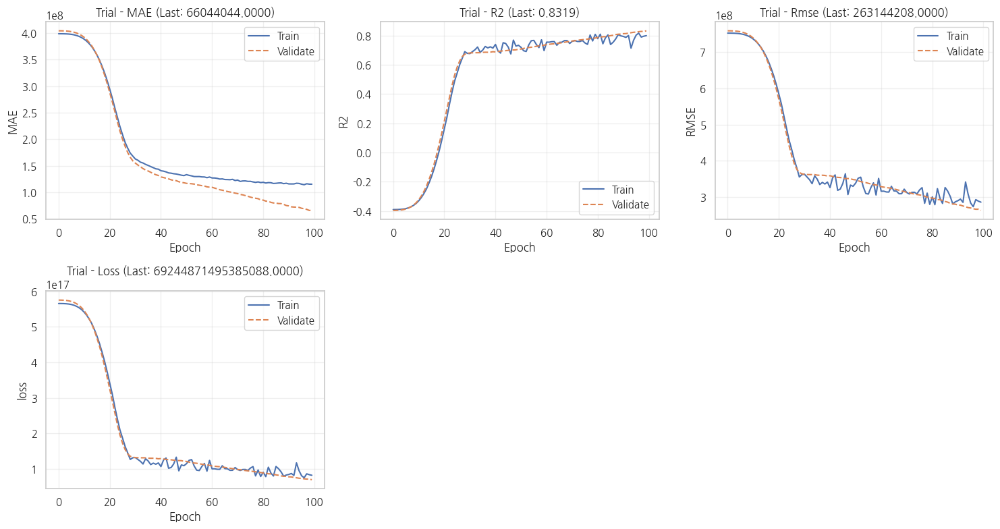

Training Progress: 100%|██████████| 100/100 [00:48<00:00,  2.06it/s]


   [Save] MLP Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_MLP_20261015_041147.keras
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_MLP_20261015_041147.json
Performance: 
   [Info] MLP (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


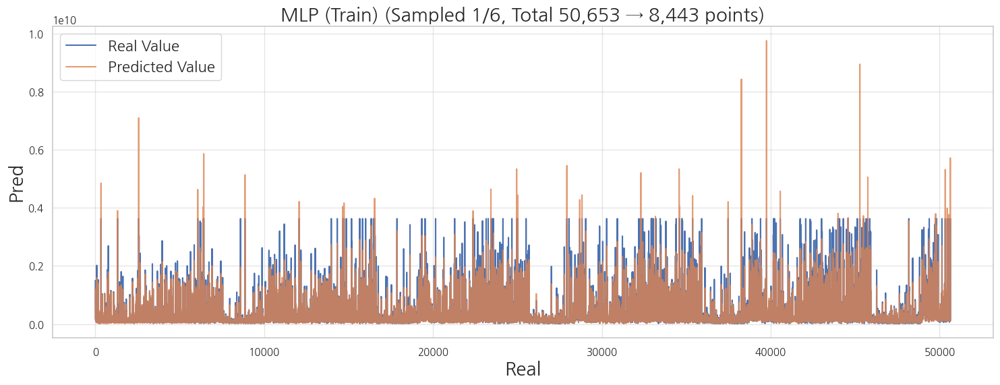

   [Info] MLP (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


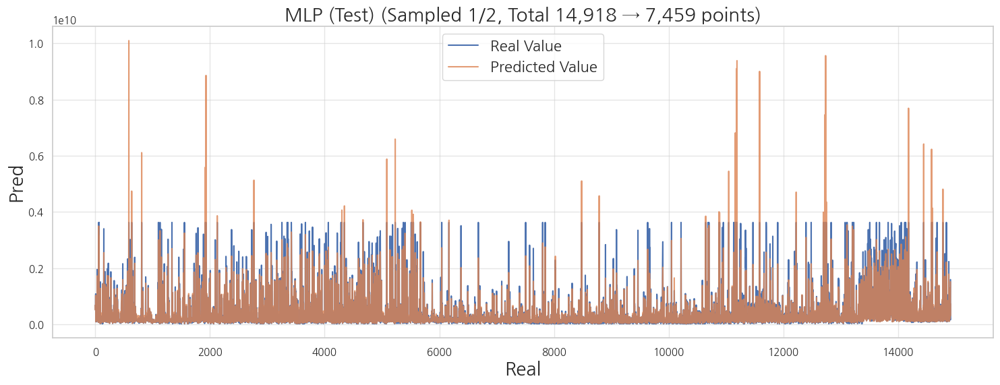

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,MLP,Train set,"236,745,489.1416",0.2453,"63,395,167.8069",0.2012,"18,528,856.0000",0.1230,0.8626
1,MLP,Validation(CV),"263,144,201.1278",0.2497,"66,044,018.1006",0.2022,"18,751,600.0000",0.1235,0.8319
2,MLP,Test set,"291,800,369.0055",0.3561,"63,428,082.8122",0.2288,"15,569,554.0000",0.0894,0.7799
3,MLP,Entire population,"250,337,214.2157",0.2705,"63,402,656.2705",0.2075,"17,760,172.0000",0.1149,0.8446



   Running Deep Learning Algorithm: CNN (regression)
[Info] Starting Hyperparameter Optimization (Trials: 50)...


  0%|          | 0/50 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 1.8591711878786356e-05, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.2192861223398122, 'batch_size': 4096, 'optimizer': 'adamw', 'learning_rate': 0.001196267211457031, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [03:49<00:00,  2.29s/it]


  ▶ [Trial 1] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 8.645371676200101e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.15864274091016045, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.00016030404647845854, 'batch_size_cnn': 128, 'base_filters': 128, 'kernel_size': 5}


Training Progress:  15%|█▌        | 15/100 [00:21<02:04,  1.46s/it]


  ▶ [Trial 2] Params: {'scaler_type': 'None', 'n_layers': 3, 'l2_regularization': 1.7765808030254089e-06, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.31362448602563436, 'batch_size': 1024, 'optimizer': 'adamw', 'learning_rate': 0.00034799627627293996, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [03:51<00:00,  2.31s/it]


  ▶ [Trial 3] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00011887906923067918, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.052954242528406914, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0003453131641091697, 'batch_size_cnn': 512, 'base_filters': 128, 'kernel_size': 7}


Training Progress:  11%|█         | 11/100 [00:04<00:39,  2.24it/s]


[W 2026-10-15 04:20:12,594] Trial 3 failed with parameters: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 0.00011887906923067918, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.052954242528406914, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0003453131641091697, 'batch_size_cnn': 512, 'base_filters': 128, 'kernel_size': 7} because of the following error: The value nan is not acceptable.
[W 2026-10-15 04:20:12,595] Trial 3 failed with value nan.
  ▶ [Trial 4] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 0.0008930847112671619, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.30034928391679494, 'batch_size': 2048, 'optimizer': 'adamw', 'learning_rate': 0.00014406526469896248, 'batch_size_cnn': 256, 'base_filters': 64, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [01:33<00:00,  1.07it/s]


  ▶ [Trial 5] Params: {'scaler_type': 'StandardScaler', 'n_layers': 2, 'l2_regularization': 2.158621581901584e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.2828210006129414, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0018924333411282372, 'batch_size_cnn': 256, 'base_filters': 32, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [01:18<00:00,  1.27it/s]


  ▶ [Trial 6] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00026534727284698473, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.18949292484945884, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0008354532661182695, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.22it/s]


  ▶ [Trial 7] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 2.7738235211351238e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.11829990585275968, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.00025740480410994316, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  11%|█         | 11/100 [00:04<00:39,  2.24it/s]


  ▶ [Trial 8] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 2.4306715887478283e-05, 'batch_normalization': True, 'hidden_activation': 'relu', 'dropout': 0.3578006375771524, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.000712859168184597, 'batch_size_cnn': 256, 'base_filters': 32, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [01:14<00:00,  1.34it/s]


  ▶ [Trial 9] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 3.0622984261272048e-06, 'batch_normalization': True, 'hidden_activation': 'selu', 'dropout': 0.06347901551798069, 'batch_size': 1024, 'optimizer': 'adam', 'learning_rate': 0.0005373286141927822, 'batch_size_cnn': 512, 'base_filters': 64, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:56<00:00,  1.76it/s]


  ▶ [Trial 10] Params: {'scaler_type': 'StandardScaler', 'n_layers': 1, 'l2_regularization': 0.0004220594237219415, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.14912269665866473, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.00010139140016334824, 'batch_size_cnn': 256, 'base_filters': 64, 'kernel_size': 7}


Training Progress:  11%|█         | 11/100 [00:07<00:56,  1.56it/s]


  ▶ [Trial 11] Params: {'scaler_type': 'None', 'n_layers': 1, 'l2_regularization': 0.00011741135606198493, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.11625141458764332, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0030333342981976393, 'batch_size_cnn': 128, 'base_filters': 64, 'kernel_size': 3}


Training Progress:  15%|█▌        | 15/100 [00:17<01:39,  1.17s/it]


  ▶ [Trial 12] Params: {'scaler_type': 'None', 'n_layers': 1, 'l2_regularization': 5.926217858298988e-05, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.18916501120910922, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002827180361863316, 'batch_size_cnn': 128, 'base_filters': 64, 'kernel_size': 3}


Training Progress:  15%|█▌        | 15/100 [00:17<01:39,  1.17s/it]


  ▶ [Trial 13] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00022625875075520888, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.012913504097027295, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00019127478142413038, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  12%|█▏        | 12/100 [00:05<00:39,  2.26it/s]


  ▶ [Trial 14] Params: {'scaler_type': 'StandardScaler', 'n_layers': 1, 'l2_regularization': 0.0003562525738031326, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.001240833261285268, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0017630426994381682, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:38<00:00,  2.57it/s]


  ▶ [Trial 15] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0001247909596747102, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.28854508991323546, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0010930870673044751, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:36,  2.26it/s]


  ▶ [Trial 16] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 3.657550687673744e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.336194718690746, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000956933950467451, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 7}


Training Progress: 100%|██████████| 100/100 [00:45<00:00,  2.18it/s]


  ▶ [Trial 17] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 0.00014241834455298044, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.17307535171997235, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000706897647594162, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:45<00:00,  2.20it/s]


  ▶ [Trial 18] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00020193625999449468, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.38863666039818556, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002615358665110079, 'batch_size_cnn': 512, 'base_filters': 128, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.23it/s]


  ▶ [Trial 19] Params: {'scaler_type': 'None', 'n_layers': 3, 'l2_regularization': 2.3793639405450872e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.2741184136767459, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0006204873637675965, 'batch_size_cnn': 256, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  11%|█         | 11/100 [00:10<01:21,  1.09it/s]


  ▶ [Trial 20] Params: {'scaler_type': 'None', 'n_layers': 1, 'l2_regularization': 0.000631254622139794, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.12555065924595257, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0009109882089958849, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 7}


Training Progress:  11%|█         | 11/100 [00:04<00:33,  2.64it/s]


  ▶ [Trial 21] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0006190521773020555, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.3099659097025294, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0012013724141372941, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:24<01:57,  1.42s/it]


  ▶ [Trial 22] Params: {'scaler_type': 'None', 'n_layers': 3, 'l2_regularization': 1.168840706714333e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.20627114123404358, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0012293195474952728, 'batch_size_cnn': 256, 'base_filters': 128, 'kernel_size': 3}


Training Progress:  14%|█▍        | 14/100 [00:12<01:18,  1.10it/s]


  ▶ [Trial 23] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0004848515881288302, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.19834930917982588, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0010854975996260252, 'batch_size_cnn': 512, 'base_filters': 64, 'kernel_size': 5}


Training Progress:  26%|██▌       | 26/100 [00:11<00:33,  2.18it/s]


  ▶ [Trial 24] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0006591779502308987, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.32077350284594874, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0004012913779103325, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  11%|█         | 11/100 [00:04<00:40,  2.21it/s]


  ▶ [Trial 25] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0007137528901112454, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.17040705672000117, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00040569602359687515, 'batch_size_cnn': 512, 'base_filters': 64, 'kernel_size': 5}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.22it/s]


  ▶ [Trial 26] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0003873165119932671, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.23058088032540972, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002138969208146498, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:36,  2.26it/s]


  ▶ [Trial 27] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 5.337916700179683e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.26567756160119593, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0007890214267956953, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.21it/s]


  ▶ [Trial 28] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 8.329930536039939e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.20986469587913098, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00027238716150625164, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:45<00:00,  2.18it/s]


  ▶ [Trial 29] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0007413352581615851, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.17017988836203105, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0005339400938031739, 'batch_size_cnn': 128, 'base_filters': 64, 'kernel_size': 5}


Training Progress:  15%|█▌        | 15/100 [00:21<02:03,  1.45s/it]


  ▶ [Trial 30] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00019990774187640691, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.24784888781204467, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0015325499636417664, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  27%|██▋       | 27/100 [00:12<00:32,  2.25it/s]


  ▶ [Trial 31] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 6.668121275796745e-05, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.3468754803073864, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.000479395316477217, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:45<00:00,  2.18it/s]


  ▶ [Trial 32] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0009196296109265166, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.17549359655852914, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002054327242770001, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.23it/s]


  ▶ [Trial 33] Params: {'scaler_type': 'None', 'n_layers': 1, 'l2_regularization': 0.00023158661770245105, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.2951638378218745, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0021404526749679922, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  11%|█         | 11/100 [00:04<00:33,  2.64it/s]


  ▶ [Trial 34] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00037839294627037577, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.212759129670408, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.00387545299195925, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  17%|█▋        | 17/100 [00:07<00:37,  2.23it/s]


  ▶ [Trial 35] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.00014832324263982976, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.07936732102814581, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0013045828196275124, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  11%|█         | 11/100 [00:04<00:39,  2.23it/s]


  ▶ [Trial 36] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0008264604076142469, 'batch_normalization': True, 'hidden_activation': 'selu', 'dropout': 0.24559747855081512, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.001032690125084825, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [00:56<00:00,  1.78it/s]


  ▶ [Trial 37] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0008087108323185357, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.18109066864224502, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.002599021588795325, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  60%|██████    | 60/100 [01:25<00:56,  1.42s/it]


  ▶ [Trial 38] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 0.0004555318736053109, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.06949158204755344, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.004014058947270522, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 5}


Training Progress:  15%|█▌        | 15/100 [00:06<00:38,  2.18it/s]


  ▶ [Trial 39] Params: {'scaler_type': 'None', 'n_layers': 3, 'l2_regularization': 0.0007477333778376197, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.16319520801864837, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0013182743777846997, 'batch_size_cnn': 512, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  19%|█▉        | 19/100 [00:09<00:41,  1.97it/s]


  ▶ [Trial 40] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0006239734565429006, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.15477930607859558, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0028877492037687963, 'batch_size_cnn': 128, 'base_filters': 64, 'kernel_size': 3}


Training Progress:  40%|████      | 40/100 [00:56<01:25,  1.42s/it]


  ▶ [Trial 41] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0006658484810765014, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.23277363199834877, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0024180916553341618, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  65%|██████▌   | 65/100 [01:32<00:49,  1.42s/it]


  ▶ [Trial 42] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.00013283893677562526, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.19185083267494465, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0028178321561762878, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  58%|█████▊    | 58/100 [01:22<00:59,  1.42s/it]


  ▶ [Trial 43] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.00026771673243514344, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.19691371893279253, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0024843088795595985, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  68%|██████▊   | 68/100 [01:34<00:44,  1.39s/it]


  ▶ [Trial 44] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0009560002888367637, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.25829437554895096, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0025960223909910897, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  60%|██████    | 60/100 [01:24<00:56,  1.40s/it]


  ▶ [Trial 45] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.00017382242362975372, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.18612063697639827, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.003253832714084916, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  53%|█████▎    | 53/100 [01:13<01:05,  1.39s/it]


  ▶ [Trial 46] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.000583519757904376, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.26376645686549915, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0020323037235173867, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  79%|███████▉  | 79/100 [01:51<00:29,  1.41s/it]


  ▶ [Trial 47] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.000487375263568807, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.22065383177135683, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0036366478332638752, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  49%|████▉     | 49/100 [01:08<01:11,  1.40s/it]


  ▶ [Trial 48] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 0.0007974304779077185, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.1440957170215506, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.001997352712476007, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress: 100%|██████████| 100/100 [01:58<00:00,  1.18s/it]


  ▶ [Trial 49] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0002089254380968414, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.08767110565389938, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0027251280586108, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}


Training Progress:  59%|█████▉    | 59/100 [01:22<00:57,  1.40s/it]


[CNN] Best Metric Trial:  46
[CNN] Best Tuning Parameters:  {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.000583519757904376, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.26376645686549915, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0020323037235173867, 'batch_size_cnn': 128, 'base_filters': 32, 'kernel_size': 3}
[CNN] Best Metric Score:  389514883.5781416



Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

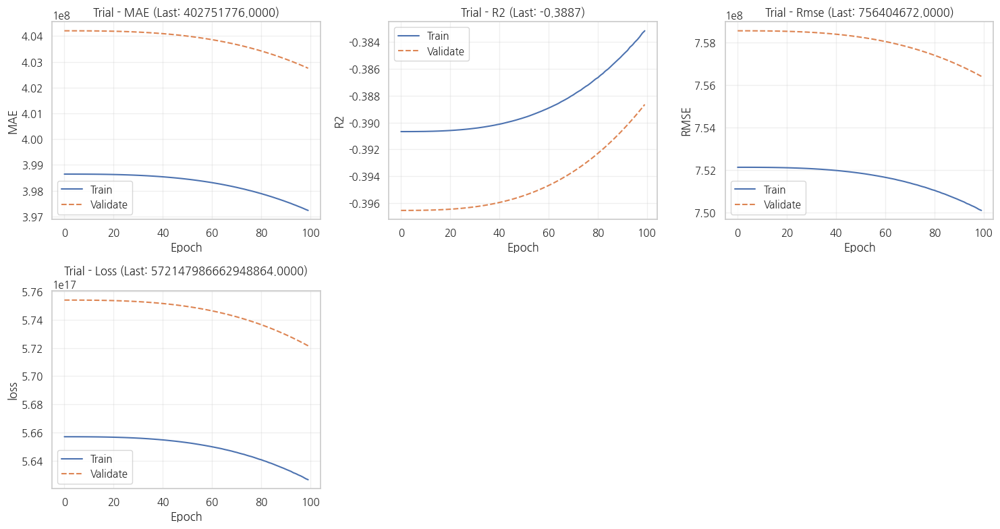

Training Progress: 100%|██████████| 100/100 [00:49<00:00,  2.01it/s]


   [Save] CNN Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_CNN_20261015_045319.keras
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_CNN_20261015_045319.json
Performance: 
   [Info] CNN (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


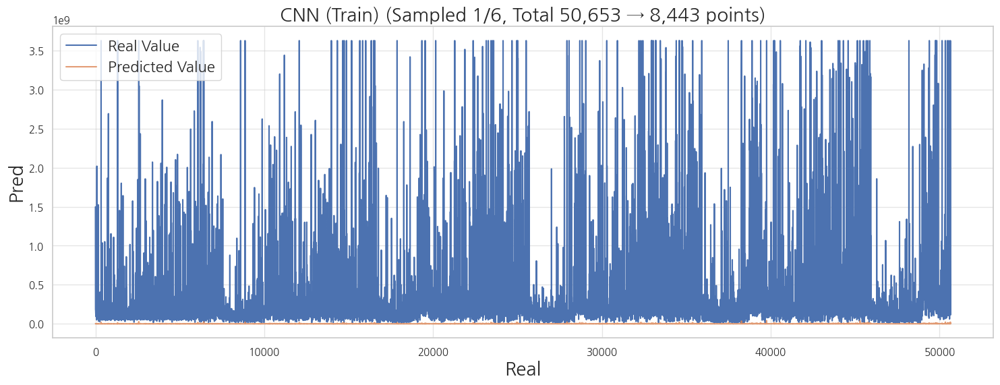

   [Info] CNN (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


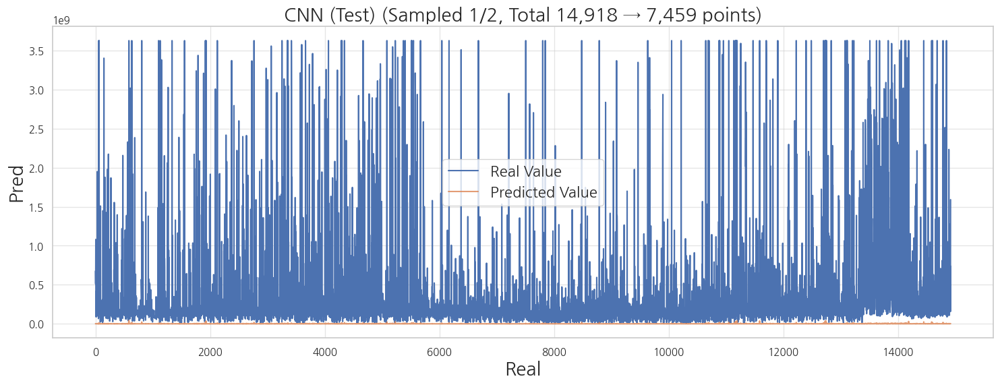

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CNN,Train set,"751,335,867.7328",0.9851,"398,325,646.2557",0.9925,"147,563,574.8750",0.9943,-0.3842
1,CNN,Validation(CV),"756,404,588.1554",0.9852,"402,751,763.4439",0.9925,"149,161,563.1875",0.9944,-0.3887
2,CNN,Test set,"721,422,212.9235",0.9815,"368,288,951.3357",0.9906,"158,668,740.0625",0.9933,-0.3451
3,CNN,Entire population,"744,635,844.5336",0.9843,"391,492,024.4592",0.9921,"150,281,267.1250",0.9941,-0.3751



   Running Deep Learning Algorithm: TabNet (regression)
[Info] Starting Hyperparameter Optimization (Trials: 50)...


  0%|          | 0/50 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 1.8591711878786356e-05, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.2192861223398122, 'batch_size': 4096, 'optimizer': 'adamw', 'learning_rate': 0.001196267211457031, 'batch_size_tabnet': 1024, 'n_d': 8, 'n_steps': 3, 'gamma': 1.2174856185555318, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:07<01:04,  1.38it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 1] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 0.000679954816712657, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.12522768269825335, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.0008434399996112296, 'batch_size_tabnet': 4096, 'n_d': 16, 'n_steps': 4, 'gamma': 1.3343746210248852, 'n_independent': 2, 'n_shared': 2, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:08<01:05,  1.35it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 2] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 1, 'l2_regularization': 0.0004528772229928237, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.07653525756238655, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.000404769467477543, 'batch_size_tabnet': 4096, 'n_d': 16, 'n_steps': 4, 'gamma': 1.3372707666248884, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:07<00:57,  1.56it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 3] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 9.245743043318098e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.17713233779583926, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.004777153774783566, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 3, 'gamma': 1.3257436171699126, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:13<00:00,  1.35it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7531028518364774e+17


  ▶ [Trial 4] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 4.107982441392344e-06, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.22870599876180597, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.00030677298838084854, 'batch_size_tabnet': 2048, 'n_d': 16, 'n_steps': 3, 'gamma': 1.27528575375089, 'n_independent': 2, 'n_shared': 2, 'mask_type': 'entmax'}


Training Progress:  11%|█         | 11/100 [00:07<01:03,  1.41it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 5] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.00017985891383109638, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.06920778639079489, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0023586461035248834, 'batch_size_tabnet': 4096, 'n_d': 32, 'n_steps': 3, 'gamma': 1.367353578903784, 'n_independent': 1, 'n_shared': 2, 'mask_type': 'entmax'}


Training Progress:  19%|█▉        | 19/100 [00:10<00:44,  1.83it/s]



Early stopping occurred at epoch 18 with best_epoch = 8 and best_val_mse = 5.753951880971551e+17
  ▶ [Trial 6] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 0.0009733274734977057, 'batch_normalization': True, 'hidden_activation': 'gelu', 'dropout': 0.3961496509222953, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.002732342886692697, 'batch_size_tabnet': 4096, 'n_d': 32, 'n_steps': 3, 'gamma': 1.2854610899542065, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'entmax'}


Training Progress: 100%|██████████| 100/100 [00:56<00:00,  1.76it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753925767570391e+17


  ▶ [Trial 7] Params: {'scaler_type': 'None', 'n_layers': 1, 'l2_regularization': 8.050827266423532e-06, 'batch_normalization': True, 'hidden_activation': 'swish', 'dropout': 0.18759276374139905, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0005665893751607918, 'batch_size_tabnet': 1024, 'n_d': 8, 'n_steps': 3, 'gamma': 1.206762325916454, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:07<01:04,  1.38it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 8] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 1, 'l2_regularization': 8.004363514526591e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.2987165541801875, 'batch_size': 2048, 'optimizer': 'adam', 'learning_rate': 0.00011966706041639411, 'batch_size_tabnet': 2048, 'n_d': 16, 'n_steps': 4, 'gamma': 1.2423830671894458, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:07<01:04,  1.39it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 9] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 3, 'l2_regularization': 1.0549030363692302e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.11273168015297996, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.004083685950129219, 'batch_size_tabnet': 1024, 'n_d': 16, 'n_steps': 3, 'gamma': 1.2627115573895475, 'n_independent': 1, 'n_shared': 2, 'mask_type': 'entmax'}


Training Progress: 100%|██████████| 100/100 [01:13<00:00,  1.35it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 97 and best_val_mse = 5.7536364585733325e+17


  ▶ [Trial 10] Params: {'scaler_type': 'RobustScaler', 'n_layers': 3, 'l2_regularization': 4.026207846146485e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.1514220629196379, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0043504424120855735, 'batch_size_tabnet': 2048, 'n_d': 32, 'n_steps': 3, 'gamma': 1.303021407628249, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [00:55<00:00,  1.81it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.753811006044242e+17


  ▶ [Trial 11] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 1.3848818808961958e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.13294504151348302, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.003378491082139844, 'batch_size_tabnet': 1024, 'n_d': 16, 'n_steps': 3, 'gamma': 1.3510234584585954, 'n_independent': 1, 'n_shared': 2, 'mask_type': 'entmax'}


Training Progress: 100%|██████████| 100/100 [01:13<00:00,  1.35it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 97 and best_val_mse = 5.753749845709947e+17


  ▶ [Trial 12] Params: {'scaler_type': 'None', 'n_layers': 2, 'l2_regularization': 1.1645355260794739e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.04940550176485009, 'batch_size': 2048, 'optimizer': 'sgd', 'learning_rate': 0.0019023162274417358, 'batch_size_tabnet': 1024, 'n_d': 16, 'n_steps': 3, 'gamma': 1.4018123466431969, 'n_independent': 2, 'n_shared': 2, 'mask_type': 'entmax'}


Training Progress: 100%|██████████| 100/100 [01:24<00:00,  1.19it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753884879481733e+17


  ▶ [Trial 13] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.123311932666567e-05, 'batch_normalization': False, 'hidden_activation': 'selu', 'dropout': 0.25840942422975205, 'batch_size': 2048, 'optimizer': 'adam', 'learning_rate': 0.0030293676487569434, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 3, 'gamma': 1.2895924162458376, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:03<00:00,  1.58it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.7536223710806016e+17


  ▶ [Trial 14] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.1346421945571646e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.3040489145964546, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.004598124852117294, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4084991753386764, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:08<00:00,  1.46it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753087389954212e+17


  ▶ [Trial 15] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 5.610649317194702e-05, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.12111628780069653, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0033941450802018034, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.2891880391878063, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7534186178320794e+17


  ▶ [Trial 16] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.126775629790559e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.36687609416108546, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.003813468143609143, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.442063769568674, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7532918303975014e+17


  ▶ [Trial 17] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 2.886562032703009e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.31227193613467225, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0011821788952793442, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4312820110036402, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.75390515172737e+17


  ▶ [Trial 18] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 4.746796141013822e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.23326414195884748, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.002430028675161673, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3818309065886467, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'entmax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7537020856736154e+17


  ▶ [Trial 19] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 1, 'l2_regularization': 1.0540822625662106e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.137559853930986, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0012173077185005676, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3530294860503642, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753890377039872e+17


  ▶ [Trial 20] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.4982053432011337e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.29342662696093524, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0024350257254320035, 'batch_size_tabnet': 2048, 'n_d': 32, 'n_steps': 3, 'gamma': 1.4031317445084373, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [00:51<00:00,  1.96it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753897592584929e+17


  ▶ [Trial 21] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.8494886473972352e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4047392996442051, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.0038248218913074753, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3918959552102186, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.7531973411169894e+17


  ▶ [Trial 22] Params: {'scaler_type': 'MinMaxScaler', 'n_layers': 2, 'l2_regularization': 1.2590505181103752e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.49798939081042576, 'batch_size': 1024, 'optimizer': 'sgd', 'learning_rate': 0.00398719100653962, 'batch_size_tabnet': 4096, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4102553236433937, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress:  11%|█         | 11/100 [00:06<00:51,  1.72it/s]



Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_mse = 5.7539532553610854e+17
  ▶ [Trial 23] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 9.841333509001971e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.2008123530688262, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0037836195912355603, 'batch_size_tabnet': 1024, 'n_d': 8, 'n_steps': 4, 'gamma': 1.3666687330225378, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 96 and best_val_mse = 5.7537941697724416e+17


  ▶ [Trial 24] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 6.63174898457621e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.47378018760446683, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0017882350765822464, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4853408801392372, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7537890158116864e+17


  ▶ [Trial 25] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.6072000406991813e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4056544631722145, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.004962351419090811, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3572850221154424, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:19<00:00,  1.26it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.752889477861212e+17


  ▶ [Trial 26] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 6.799209664406517e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4139495649480235, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0038752294229205363, 'batch_size_tabnet': 2048, 'n_d': 16, 'n_steps': 4, 'gamma': 1.2997864303812736, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.51it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753832652679414e+17


  ▶ [Trial 27] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 4.698359856461624e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.026820438822184267, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0016926785609109214, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.403014221545459, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753806882875638e+17


  ▶ [Trial 28] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.3312384438367375e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.11912337500032455, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0022919288570034274, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 3, 'gamma': 1.4606328682615448, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [00:57<00:00,  1.73it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753790733798605e+17


  ▶ [Trial 29] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.2306095951570864e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.2682470807712559, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.004329382940185111, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 3, 'gamma': 1.358039196729779, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [00:58<00:00,  1.72it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.753440264467251e+17


  ▶ [Trial 30] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 2.4053728568202693e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3444972845723977, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0035412430005302277, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.380227667788039, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.75342892575359e+17


  ▶ [Trial 31] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.19415093877564e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.47148994796129456, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.001847094308438617, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4500464881652133, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753818565186683e+17


  ▶ [Trial 32] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 4.180851288372344e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4402889839277491, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.004411669722953465, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3555814491948535, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753049594242007e+17


  ▶ [Trial 33] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.1422770588577367e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.17683633124174347, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.00497985336017121, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4173565529162813, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753049594242007e+17


  ▶ [Trial 34] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.3146521325370742e-05, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.2640692871410579, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.004255599042427495, 'batch_size_tabnet': 4096, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4693807245108679, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [00:51<00:00,  1.95it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7538920950267904e+17


  ▶ [Trial 35] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 2.228227287041198e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.3074446259097239, 'batch_size': 2048, 'optimizer': 'adam', 'learning_rate': 0.0031400036103177978, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3377439727015692, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753561897941074e+17


  ▶ [Trial 36] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.4369432246232093e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.41046814497192513, 'batch_size': 1024, 'optimizer': 'rmsprop', 'learning_rate': 0.0016256116159938, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3308094633608656, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753840899016622e+17


  ▶ [Trial 37] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.9145316596659273e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4300356914625376, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0022162583597842766, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.2867242710758604, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753738163398902e+17


  ▶ [Trial 38] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.1117261407048801e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.2165192359730818, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0026019880263766634, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.466142619007637, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7536728798960026e+17


  ▶ [Trial 39] Params: {'scaler_type': 'RobustScaler', 'n_layers': 2, 'l2_regularization': 3.61778532399567e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.46877604314088533, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.0019167514420331453, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3697475345501298, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753784205448315e+17


  ▶ [Trial 40] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 5.992487756574727e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.45848256212899824, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.003416045461428631, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3663478141505259, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753373950172201e+17


  ▶ [Trial 41] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 5.330877587630056e-06, 'batch_normalization': False, 'hidden_activation': 'relu', 'dropout': 0.3557041223338456, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.004229790848611875, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.373534609770505, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753268465775411e+17


  ▶ [Trial 42] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 9.711372664357914e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.29960393050203105, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0032319712128393062, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3454595513508443, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7534303001431245e+17


  ▶ [Trial 43] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.6742859882671578e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.1974908521784027, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.002803910316563907, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3042715684872377, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753662915571876e+17


  ▶ [Trial 44] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 4.454903383122872e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.1906226545324376, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.0036365951171337726, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 3, 'gamma': 1.2608469097467707, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753501424801546e+17


  ▶ [Trial 45] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 6.9549491795781685e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4833278911913508, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0024275249237092314, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3762068799759213, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753717547555881e+17


  ▶ [Trial 46] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.055328972265507e-05, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4488721027779848, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0014815671223619839, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.388522561326238, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753856017301504e+17


  ▶ [Trial 47] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.55826167228477e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3872117190616312, 'batch_size': 4096, 'optimizer': 'rmsprop', 'learning_rate': 0.0030289274187582527, 'batch_size_tabnet': 2048, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3568785904358618, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.753829903900344e+17


  ▶ [Trial 48] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 4.028576116089262e-06, 'batch_normalization': False, 'hidden_activation': 'gelu', 'dropout': 0.15590745121820554, 'batch_size': 2048, 'optimizer': 'rmsprop', 'learning_rate': 0.003445708885120249, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.4428773687582719, 'n_independent': 1, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 98 and best_val_mse = 5.753505891567534e+17


  ▶ [Trial 49] Params: {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 1.6182001640049066e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.3404425804034384, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.003159228918658044, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.354296055456815, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}


Training Progress: 100%|██████████| 100/100 [01:17<00:00,  1.29it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 97 and best_val_mse = 5.753515855891661e+17


[TabNet] Best Metric Trial:  25
[TabNet] Best Tuning Parameters:  {'scaler_type': 'RobustScaler', 'n_layers': 1, 'l2_regularization': 3.6072000406991813e-06, 'batch_normalization': False, 'hidden_activation': 'swish', 'dropout': 0.4056544631722145, 'batch_size': 4096, 'optimizer': 'sgd', 'learning_rate': 0.004962351419090811, 'batch_size_tabnet': 1024, 'n_d': 32, 'n_steps': 4, 'gamma': 1.3572850221154424, 'n_independent': 2, 'n_shared': 1, 'mask_type': 'sparsemax'}
[TabNet] Best Metric Score:  758478057.235599



Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

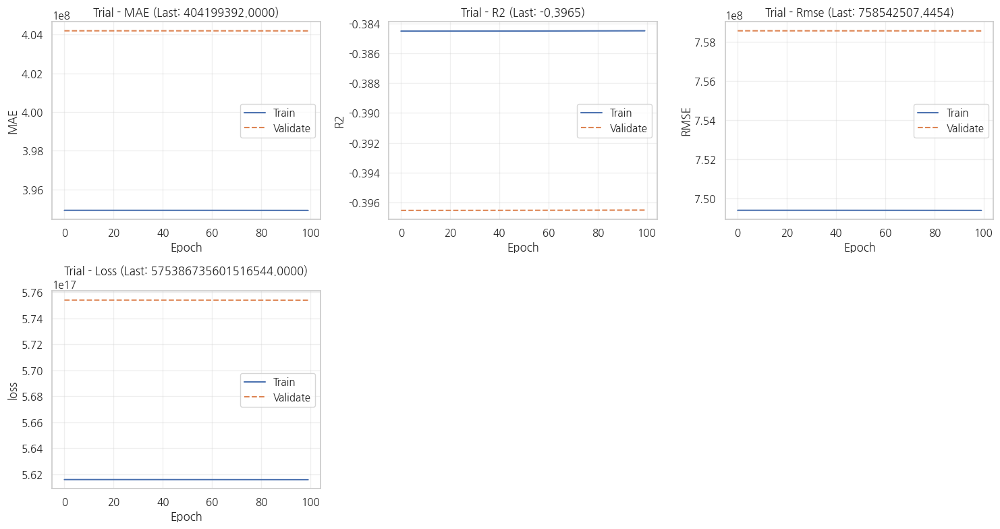

Training Progress: 100%|██████████| 100/100 [01:14<00:00,  1.51it/s]

Stop training because you reached max_epochs = 100 with best_epoch = 99 and best_val_mse = 5.7538673560151654e+17


Training Progress: 100%|██████████| 100/100 [01:15<00:00,  1.33it/s]


Successfully saved model at /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_TabNet_20261015_054758.zip
   [Save] TabNet Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_model_TabNet_20261015_054758.zip
     - Params: /workspace/DataScience/DIVE/Project/PublicProcurement/Model/best_params_TabNet_20261015_054758.json
Performance: 
   [Info] TabNet (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


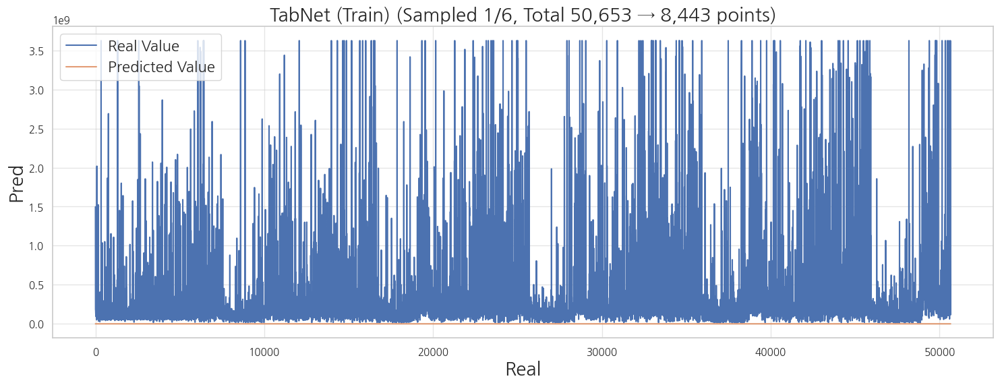

   [Info] TabNet (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


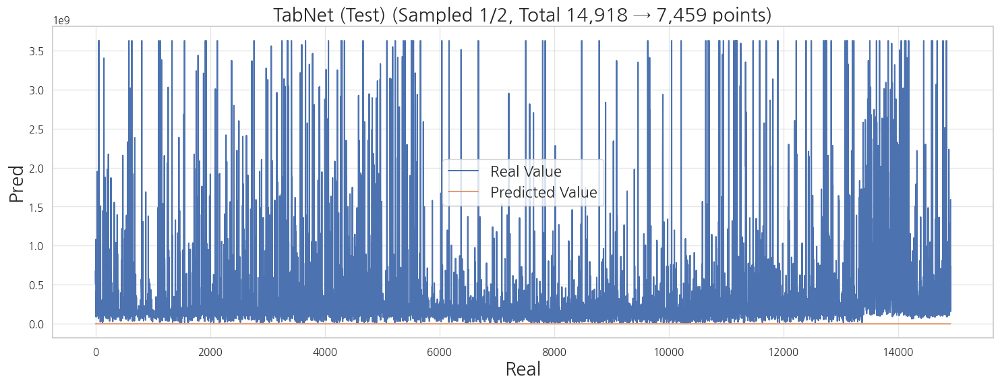

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,TabNet,Train set,"753,408,400.1384",1.0000,"399,751,961.5678",1.0000,"148,390,631.3579",1.0000,-0.3918
1,TabNet,Validation(CV),"758,542,525.3122",1.0000,"404,199,390.9602",1.0000,"149,996,945.5894",1.0000,-0.3965
2,TabNet,Test set,"723,705,023.7400",1.0000,"369,892,539.1090",1.0000,"159,759,341.8805",1.0000,-0.3536
3,TabNet,Entire population,"746,754,442.1384",1.0000,"392,958,670.8716",1.0000,"151,188,263.0591",1.0000,-0.3829



   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,MLP,Train set,236745489.1416,0.2453,63395167.8069,0.2012,18528856.0000,0.1230,0.8626
4,CNN,Train set,751335867.7328,0.9851,398325646.2557,0.9925,147563574.8750,0.9943,-0.3842
8,TabNet,Train set,753408400.1384,1.0000,399751961.5678,1.0000,148390631.3579,1.0000,-0.3918


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,MLP,Validation(CV),263144201.1278,0.2497,66044018.1006,0.2022,18751600.0000,0.1235,0.8319
5,CNN,Validation(CV),756404588.1554,0.9852,402751763.4439,0.9925,149161563.1875,0.9944,-0.3887
9,TabNet,Validation(CV),758542525.3122,1.0000,404199390.9602,1.0000,149996945.5894,1.0000,-0.3965


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,MLP,Test set,291800369.0055,0.3561,63428082.8122,0.2288,15569554.0000,0.0894,0.7799
6,CNN,Test set,721422212.9235,0.9815,368288951.3357,0.9906,158668740.0625,0.9933,-0.3451
10,TabNet,Test set,723705023.7400,1.0000,369892539.1090,1.0000,159759341.8805,1.0000,-0.3536


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,MLP,Entire population,250337214.2157,0.2705,63402656.2705,0.2075,17760172.0000,0.1149,0.8446
7,CNN,Entire population,744635844.5336,0.9843,391492024.4592,0.9921,150281267.1250,0.9941,-0.3751
11,TabNet,Entire population,746754442.1384,1.0000,392958670.8716,1.0000,151188263.0591,1.0000,-0.3829


Saved total performance to: /workspace/DataScience/DIVE/Project/PublicProcurement/Result/Performance_DL(Trial50).csv


In [78]:
# DL Modeling
results_DL, scores_DL = modeling_DL(
    algos=ALGO_NAMES_DL,
    X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test,
    task=TASK,
    class_weight_method=CLASS_WEIGHT_METHOD,
    node_list=None, # 특정 알고리즘
    validation_split=VALIDATION_SPLIT,
    validation_data=VALIDATION_DATA,
    tune_trials=TUNE_TRIALS_DL, # 최적화 여부
    cv_splits=CV_SPLITS,
    tune_metric=TUNE_METRIC_DL,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    earlystop_patient=None,
    label_list=LABEL_LIST,
    random_state=RANDOM_STATE,
)


## Performance

### Summary

In [79]:
# Result Summary
folder_location = os.path.join(os.getcwd(),'Result')
df_scores = prediction_summary(
    folder_location=folder_location, 
    algonames=ALGO_NAMES_ML + ALGO_NAMES_DL,
    save_name=SAVE_NAME_PERFORMANCE,
)

### Performance Summary : 8 Algorithms ###

>>> [Train set] Performance Comparison


,Algorithm,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,581442805.0880,37.7672,503620763.1186,4.0859,412890834.0000,2.9212,0.1710
1,Random Forest,27891388.5496,0.0039,8947129.4876,0.0221,1354544.0000,0.0095,0.9981
2,XGBoost,12118109.1354,0.0012,4242248.7317,0.0146,1154408.0000,0.0074,0.9996
3,LightGBM,15388689.9741,0.0023,5574992.3231,0.0188,1343920.8765,0.0087,0.9994
4,CatBoost,17840709.7638,0.0032,7946513.2228,0.0299,2944660.7556,0.0187,0.9992
5,MLP,236745489.1416,0.2453,63395167.8069,0.2012,18528856.0000,0.1230,0.8626
6,CNN,751335867.7328,0.9851,398325646.2557,0.9925,147563574.8750,0.9943,-0.3842
7,TabNet,753408400.1384,1.0000,399751961.5678,1.0000,148390631.3579,1.0000,-0.3918



>>> [Validation(CV)] Performance Comparison


,Algorithm,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,433555081.7842,17.8616,328350404.3811,2.6208,278149568.0000,1.7439,0.5391
1,Random Forest,32637466.7796,0.0062,10516327.3555,0.0266,1575344.0000,0.0111,0.9974
2,XGBoost,21461620.5635,0.0032,6858669.4026,0.0205,1369313.0000,0.0091,0.9989
3,CatBoost,25966526.5638,0.0055,9652149.4123,0.0327,3023600.0000,0.0196,0.9983
4,MLP,263144201.1278,0.2497,66044018.1006,0.2022,18751600.0000,0.1235,0.8319
5,CNN,756404588.1554,0.9852,402751763.4439,0.9925,149161563.1875,0.9944,-0.3887
6,TabNet,758542525.3122,1.0000,404199390.9602,1.0000,149996945.5894,1.0000,-0.3965



>>> [Test set] Performance Comparison


,Algorithm,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,593632256.8612,49.7489,497980438.8641,4.3455,464201842.0000,2.9372,0.0893
1,Random Forest,56470287.0029,0.1351,24653287.0109,0.1590,15956788.0000,0.0586,0.9918
2,XGBoost,38686740.5682,0.0080,12324947.0424,0.0386,2823998.0000,0.0180,0.9961
3,LightGBM,37325241.2144,0.0066,10381544.9636,0.0294,1572678.7339,0.0102,0.9964
4,CatBoost,63162233.2501,0.5575,41370438.6153,0.3591,35795103.6368,0.0883,0.9897
5,MLP,291800369.0055,0.3561,63428082.8122,0.2288,15569554.0000,0.0894,0.7799
6,CNN,721422212.9235,0.9815,368288951.3357,0.9906,158668740.0625,0.9933,-0.3451
7,TabNet,723705023.7400,1.0000,369892539.1090,1.0000,159759341.8805,1.0000,-0.3536



>>> [Entire population] Performance Comparison


,Algorithm,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,584238364.9588,40.4931,502337537.9546,4.1450,436988600.0000,2.9263,0.1535
1,Random Forest,36420403.3437,0.0338,12520423.4428,0.0533,2149296.0000,0.0127,0.9967
2,XGBoost,21305958.2213,0.0028,6081136.2490,0.0201,1394120.0000,0.0087,0.9989
3,LightGBM,22358323.6772,0.0032,6668526.8473,0.0212,1392209.5373,0.0090,0.9988
4,CatBoost,33963467.0788,0.1293,15550760.8171,0.1048,3770892.2950,0.0225,0.9971
5,MLP,250337214.2157,0.2705,63402656.2705,0.2075,17760172.0000,0.1149,0.8446
6,CNN,744635844.5336,0.9843,391492024.4592,0.9921,150281267.1250,0.9941,-0.3751
7,TabNet,746754442.1384,1.0000,392958670.8716,1.0000,151188263.0591,1.0000,-0.3829


### Significance Test

In [80]:
# Statistical Test
df_significance, cv_scores = evaluation_MetricSignificance(
    scores=df_scores, 
    Y_train=Y_train, 
    X_train=X_train, 
    task=TASK, target_metric=METRIC_FINAL,
    cv_type=TEST_SIZE
)


★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261015_021403.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: Random Forest
   - File: best_model_Random Forest_20261015_023703.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: XGBoost
   - File: best_model_XGBoost_20261015_025644.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: LightGBM
   - File: best_model_LightGBM_20261015_030425.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: CatBoost
   - File: best_model_CatBoost_20261015_031431

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,5524461086555.0693 ± 16572080371478.9102,+5524359152472.0869,37.923,***,0.0000,593632256.8612
1,Random Forest (Best),101934082.9828 ± 92583013.4122,-,-,-,Benchmark,56470287.0029
2,XGBoost,152098326.9532 ± 247626359.3235,+50164243.9704,25.179,***,0.0000,38686740.5682
3,LightGBM,153967942.2692 ± 251017573.1162,+52033859.2864,25.536,***,0.0000,37325241.2144
4,CatBoost,112643423.8837 ± 169064239.0629,+10709340.9009,10.505,***,0.0000,63162233.2501
5,MLP,382854704.8032 ± 135209495.9820,+280920621.8204,7.401,***,0.0000,291800369.0055
6,CNN,764911736.5548 ± 111636487.5707,+662977653.5720,58.737,***,0.0000,721422212.9235
7,TabNet,765417489.1569 ± 111989498.6414,+663483406.1741,58.726,***,0.0000,723705023.7400


### Best Model Prediction

▶ [Auto-Detected Table]: Prediction Summary df_scores (Holdout Test set)
▶ Selected Best Algorithm: [ LightGBM ] (Task: REGRESSION)
▶ Searching Directory: /workspace/DataScience/DIVE/Project/PublicProcurement/Model
Loading Model: LightGBM
   - File: best_model_LightGBM_20261015_030425.pkl
   - Successfully Loaded.
[LightGBM] 모델 내부 변수명이 성공적으로 수정되었습니다.
Performance: 
   [Info] LightGBM (Train): Data too large. Plotting every 6-th point. (Sampled 1/6, Total 50,653 → 8,443 points)


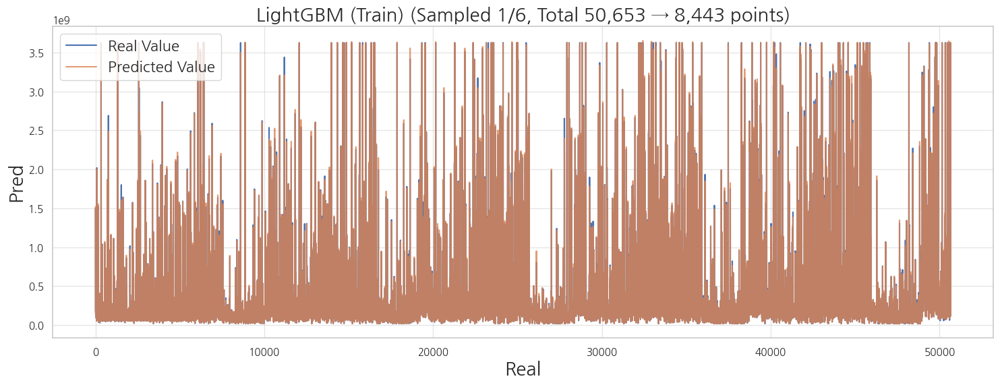

   [Info] LightGBM (Test): Data too large. Plotting every 2-th point. (Sampled 1/2, Total 14,918 → 7,459 points)


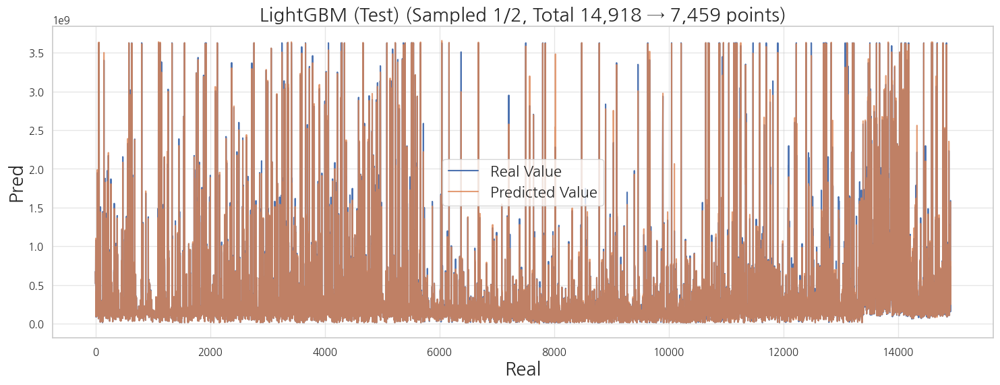

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,"15,388,689.9741",0.0023,"5,574,992.3231",0.0188,"1,343,920.8765",0.0087,0.9994
1,LightGBM,Test set,"37,325,241.2144",0.0066,"10,381,544.9636",0.0294,"1,572,678.7339",0.0102,0.9964
2,LightGBM,Entire population,"22,358,323.6772",0.0032,"6,668,526.8473",0.0212,"1,392,209.5373",0.0090,0.9988


Saved: ./Result/Screening_Report_LGBMRegressor.csv


,Feature,Feature Importance (Gini/Gain/Mask),Importance (%),Cumulative Importance (%)
0,model_row_id,2181,9.1523,9.1523
1,notice_status_등록공고,2155,9.0432,18.1956
2,estimated_price_krw,2032,8.5271,26.7226
3,base_amount_krw,1984,8.3256,35.0483
4,service_field_기술용역,1954,8.1997,43.2480
5,procurement_method_자체조달,1938,8.1326,51.3806
6,notice_month,1802,7.5619,58.9425
7,budget_krw,1615,6.7772,65.7197
8,contract_method_일반경쟁,1240,5.2035,70.9232
9,industry_restriction_N,1009,4.2342,75.1574


In [81]:
# Best Result
BEST_ALGO, BEST_MODEL, BEST_PARAMS, BEST_TESTSCORE, BEST_PREDIMPORTANCE = prediction_best(
    df_scores=df_scores,
    # df_scores=df_significance,
    X_train=locals().get('X_train_ablation', X_train), Y_train=Y_train, 
    X_test=locals().get('X_test_ablation', X_test), Y_test=Y_test,
    target_metric=METRIC_FINAL, task=TASK,
    folder_name=locals().get('model_folder', 'Model')
)


### Subgroup Robustness

In [ ]:
target_group = 'num__fe_Scope1_2_매출집약도'
# groups = {f"{target_group}_{val}": val for val in sorted(X_test[target_group].dropna().unique())}
groups = {
    '1': lambda x: x < 0,
    '2': lambda x: x>= 0
}
key_features=None

df_fairness = evaluation_reg_GroupFairness(
    best_model=BEST_MODEL,
    target_col=target_group,
    groups_dict=groups,
    X_test=X_test, Y_test=Y_test, X_colname=X_colname,
)

# Modeling with Feature Ablation

## Learning + Significance Test

In [5]:
# Feature Blocks
def sanitize_col(col):
    c = str(col).replace(' ', '_')
    return re.sub(r'[",\[\]{}:<>\'\\]', '_', c)

FEATURE_BLOCKS_CLEAN = {
    b_name: [sanitize_col(c) for c in cols]
    for b_name, cols in FEATURE_BLOCKS.items()
}
model_configs = {
    'Model A (Financial)': FEATURE_BLOCKS_CLEAN['Block1_Financial_Control'],
    'Model A+B (Financial + Carbon)': (
         FEATURE_BLOCKS_CLEAN['Block1_Financial_Control']
         + FEATURE_BLOCKS_CLEAN['Block2_Carbon_Risk']
    ),
    'Model A+C (Financial + ESG)': (
         FEATURE_BLOCKS_CLEAN['Block1_Financial_Control']
         + FEATURE_BLOCKS_CLEAN['Block3_Social_Governance']
    ),
    'Model A+D (Financial + Macro)': (
         FEATURE_BLOCKS_CLEAN['Block1_Financial_Control']
         + FEATURE_BLOCKS_CLEAN['Block4_Industry_Macro']
    ),
    'Model A+B+C (Financial + Carbon + ESG)': (
         FEATURE_BLOCKS_CLEAN['Block1_Financial_Control']
         + FEATURE_BLOCKS_CLEAN['Block2_Carbon_Risk']
         + FEATURE_BLOCKS_CLEAN['Block3_Social_Governance']
    ),
    'Model A+B+C+D (Financial + Carbon + ESG + Macro)': (
         FEATURE_BLOCKS_CLEAN['Block1_Financial_Control']
         + FEATURE_BLOCKS_CLEAN['Block2_Carbon_Risk']
         + FEATURE_BLOCKS_CLEAN['Block3_Social_Governance']
         + FEATURE_BLOCKS_CLEAN['Block4_Industry_Macro']
    ),
}


################################################################################
 ▶ Processing Feature Block: [ Model A (Financial) ]
################################################################################
▷ Valid Features: 141 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-13 23:47:52.961230


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 11] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 12] Params: {'fit_intercept': False, 'scaler_type': 'R

,Features,Coef,Features,Coef
0,missing__missingindicator_기말시가총액,5.0000,missing__missingindicator_기말시가총액_보통주우선주,-6.2812
1,missing__missingindicator_영업활동으로인한현금흐름_연결,3.9062,missing__missingindicator_상장주식수_보통주,-3.4531
2,missing__missingindicator_기말종가수정,3.4453,missing__missingindicator_평균시가총액_보통주우선주,-2.7422
3,missing__missingindicator_매출총이익손실_연결,2.4531,missing__missingindicator_수익_연결,-2.3555
4,missing__missingindicator_유형자산계_연결,2.3320,missing__missingindicator_판매비와관리비_연결,-2.3125
5,missing__missingindicator_fe_signed_log1p_평균시가총액,2.2656,missing__missingindicator_비유동자산계_연결,-1.6641
6,missing__missingindicator_기말종가,2.0312,missing__missingindicator_법인세비용차감전계속영업이익손실_연결,-1.5859
7,missing__missingindicator_자산총계_연결,1.7422,missing__missingindicator_fe_현금_자산,-1.5098
8,missing__missingindicator_fe_유동자산_유동부채,1.4707,missing__missingindicator_fe_재고자산비중,-1.5078
9,missing__missingindicator_재고자산계_연결,1.4688,missing__missingindicator_당좌비율,-1.2681


Performance Evaluations...:  2026-10-13 23:49:07.084310
Performance: 


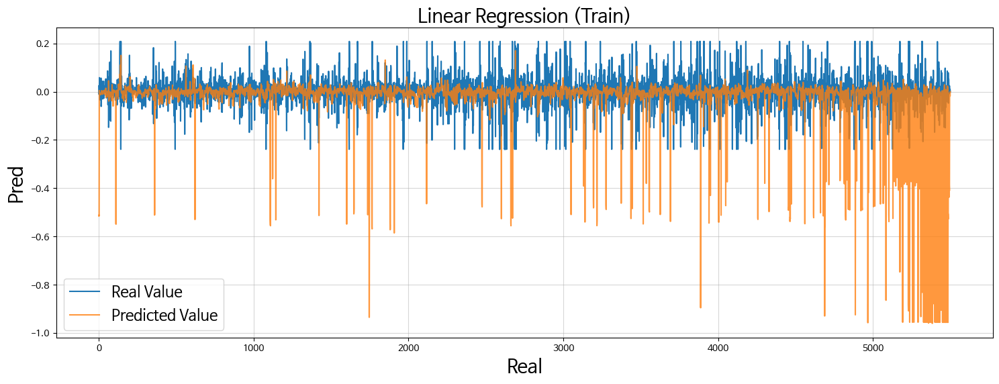

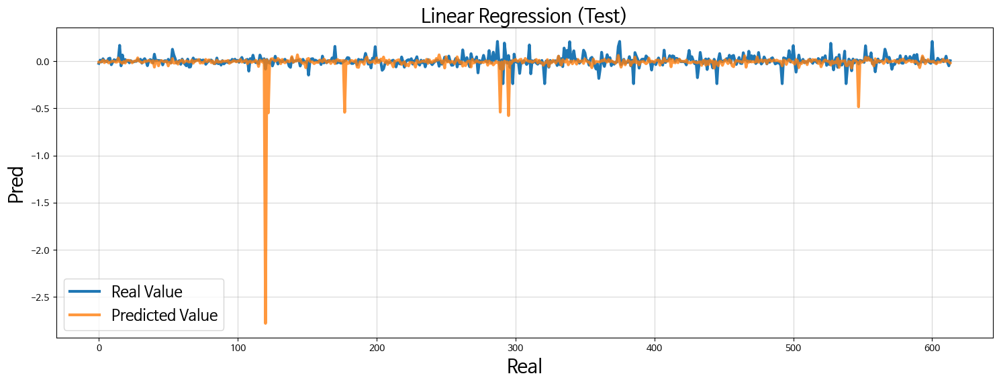

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,0.1303,0.0170,0.0602,0.0602,0.0272,0.0272,-3.6992
1,Linear Regression,Validation(CV),0.0665,0.0044,0.0391,0.0391,0.0219,0.0219,-0.1983
2,Linear Regression,Test set,0.1319,0.0174,0.0459,0.0459,0.0237,0.0237,-5.0502
3,Linear Regression,Entire population,0.1305,0.0170,0.0588,0.0588,0.0269,0.0269,-3.8080


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_model_Linear Regression_20261013_234907.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_params_Linear Regression_20261013_234907.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-13 23:49:07.615417


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

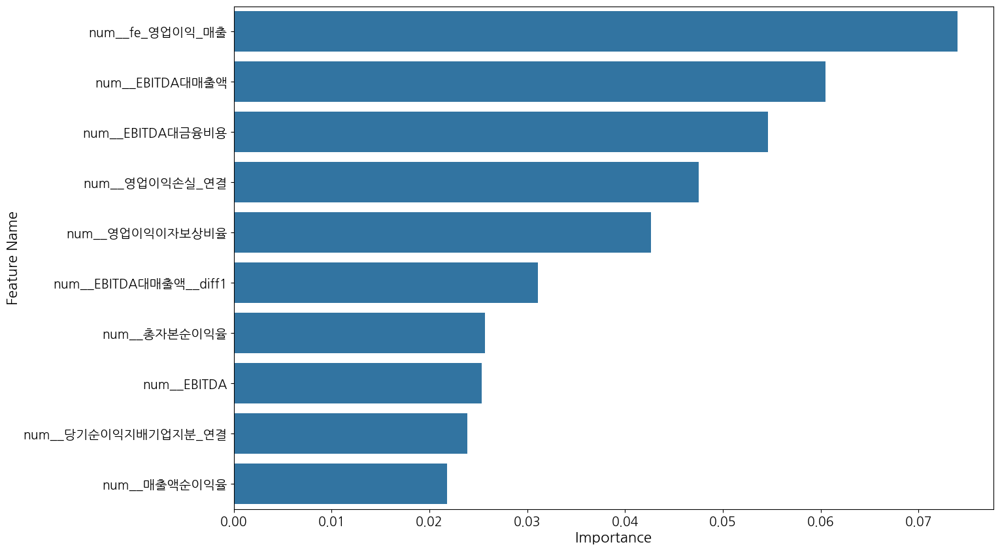

Performance Evaluations...:  2026-10-13 23:51:29.741434
Performance: 


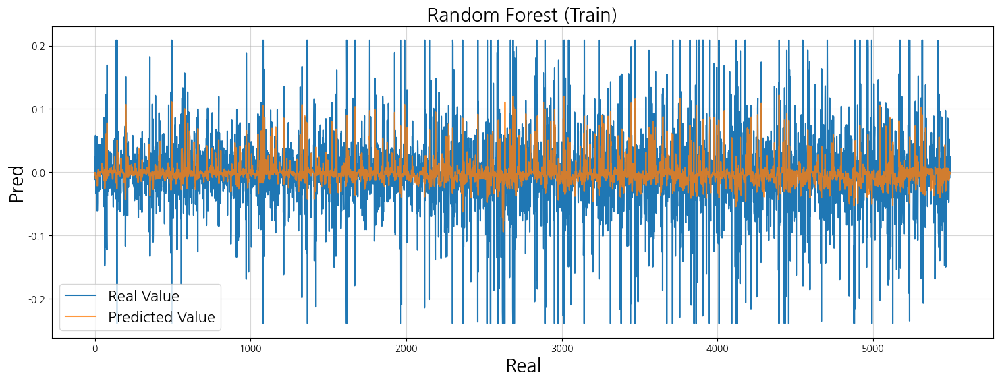

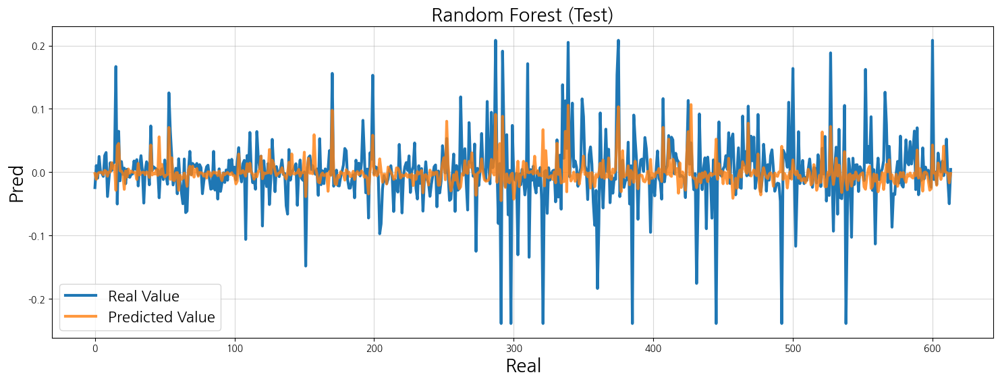

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0519,0.0027,0.0334,0.0334,0.0197,0.0197,0.2563
1,Random Forest,Validation(CV),0.0568,0.0032,0.0351,0.0351,0.0188,0.0188,0.1270
2,Random Forest,Test set,0.0500,0.0025,0.0307,0.0307,0.0177,0.0177,0.1301
3,Random Forest,Entire population,0.0517,0.0027,0.0332,0.0332,0.0195,0.0195,0.2462


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_model_Random Forest_20261013_235130.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_params_Random Forest_20261013_235130.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-13 23:51:30.596152


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

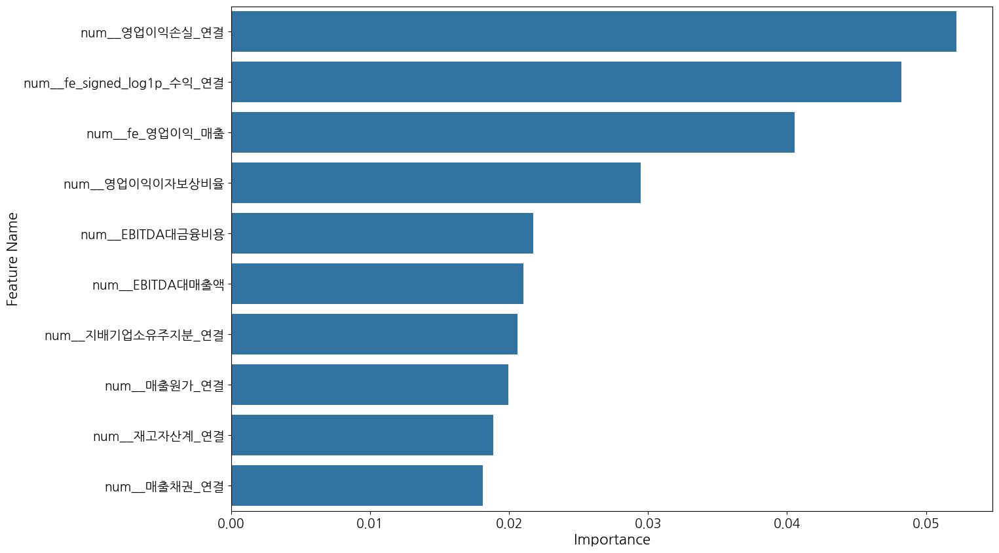

Performance Evaluations...:  2026-10-13 23:53:04.126353
Performance: 


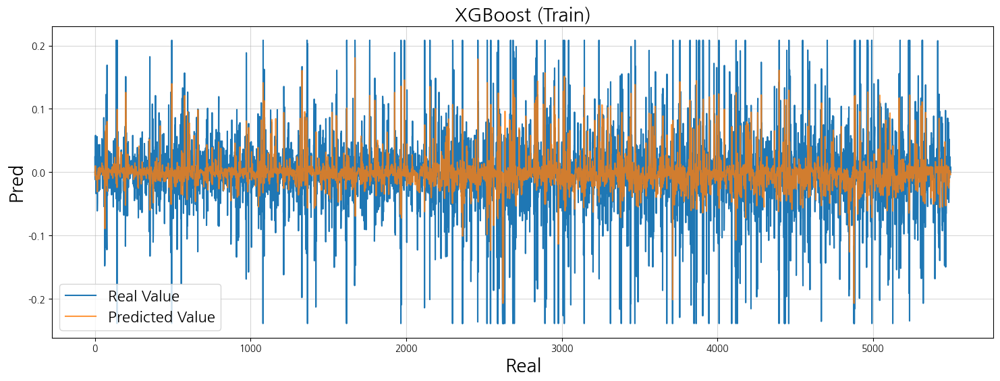

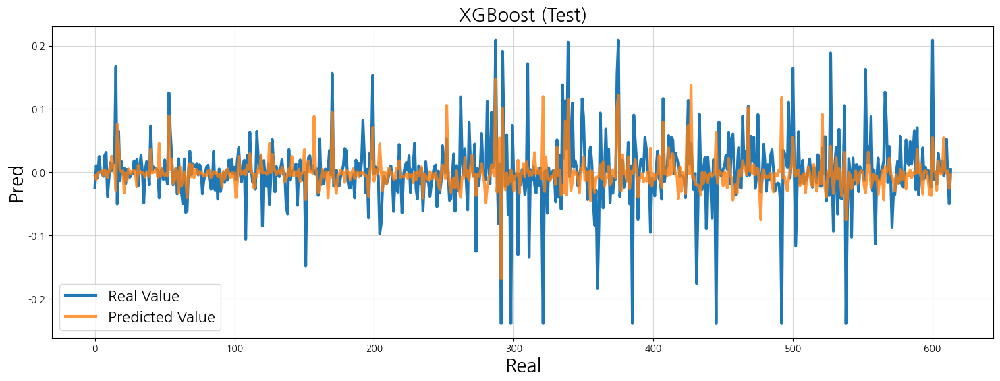

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0475,0.0023,0.0313,0.0313,0.0195,0.0195,0.3762
1,XGBoost,Validation(CV),0.0567,0.0032,0.0355,0.0355,0.0196,0.0196,0.1305
2,XGBoost,Test set,0.0510,0.0026,0.0310,0.0310,0.0182,0.0182,0.0955
3,XGBoost,Entire population,0.0478,0.0023,0.0312,0.0312,0.0194,0.0194,0.3535


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_model_XGBoost_20261013_235304.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_params_XGBoost_20261013_235304.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-13 23:53:04.772577


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

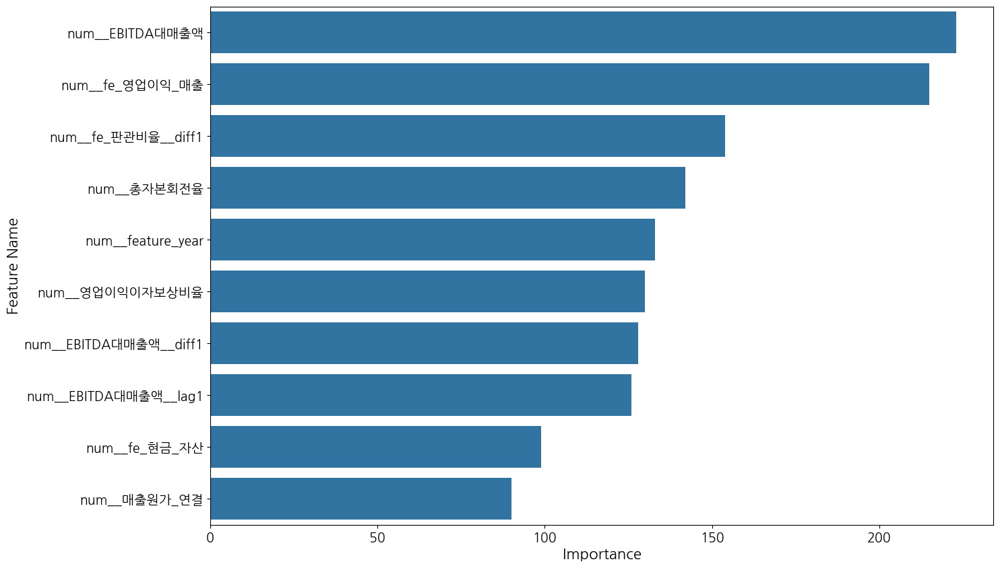

Performance Evaluations...:  2026-10-13 23:54:47.802167
Performance: 


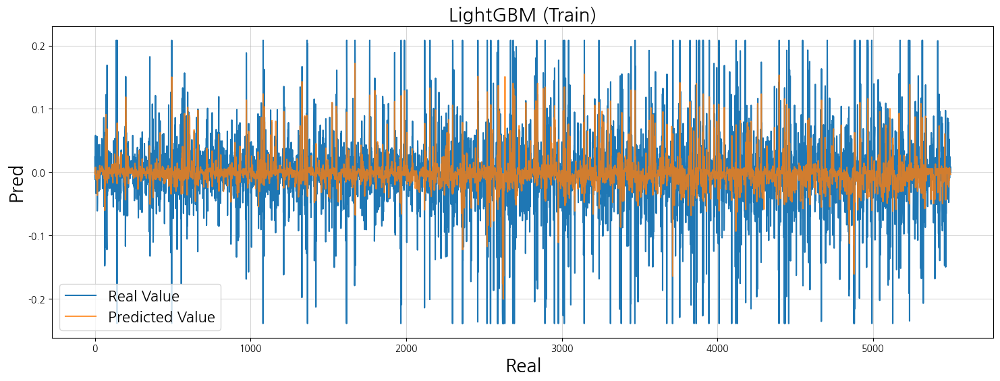

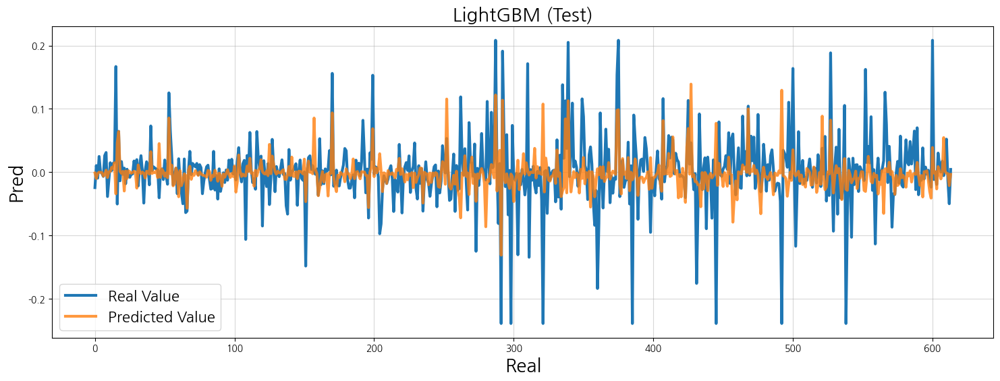

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0486,0.0024,0.0319,0.0319,0.0196,0.0196,0.3465
1,LightGBM,Validation(CV),0.0569,0.0032,0.0356,0.0356,0.0197,0.0197,0.1238
2,LightGBM,Test set,0.0523,0.0027,0.0316,0.0316,0.0182,0.0182,0.0491
3,LightGBM,Entire population,0.0490,0.0024,0.0319,0.0319,0.0194,0.0194,0.3225


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_model_LightGBM_20261013_235448.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_params_LightGBM_20261013_235448.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-13 23:54:48.737933


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

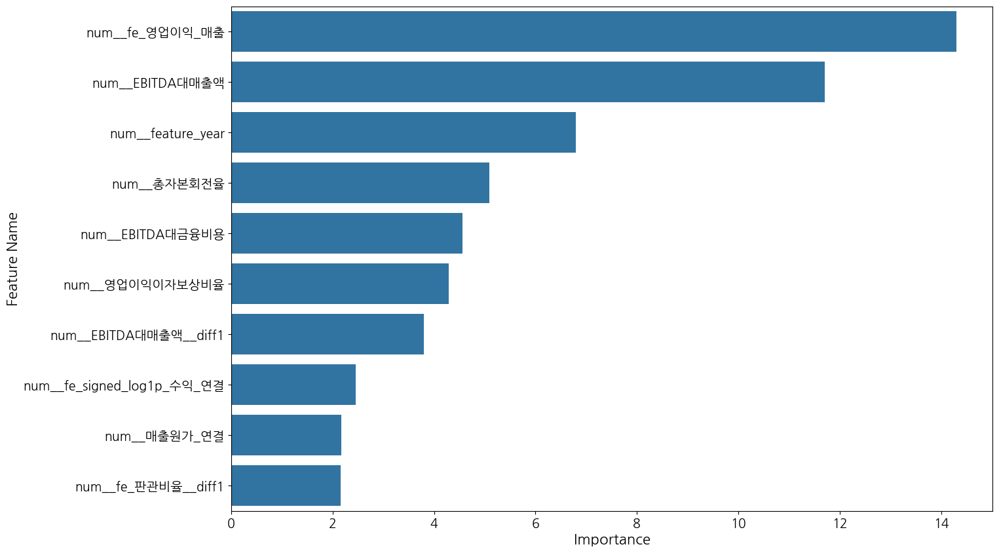

Performance Evaluations...:  2026-10-13 23:57:07.100260
Performance: 


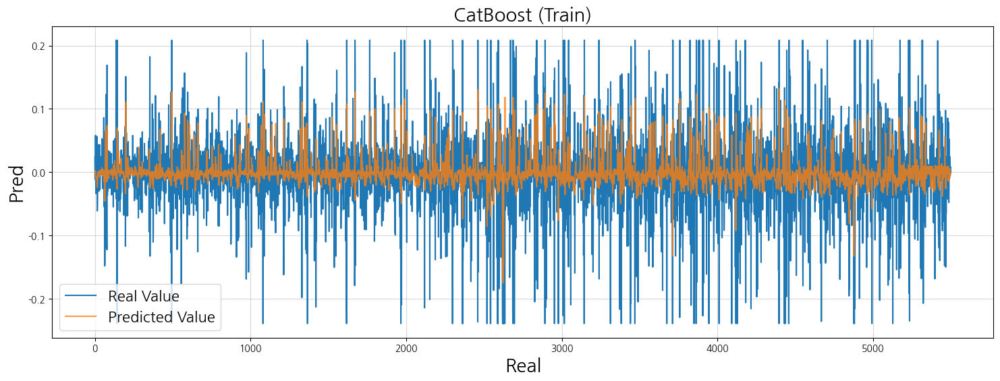

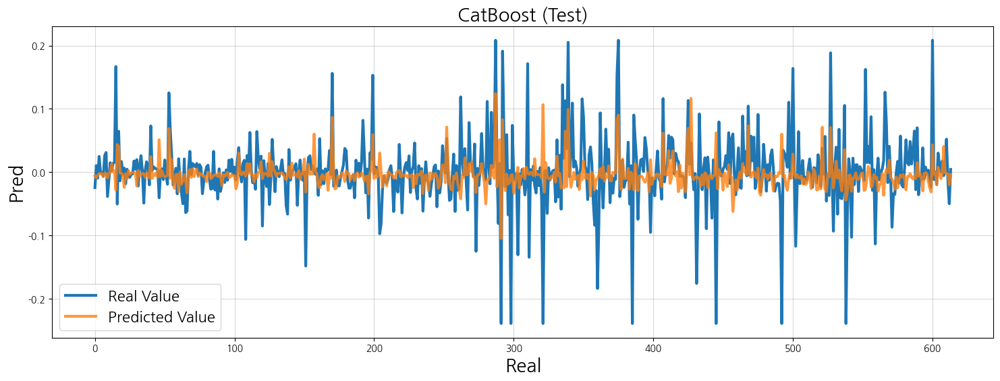

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0512,0.0026,0.0335,0.0335,0.0201,0.0201,0.2742
1,CatBoost,Validation(CV),0.0571,0.0033,0.0359,0.0359,0.0198,0.0198,0.1174
2,CatBoost,Test set,0.0509,0.0026,0.0314,0.0314,0.0179,0.0179,0.0978
3,CatBoost,Entire population,0.0512,0.0026,0.0333,0.0333,0.0197,0.0197,0.2600


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_model_CatBoost_20261013_235708.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/best_params_CatBoost_20261013_235708.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,0.1303,0.0170,0.0602,0.0602,0.0272,0.0272,-3.6992
4,Random Forest,Train set,0.0519,0.0027,0.0334,0.0334,0.0197,0.0197,0.2563
8,XGBoost,Train set,0.0475,0.0023,0.0313,0.0313,0.0195,0.0195,0.3762
12,LightGBM,Train set,0.0486,0.0024,0.0319,0.0319,0.0196,0.0196,0.3465
16,CatBoost,Train set,0.0512,0.0026,0.0335,0.0335,0.0201,0.0201,0.2742


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),0.0665,0.0044,0.0391,0.0391,0.0219,0.0219,-0.1983
5,Random Forest,Validation(CV),0.0568,0.0032,0.0351,0.0351,0.0188,0.0188,0.1270
9,XGBoost,Validation(CV),0.0567,0.0032,0.0355,0.0355,0.0196,0.0196,0.1305
13,LightGBM,Validation(CV),0.0569,0.0032,0.0356,0.0356,0.0197,0.0197,0.1238
17,CatBoost,Validation(CV),0.0571,0.0033,0.0359,0.0359,0.0198,0.0198,0.1174


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,0.1319,0.0174,0.0459,0.0459,0.0237,0.0237,-5.0502
6,Random Forest,Test set,0.0500,0.0025,0.0307,0.0307,0.0177,0.0177,0.1301
10,XGBoost,Test set,0.0510,0.0026,0.0310,0.0310,0.0182,0.0182,0.0955
14,LightGBM,Test set,0.0523,0.0027,0.0316,0.0316,0.0182,0.0182,0.0491
18,CatBoost,Test set,0.0509,0.0026,0.0314,0.0314,0.0179,0.0179,0.0978


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,0.1305,0.0170,0.0588,0.0588,0.0269,0.0269,-3.8080
7,Random Forest,Entire population,0.0517,0.0027,0.0332,0.0332,0.0195,0.0195,0.2462
11,XGBoost,Entire population,0.0478,0.0023,0.0312,0.0312,0.0194,0.0194,0.3535
15,LightGBM,Entire population,0.0490,0.0024,0.0319,0.0319,0.0194,0.0194,0.3225
19,CatBoost,Entire population,0.0512,0.0026,0.0333,0.0333,0.0197,0.0197,0.2600


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A (Financial) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261013_234907.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A__Financial_
Loading Model: Random Forest
   - File: best_model_Random Forest_20261013_235130.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/M

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,0.2429 ± 0.2419,+0.1854,1.973,**,0.0485,0.1319
1,Random Forest,0.0577 ± 0.0112,+0.0001,0.663,ns,0.5072,0.0500
2,XGBoost,0.0581 ± 0.0117,+0.0006,2.156,**,0.0311,0.0510
3,LightGBM,0.0581 ± 0.0115,+0.0006,3.049,***,0.0023,0.0523
4,CatBoost (Best),0.0575 ± 0.0112,-,-,-,Benchmark,0.0509



################################################################################
 ▶ Processing Feature Block: [ Model A+B (Financial + Carbon) ]
################################################################################
▷ Valid Features: 272 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-13 23:57:22.707572


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 11] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 12] Params: {'fit_intercept': False, 'scaler_type': 'Norma

,Features,Coef,Features,Coef
0,missing__missingindicator_fe_signed_log1p_Scope2사업장간접배출량_tCO2e,18.0000,missing__missingindicator_fe_Scope3_매출집약도,-86.0000
1,cat__Scope2사업장간접자료출처_Missing,17.0000,missing__missingindicator_매출대비온실가스직접외부비용비율_pct,-40.0000
2,missing__missingindicator_Scope1직접배출량_tCO2e,15.0000,missing__missingindicator_fe_signed_log1p_Scope1직접배출량_tCO2e,-28.0000
3,missing__missingindicator_fe_signed_log1p_Scope3협력사간접배출량_tCO2e,12.5000,missing__missingindicator_fe_Scope1_매출집약도,-28.0000
4,missing__missingindicator_기말시가총액_보통주우선주,12.0000,missing__missingindicator_fe_Scope1_2_tCO2e,-24.0000
...,...,...,...,...
134,NaN,NaN,num__부채비율,-0.0002
135,NaN,NaN,cat__Scope2사업장간접자료출처_Value_summed_up_from_data_provided_in_Annual_Report/10K/Financial_Accounts_...,-0.0002
136,NaN,NaN,num__fe_배출권_부족량,-0.0001
137,NaN,NaN,num__평균시가총액_보통주우선주,-0.0001


Performance Evaluations...:  2026-10-13 23:58:37.326281
Performance: 


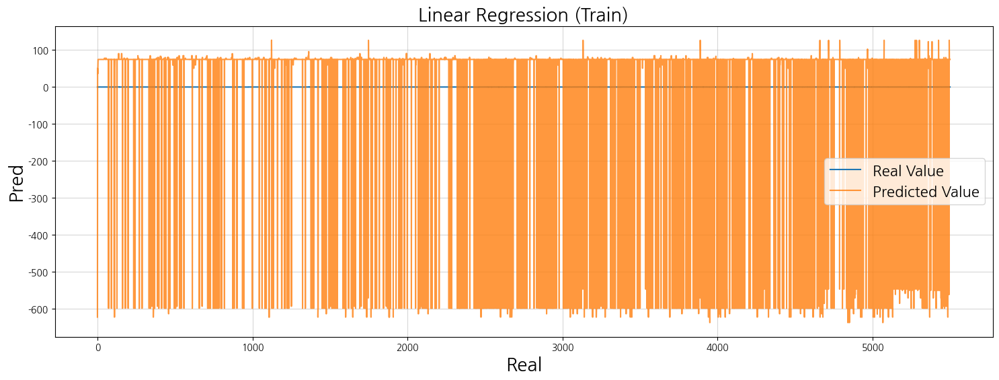

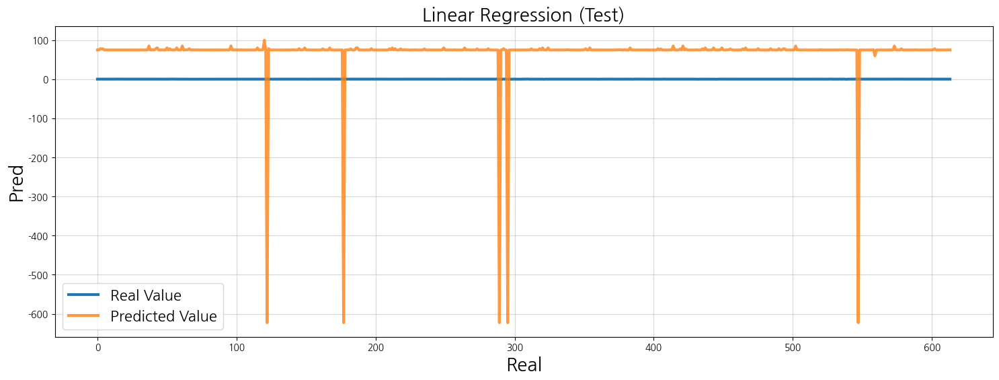

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,211.0631,"44,547.6220",132.6631,132.6631,74.5693,74.5693,"-12,322,942.3036"
1,Linear Regression,Validation(CV),15.9223,253.5193,14.1487,14.1487,13.1886,13.1886,"-68,649.0851"
2,Linear Regression,Test set,93.5633,"8,754.0904",79.5508,79.5508,74.5993,74.5993,"-3,046,581.0703"
3,Linear Regression,Entire population,202.3686,"40,953.0475",127.3293,127.3293,74.5730,74.5730,"-11,563,782.9746"


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_model_Linear Regression_20261013_235837.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_params_Linear Regression_20261013_235837.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-13 23:58:37.859751


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

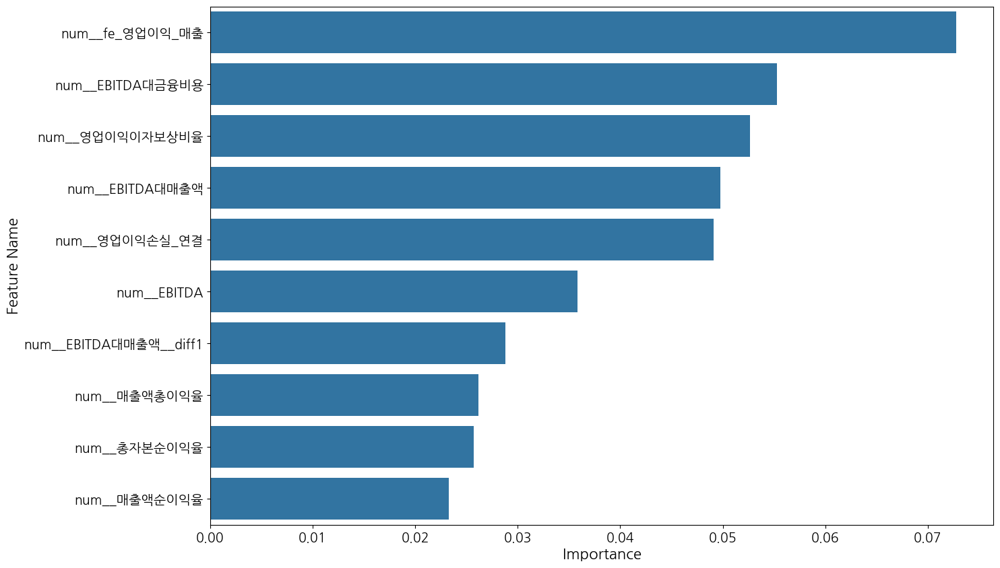

Performance Evaluations...:  2026-10-14 00:02:58.339385
Performance: 


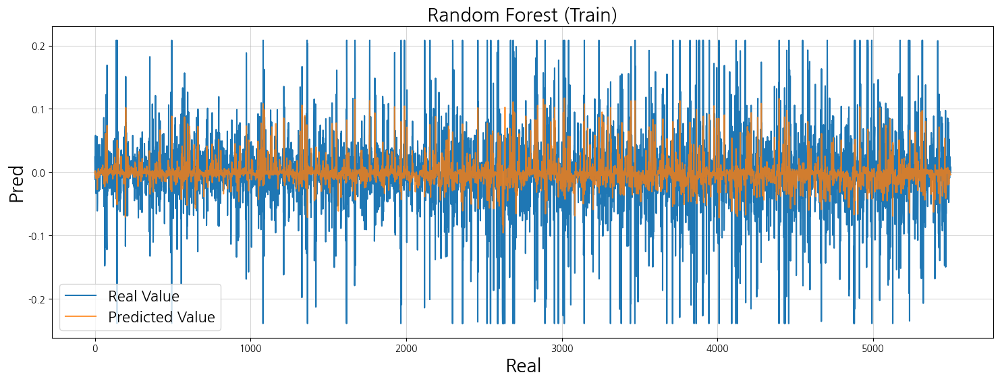

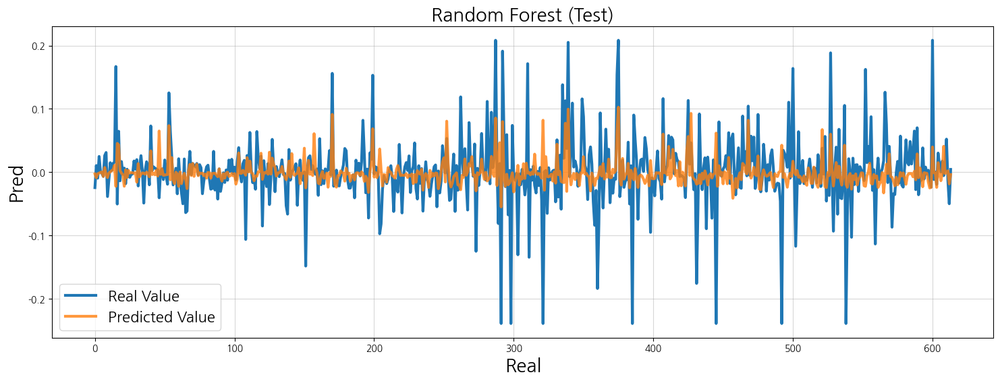

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0497,0.0025,0.0322,0.0322,0.0190,0.0190,0.3157
1,Random Forest,Validation(CV),0.0567,0.0032,0.0351,0.0351,0.0189,0.0189,0.1284
2,Random Forest,Test set,0.0504,0.0025,0.0308,0.0308,0.0172,0.0172,0.1176
3,Random Forest,Entire population,0.0498,0.0025,0.0320,0.0320,0.0189,0.0189,0.2997


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_model_Random Forest_20261014_000259.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_params_Random Forest_20261014_000259.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-14 00:02:59.374443


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

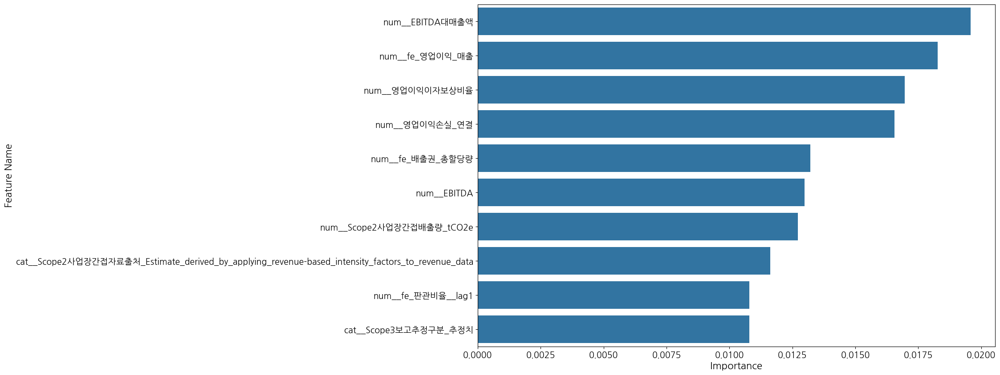

Performance Evaluations...:  2026-10-14 00:04:43.611246
Performance: 


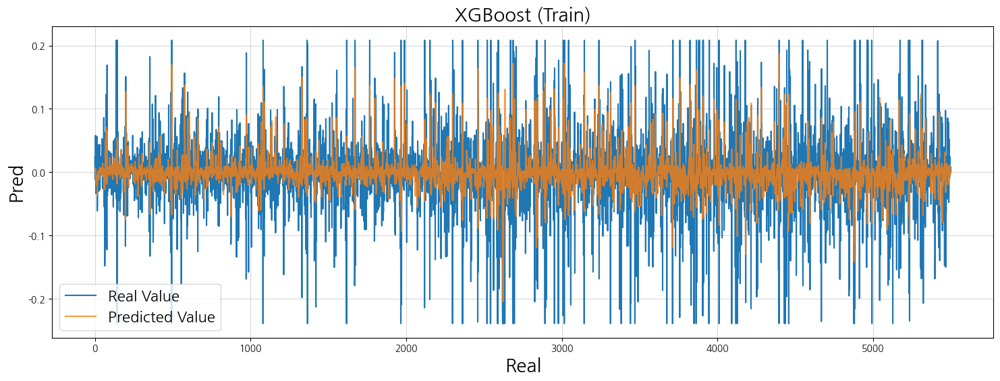

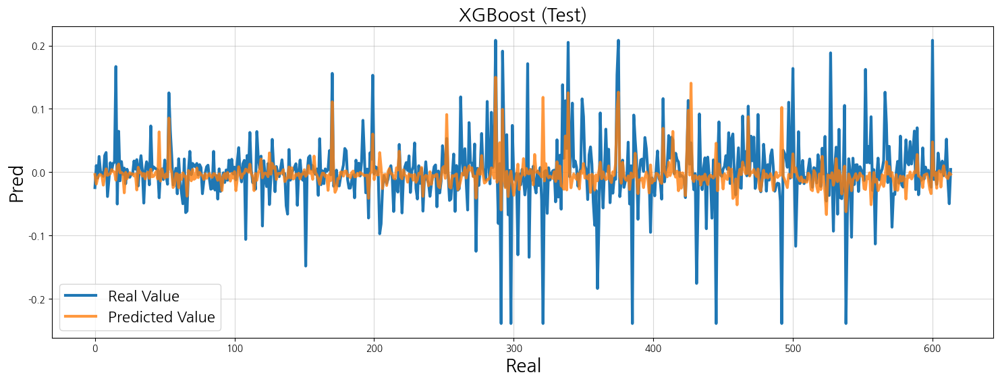

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0466,0.0022,0.0307,0.0307,0.0190,0.0190,0.3980
1,XGBoost,Validation(CV),0.0561,0.0032,0.0351,0.0351,0.0197,0.0197,0.1470
2,XGBoost,Test set,0.0513,0.0026,0.0313,0.0313,0.0191,0.0191,0.0837
3,XGBoost,Entire population,0.0471,0.0022,0.0308,0.0308,0.0190,0.0190,0.3726


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_model_XGBoost_20261014_000444.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_params_XGBoost_20261014_000444.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-14 00:04:44.358833


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

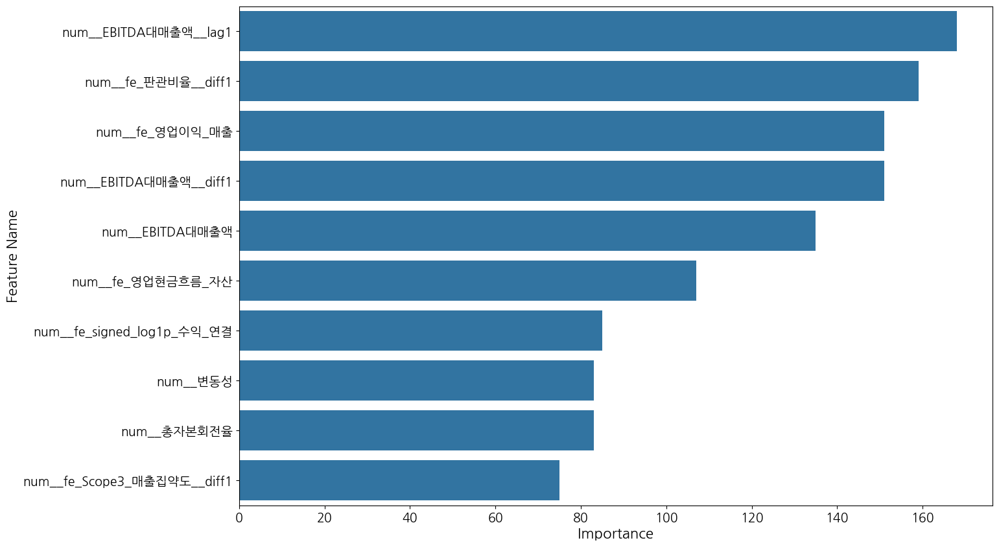

Performance Evaluations...:  2026-10-14 00:06:38.543514
Performance: 


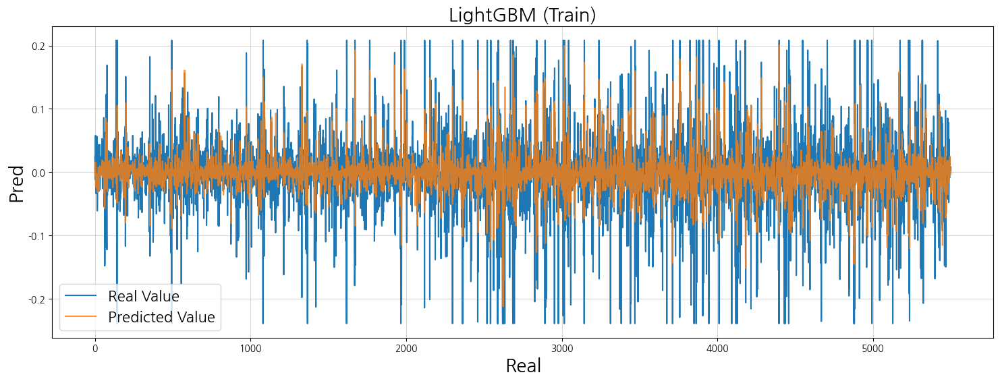

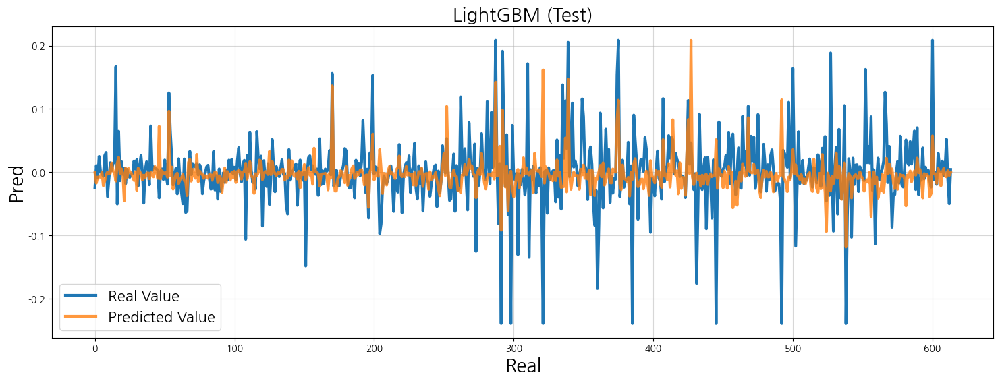

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0429,0.0018,0.0286,0.0286,0.0180,0.0180,0.4910
1,LightGBM,Validation(CV),0.0565,0.0032,0.0356,0.0356,0.0193,0.0193,0.1354
2,LightGBM,Test set,0.0526,0.0028,0.0321,0.0321,0.0183,0.0183,0.0381
3,LightGBM,Entire population,0.0440,0.0019,0.0290,0.0290,0.0180,0.0180,0.4543


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_model_LightGBM_20261014_000639.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_params_LightGBM_20261014_000639.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-14 00:06:39.834317


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

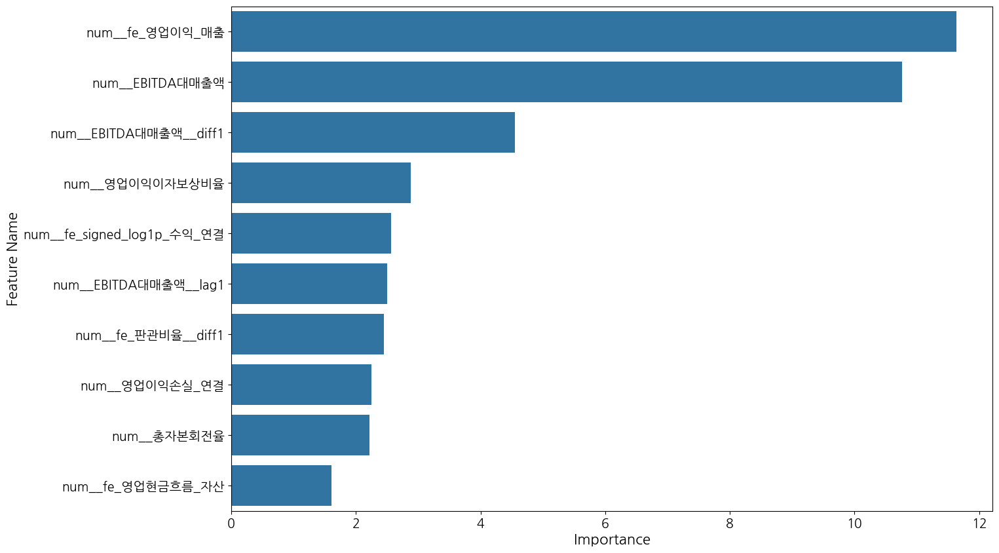

Performance Evaluations...:  2026-10-14 00:10:14.188374
Performance: 


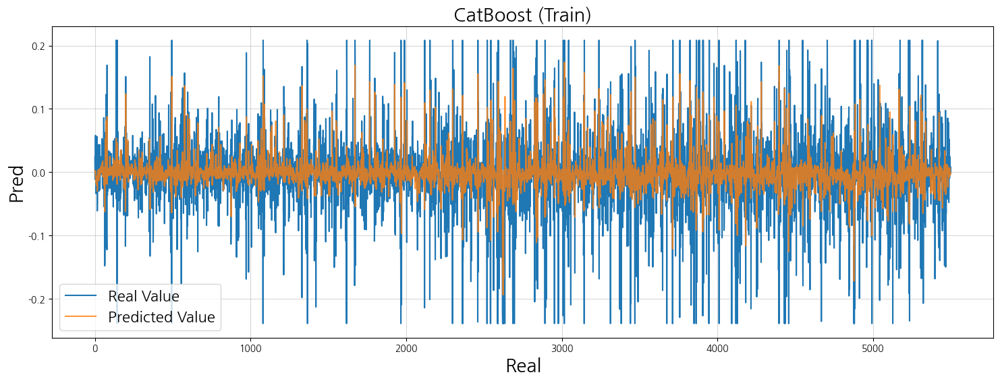

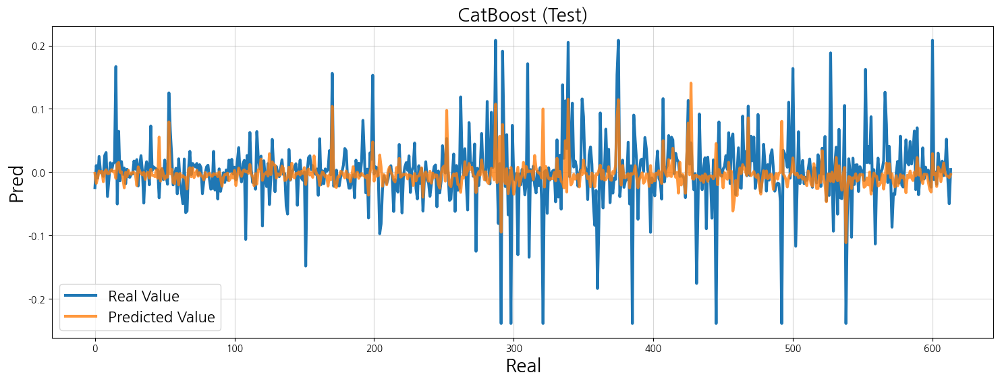

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0458,0.0021,0.0306,0.0306,0.0191,0.0191,0.4204
1,CatBoost,Validation(CV),0.0563,0.0032,0.0354,0.0354,0.0197,0.0197,0.1405
2,CatBoost,Test set,0.0511,0.0026,0.0314,0.0314,0.0183,0.0183,0.0911
3,CatBoost,Entire population,0.0463,0.0021,0.0307,0.0307,0.0190,0.0190,0.3937


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_model_CatBoost_20261014_001015.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/best_params_CatBoost_20261014_001015.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,211.0631,44547.6220,132.6631,132.6631,74.5693,74.5693,-12322942.3036
4,Random Forest,Train set,0.0497,0.0025,0.0322,0.0322,0.0190,0.0190,0.3157
8,XGBoost,Train set,0.0466,0.0022,0.0307,0.0307,0.0190,0.0190,0.3980
12,LightGBM,Train set,0.0429,0.0018,0.0286,0.0286,0.0180,0.0180,0.4910
16,CatBoost,Train set,0.0458,0.0021,0.0306,0.0306,0.0191,0.0191,0.4204


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),15.9223,253.5193,14.1487,14.1487,13.1886,13.1886,-68649.0851
5,Random Forest,Validation(CV),0.0567,0.0032,0.0351,0.0351,0.0189,0.0189,0.1284
9,XGBoost,Validation(CV),0.0561,0.0032,0.0351,0.0351,0.0197,0.0197,0.1470
13,LightGBM,Validation(CV),0.0565,0.0032,0.0356,0.0356,0.0193,0.0193,0.1354
17,CatBoost,Validation(CV),0.0563,0.0032,0.0354,0.0354,0.0197,0.0197,0.1405


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,93.5633,8754.0904,79.5508,79.5508,74.5993,74.5993,-3046581.0703
6,Random Forest,Test set,0.0504,0.0025,0.0308,0.0308,0.0172,0.0172,0.1176
10,XGBoost,Test set,0.0513,0.0026,0.0313,0.0313,0.0191,0.0191,0.0837
14,LightGBM,Test set,0.0526,0.0028,0.0321,0.0321,0.0183,0.0183,0.0381
18,CatBoost,Test set,0.0511,0.0026,0.0314,0.0314,0.0183,0.0183,0.0911


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,202.3686,40953.0475,127.3293,127.3293,74.5730,74.5730,-11563782.9746
7,Random Forest,Entire population,0.0498,0.0025,0.0320,0.0320,0.0189,0.0189,0.2997
11,XGBoost,Entire population,0.0471,0.0022,0.0308,0.0308,0.0190,0.0190,0.3726
15,LightGBM,Entire population,0.0440,0.0019,0.0290,0.0290,0.0180,0.0180,0.4543
19,CatBoost,Entire population,0.0463,0.0021,0.0307,0.0307,0.0190,0.0190,0.3937


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A+B (Financial + Carbon) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261013_235837.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B__Financial___Carbon_
Loading Model: Random Forest
   - File: best_model_Random Forest_20261014_000259.pkl
   - Successfully Loaded.
▶ Searching Directory: 

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,5051.9011 ± 11203.0698,+5051.8436,5.204,***,0.0000,93.5633
1,Random Forest (Best),0.0576 ± 0.0109,-,-,-,Benchmark,0.0504
2,XGBoost,0.0579 ± 0.0114,+0.0003,1.127,ns,0.2596,0.0513
3,LightGBM,0.0592 ± 0.0119,+0.0016,2.904,***,0.0037,0.0526
4,CatBoost,0.0576 ± 0.0114,+0.0000,0.360,ns,0.7188,0.0511



################################################################################
 ▶ Processing Feature Block: [ Model A+C (Financial + ESG) ]
################################################################################
▷ Valid Features: 187 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-14 00:10:37.566832


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 11] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 12] Params: {'fit_intercept': False, 'scaler_type': 'R

,Features,Coef,Features,Coef
0,missing__missingindicator_fe_유무형리스증가_자산,43.6797,missing__missingindicator_현금및현금성자산_연결,-32.9492
1,missing__missingindicator_기말종가수정,30.3828,missing__missingindicator_자산총계_연결,-32.0625
2,missing__missingindicator_법인세비용차감전계속영업이익손실_연결,27.6641,missing__missingindicator_매출총이익손실_연결,-31.8359
3,missing__missingindicator_수익_연결,26.2969,missing__missingindicator_기말종가,-23.6094
4,cat__기부금_출처_missing,18.5078,missing__missingindicator_유무형리스자산의증가_연결,-21.1133
...,...,...,...,...
97,num__EBITDA대금융비용,0.0001,NaN,NaN
98,num__영업이익이자보상비율,0.0000,NaN,NaN
99,num__무형자산상각비_연결,0.0000,NaN,NaN
100,num__현금및현금성자산_연결,0.0000,NaN,NaN


Performance Evaluations...:  2026-10-14 00:11:52.865498
Performance: 


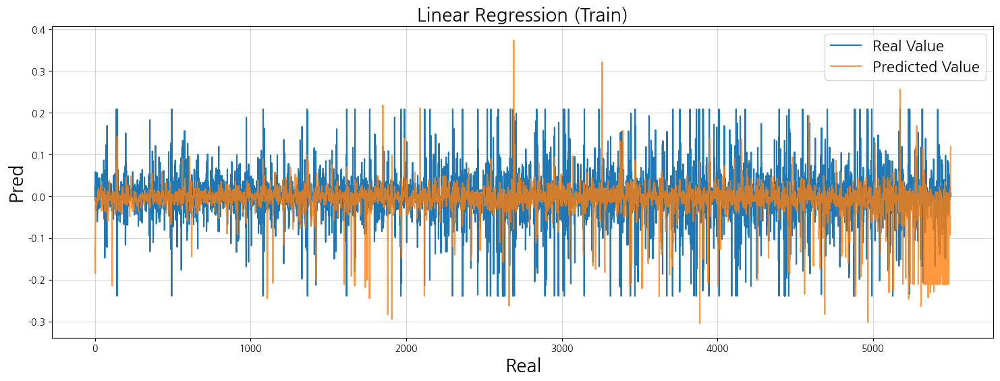

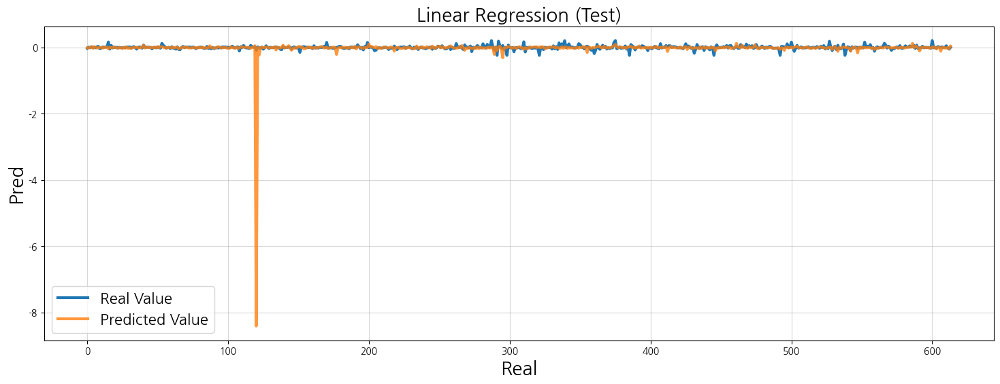

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,0.0679,0.0046,0.0440,0.0440,0.0265,0.0265,-0.2772
1,Linear Regression,Validation(CV),0.0787,0.0062,0.0526,0.0526,0.0390,0.0390,-0.6786
2,Linear Regression,Test set,0.3413,0.1165,0.0515,0.0515,0.0232,0.0232,-39.5492
3,Linear Regression,Entire population,0.1259,0.0159,0.0447,0.0447,0.0261,0.0261,-3.4768


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_model_Linear Regression_20261014_001153.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_params_Linear Regression_20261014_001153.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-14 00:11:53.399469


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

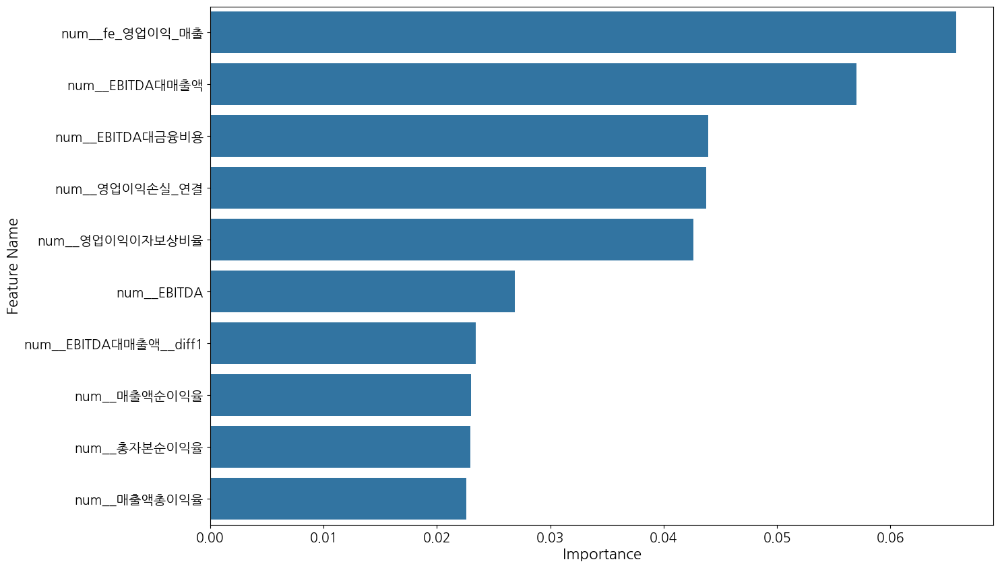

Performance Evaluations...:  2026-10-14 00:18:03.988748
Performance: 


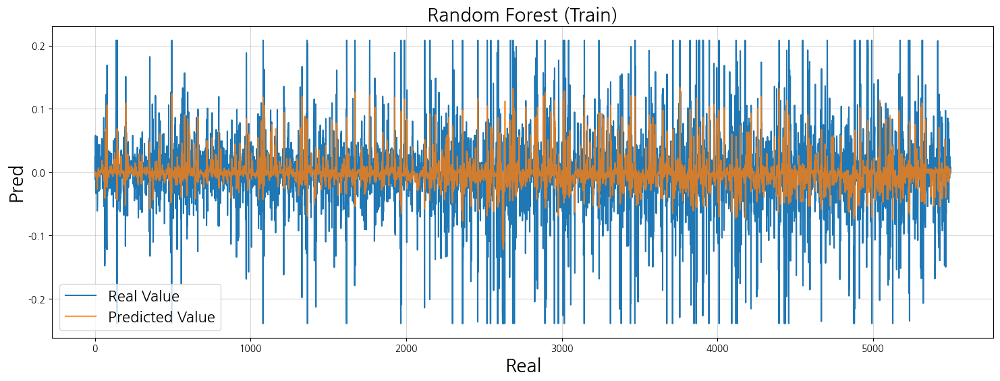

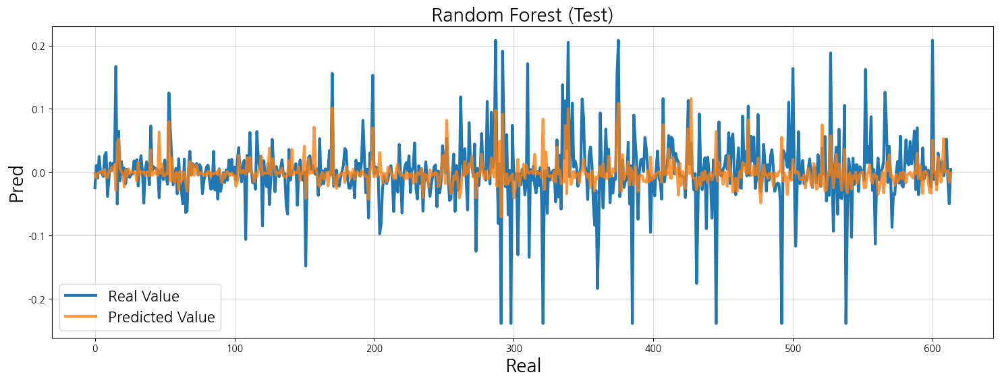

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0464,0.0022,0.0302,0.0302,0.0182,0.0182,0.4043
1,Random Forest,Validation(CV),0.0567,0.0032,0.0352,0.0352,0.0193,0.0193,0.1282
2,Random Forest,Test set,0.0502,0.0025,0.0308,0.0308,0.0174,0.0174,0.1222
3,Random Forest,Entire population,0.0468,0.0022,0.0303,0.0303,0.0181,0.0181,0.3814


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_model_Random Forest_20261014_001807.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_params_Random Forest_20261014_001807.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-14 00:18:07.324349


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

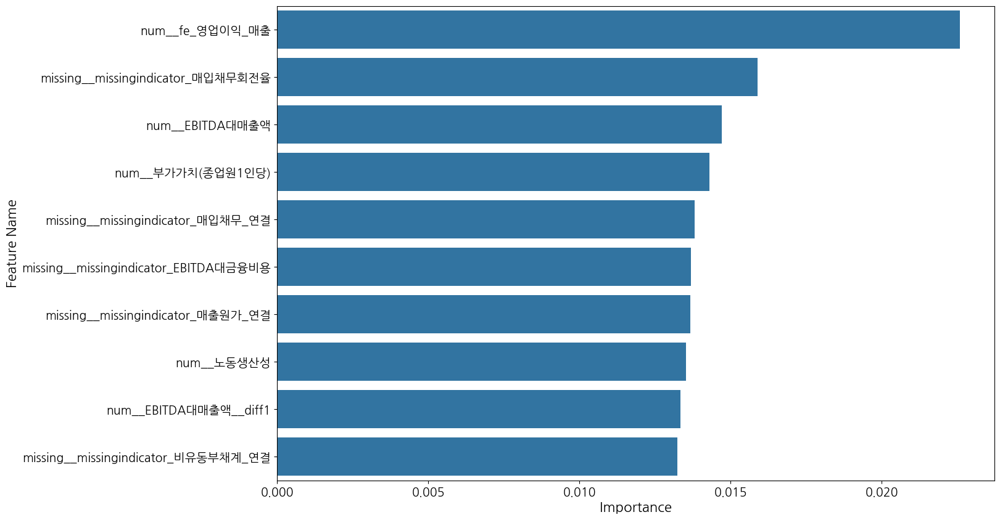

Performance Evaluations...:  2026-10-14 00:20:17.688473
Performance: 


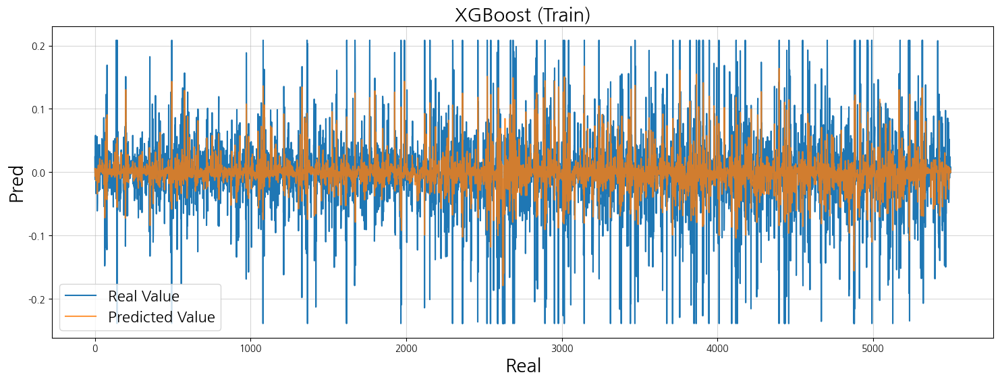

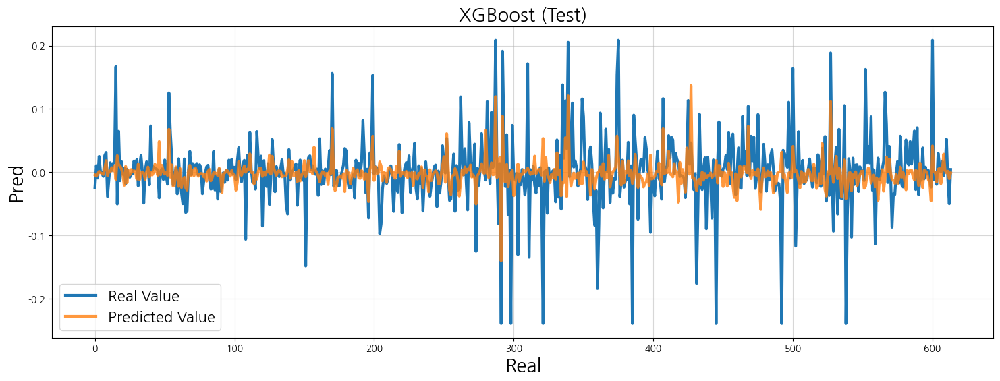

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0397,0.0016,0.0262,0.0262,0.0163,0.0163,0.5638
1,XGBoost,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0193,0.0193,0.1742
2,XGBoost,Test set,0.0494,0.0024,0.0309,0.0309,0.0173,0.0173,0.1508
3,XGBoost,Entire population,0.0408,0.0017,0.0267,0.0267,0.0164,0.0164,0.5303


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_model_XGBoost_20261014_002018.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_params_XGBoost_20261014_002018.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-14 00:20:18.628217


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

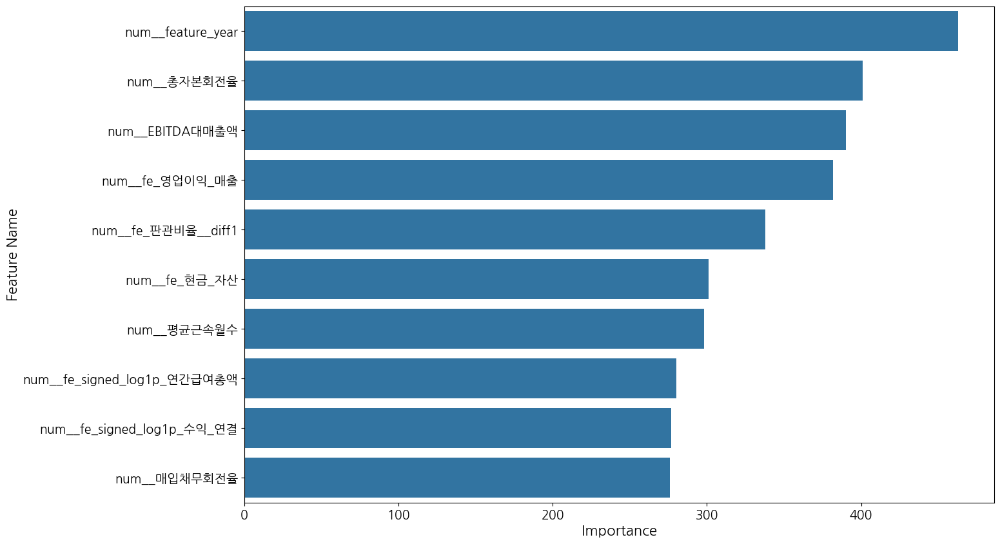

Performance Evaluations...:  2026-10-14 00:22:48.803204
Performance: 


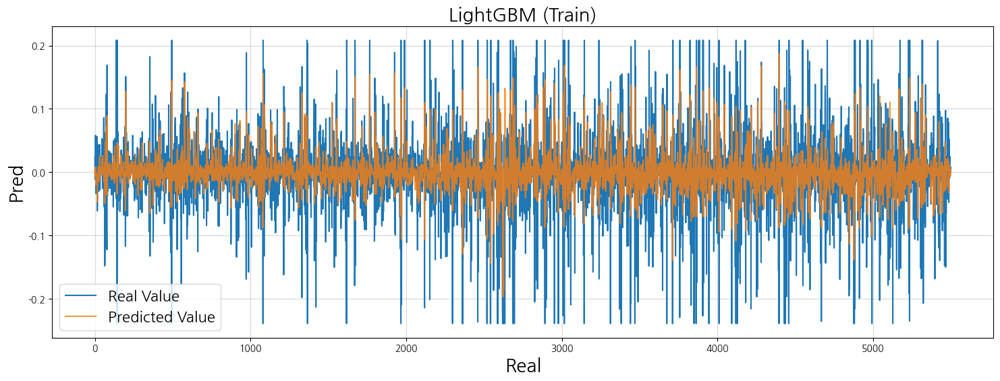

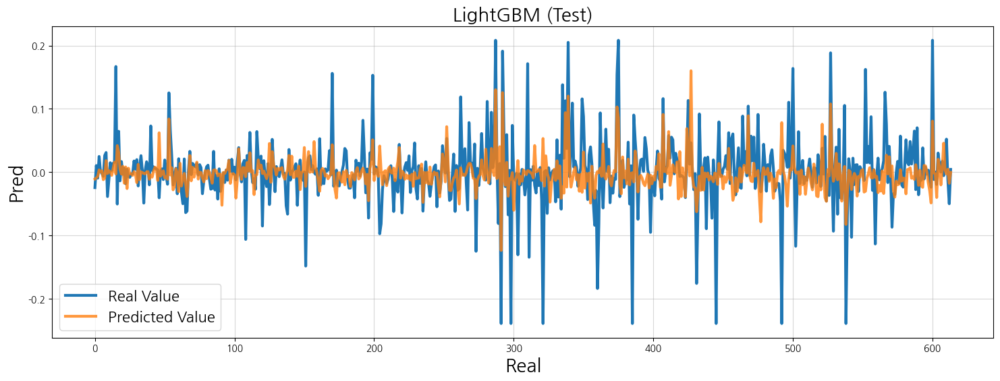

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0420,0.0018,0.0277,0.0277,0.0170,0.0170,0.5120
1,LightGBM,Validation(CV),0.0560,0.0031,0.0354,0.0354,0.0194,0.0194,0.1500
2,LightGBM,Test set,0.0494,0.0024,0.0311,0.0311,0.0186,0.0186,0.1505
3,LightGBM,Entire population,0.0428,0.0018,0.0280,0.0280,0.0172,0.0172,0.4827


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_model_LightGBM_20261014_002250.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_params_LightGBM_20261014_002250.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-14 00:22:50.881834


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

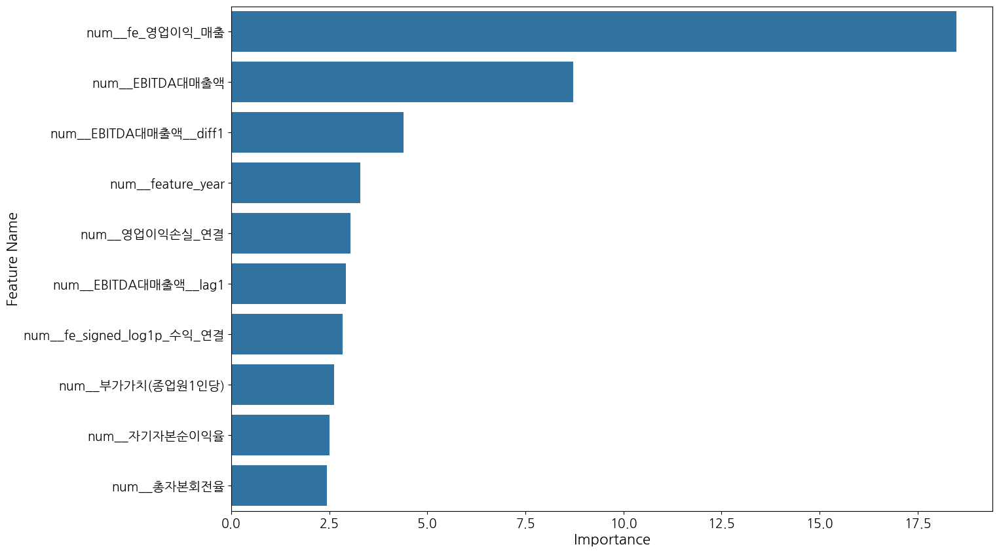

Performance Evaluations...:  2026-10-14 00:25:16.600998
Performance: 


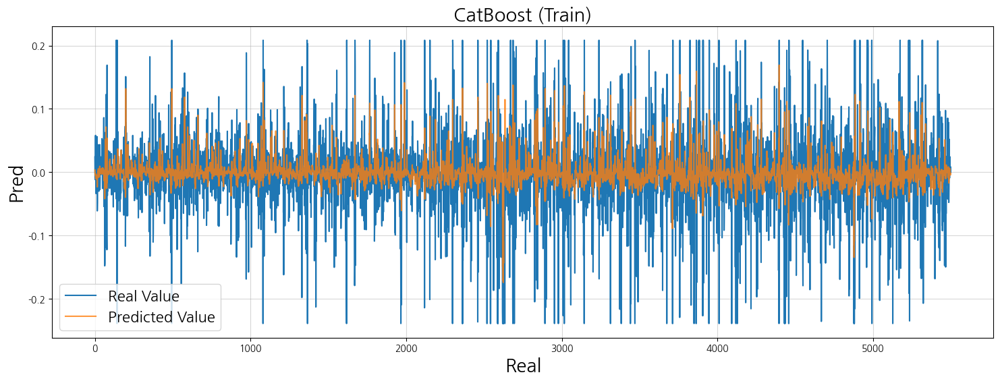

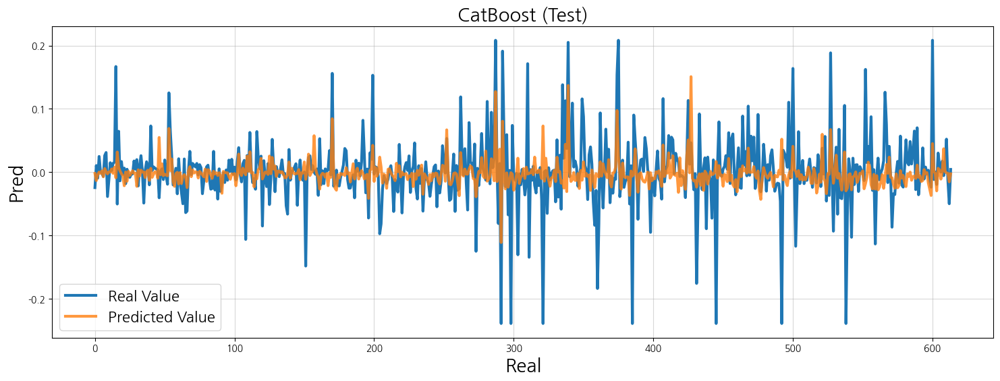

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0501,0.0025,0.0329,0.0329,0.0198,0.0198,0.3049
1,CatBoost,Validation(CV),0.0560,0.0031,0.0353,0.0353,0.0194,0.0194,0.1502
2,CatBoost,Test set,0.0495,0.0025,0.0308,0.0308,0.0176,0.0176,0.1459
3,CatBoost,Entire population,0.0501,0.0025,0.0327,0.0327,0.0195,0.0195,0.2921


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_model_CatBoost_20261014_002517.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/best_params_CatBoost_20261014_002517.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,0.0679,0.0046,0.0440,0.0440,0.0265,0.0265,-0.2772
4,Random Forest,Train set,0.0464,0.0022,0.0302,0.0302,0.0182,0.0182,0.4043
8,XGBoost,Train set,0.0397,0.0016,0.0262,0.0262,0.0163,0.0163,0.5638
12,LightGBM,Train set,0.0420,0.0018,0.0277,0.0277,0.0170,0.0170,0.5120
16,CatBoost,Train set,0.0501,0.0025,0.0329,0.0329,0.0198,0.0198,0.3049


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),0.0787,0.0062,0.0526,0.0526,0.0390,0.0390,-0.6786
5,Random Forest,Validation(CV),0.0567,0.0032,0.0352,0.0352,0.0193,0.0193,0.1282
9,XGBoost,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0193,0.0193,0.1742
13,LightGBM,Validation(CV),0.0560,0.0031,0.0354,0.0354,0.0194,0.0194,0.1500
17,CatBoost,Validation(CV),0.0560,0.0031,0.0353,0.0353,0.0194,0.0194,0.1502


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,0.3413,0.1165,0.0515,0.0515,0.0232,0.0232,-39.5492
6,Random Forest,Test set,0.0502,0.0025,0.0308,0.0308,0.0174,0.0174,0.1222
10,XGBoost,Test set,0.0494,0.0024,0.0309,0.0309,0.0173,0.0173,0.1508
14,LightGBM,Test set,0.0494,0.0024,0.0311,0.0311,0.0186,0.0186,0.1505
18,CatBoost,Test set,0.0495,0.0025,0.0308,0.0308,0.0176,0.0176,0.1459


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,0.1259,0.0159,0.0447,0.0447,0.0261,0.0261,-3.4768
7,Random Forest,Entire population,0.0468,0.0022,0.0303,0.0303,0.0181,0.0181,0.3814
11,XGBoost,Entire population,0.0408,0.0017,0.0267,0.0267,0.0164,0.0164,0.5303
15,LightGBM,Entire population,0.0428,0.0018,0.0280,0.0280,0.0172,0.0172,0.4827
19,CatBoost,Entire population,0.0501,0.0025,0.0327,0.0327,0.0195,0.0195,0.2921


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A+C (Financial + ESG) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261014_001153.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_C__Financial___ESG_
Loading Model: Random Forest
   - File: best_model_Random Forest_20261014_001807.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/D

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,1.3048 ± 1.7839,+1.2473,3.431,***,0.0006,0.3413
1,Random Forest,0.0576 ± 0.0112,+0.0001,0.824,ns,0.4097,0.0502
2,XGBoost,0.0580 ± 0.0115,+0.0005,2.345,**,0.0191,0.0494
3,LightGBM,0.0583 ± 0.0116,+0.0008,2.434,**,0.0150,0.0494
4,CatBoost (Best),0.0575 ± 0.0109,-,-,-,Benchmark,0.0495



################################################################################
 ▶ Processing Feature Block: [ Model A+D (Financial + Macro) ]
################################################################################
▷ Valid Features: 661 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-14 00:25:59.315800


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': True, 'scaler_type': 'Normalizer'}
  ▶ [Trial 11] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 12] Params: {'fit_intercept': True, 'scaler_type': 'Stan

,Features,Coef,Features,Coef
0,cat__KSIC세분류_11차_C20200.합성고무_및_플라스틱_물질_제조업,3.0312,cat__KSIC중분류_11차_H49000.육상_운송_및_파이프라인_운송업,-2.8281
1,cat__KSIC소분류_11차_C12000.담배_제조업,2.9219,cat__KSIC소분류_11차_C20200.합성고무_및_플라스틱_물질_제조업,-2.7500
2,missing__missingindicator_fe_signed_log1p_자산총계_연결,2.5625,missing__missingindicator_유동자산계_연결,-2.5469
3,cat__Trucost산업_Automobiles,2.4062,cat__KSIC세분류_11차_G45110.자동차_신품_판매업,-2.3750
4,cat__KSIC소분류_11차_G45100.자동차_판매업,2.3594,cat__KSIC소분류_11차_J61200.전기_통신업,-2.2812
...,...,...,...,...
343,cat__Trucost산업_Health_Care_Providers_and_Services,0.0004,NaN,NaN
344,num__매출총이익손실_연결,0.0004,NaN,NaN
345,cat__NICS산업분류_N25401.미디어,0.0002,NaN,NaN
346,cat__Trucost산업_IT_Services,0.0002,NaN,NaN


Performance Evaluations...:  2026-10-14 00:27:16.231304
Performance: 


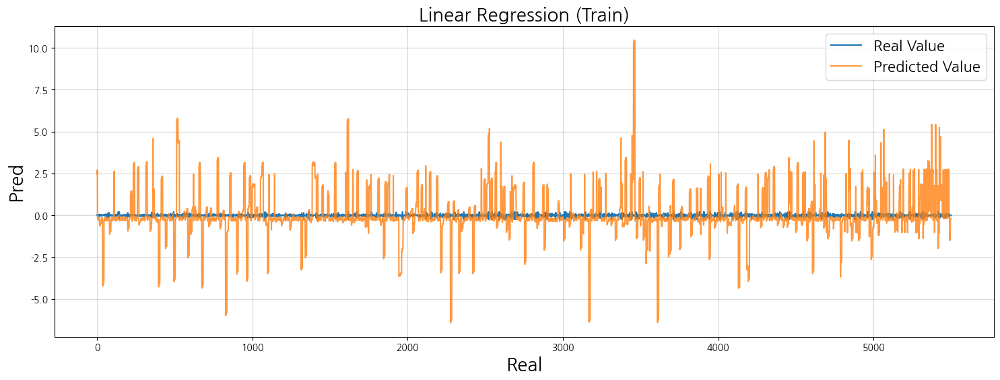

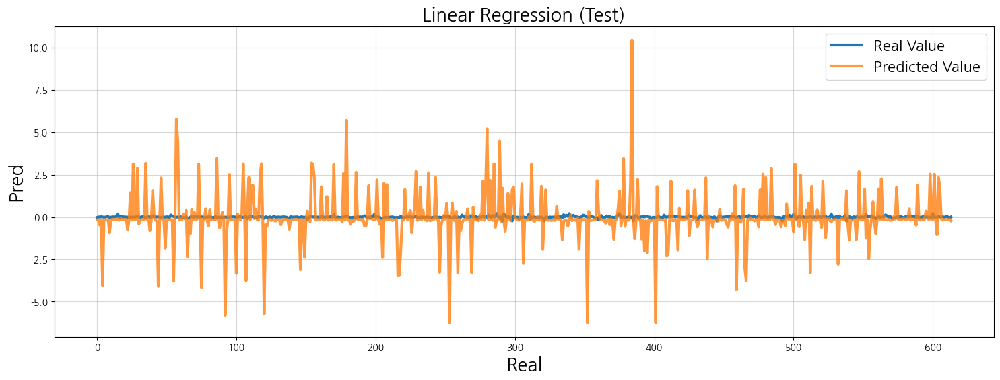

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,1.4245,2.0291,0.8006,0.8006,0.2805,0.2805,-560.3113
1,Linear Regression,Validation(CV),0.3173,0.1007,0.1767,0.1767,0.0802,0.0802,-26.2612
2,Linear Regression,Test set,1.3806,1.9061,0.7351,0.7351,0.1941,0.1941,-662.3734
3,Linear Regression,Entire population,1.4201,2.0168,0.7941,0.7941,0.2698,0.2698,-568.4764


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_model_Linear Regression_20261014_002716.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_params_Linear Regression_20261014_002716.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-14 00:27:16.770380


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

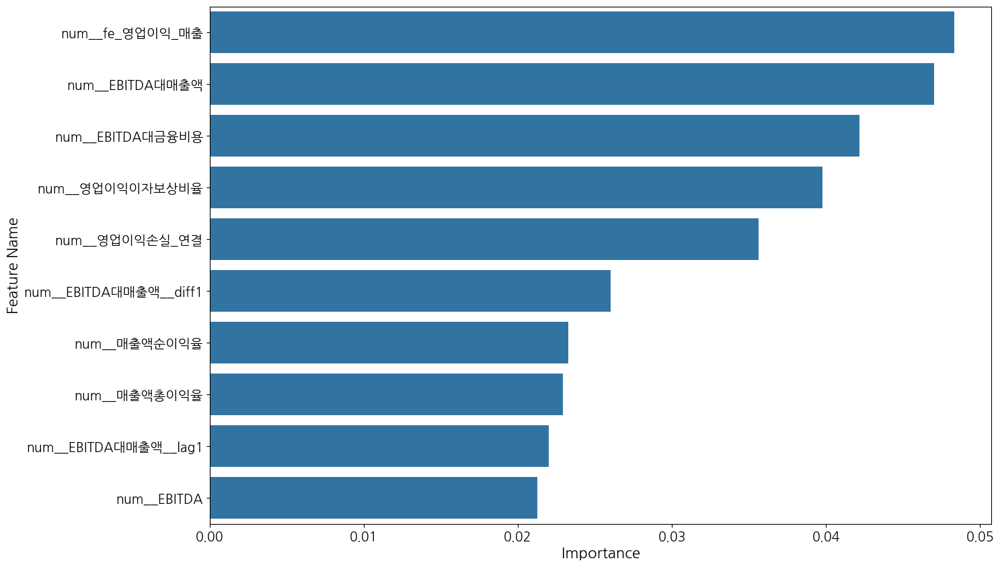

Performance Evaluations...:  2026-10-14 00:34:26.807906
Performance: 


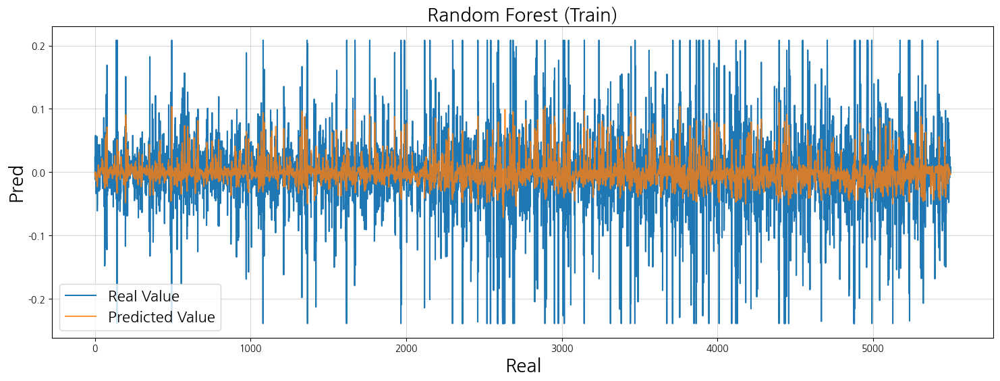

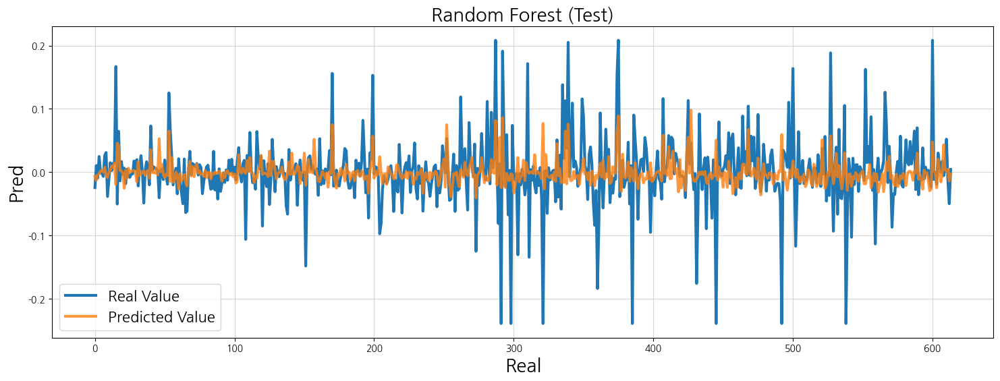

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0500,0.0025,0.0317,0.0317,0.0182,0.0182,0.3083
1,Random Forest,Validation(CV),0.0569,0.0032,0.0353,0.0353,0.0192,0.0192,0.1244
2,Random Forest,Test set,0.0508,0.0026,0.0308,0.0308,0.0169,0.0169,0.1022
3,Random Forest,Entire population,0.0501,0.0025,0.0316,0.0316,0.0181,0.0181,0.2917


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_model_Random Forest_20261014_003429.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_params_Random Forest_20261014_003429.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-14 00:34:29.068807


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

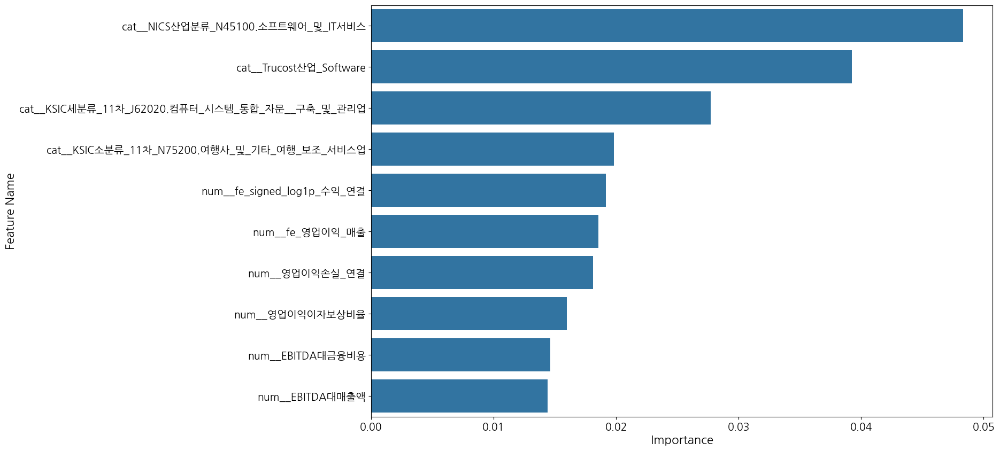

Performance Evaluations...:  2026-10-14 00:36:17.276763
Performance: 


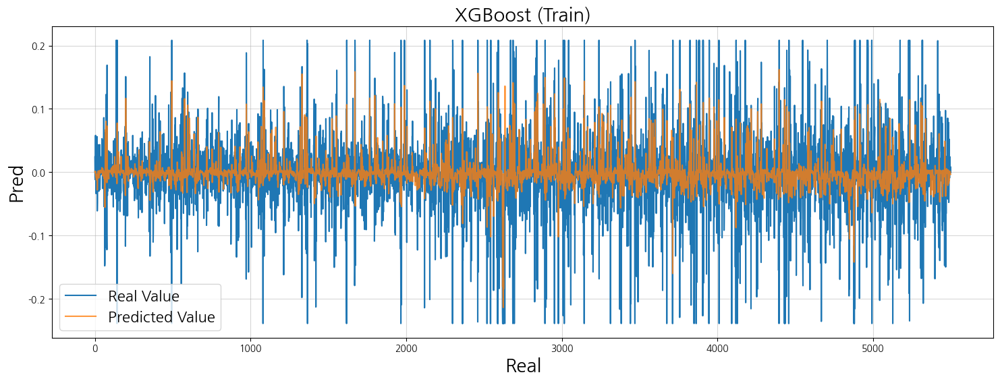

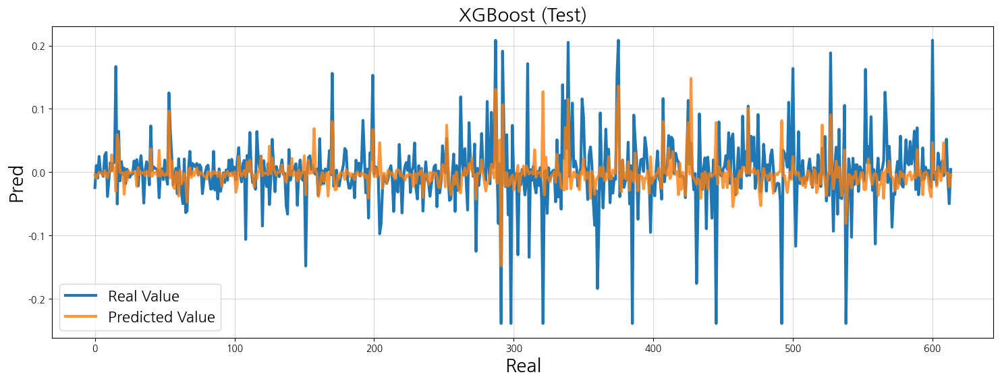

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0499,0.0025,0.0327,0.0327,0.0199,0.0199,0.3108
1,XGBoost,Validation(CV),0.0562,0.0032,0.0353,0.0353,0.0195,0.0195,0.1450
2,XGBoost,Test set,0.0505,0.0025,0.0308,0.0308,0.0187,0.0187,0.1126
3,XGBoost,Entire population,0.0500,0.0025,0.0325,0.0325,0.0197,0.0197,0.2948


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_model_XGBoost_20261014_003618.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_params_XGBoost_20261014_003618.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-14 00:36:18.114078


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

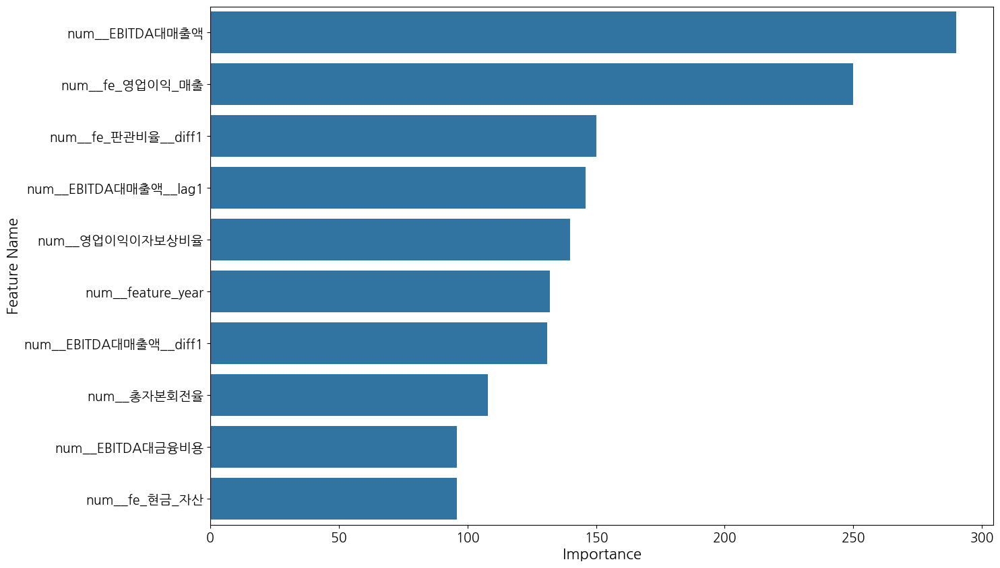

Performance Evaluations...:  2026-10-14 00:38:04.468050
Performance: 


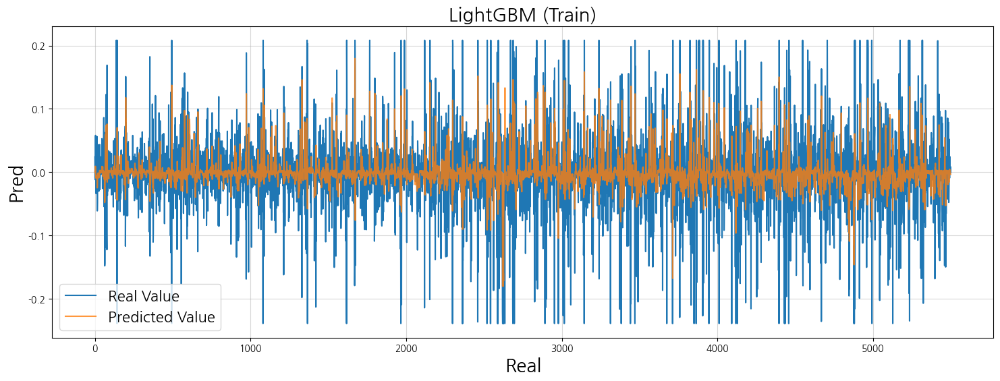

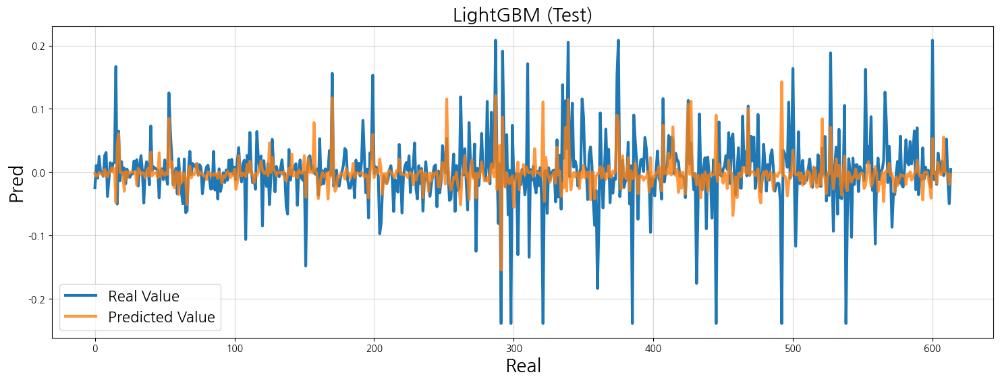

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0492,0.0024,0.0324,0.0324,0.0197,0.0197,0.3307
1,LightGBM,Validation(CV),0.0572,0.0033,0.0354,0.0354,0.0200,0.0200,0.1151
2,LightGBM,Test set,0.0521,0.0027,0.0312,0.0312,0.0176,0.0176,0.0569
3,LightGBM,Entire population,0.0495,0.0024,0.0323,0.0323,0.0196,0.0196,0.3086


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_model_LightGBM_20261014_003805.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_params_LightGBM_20261014_003805.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-14 00:38:05.479634


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

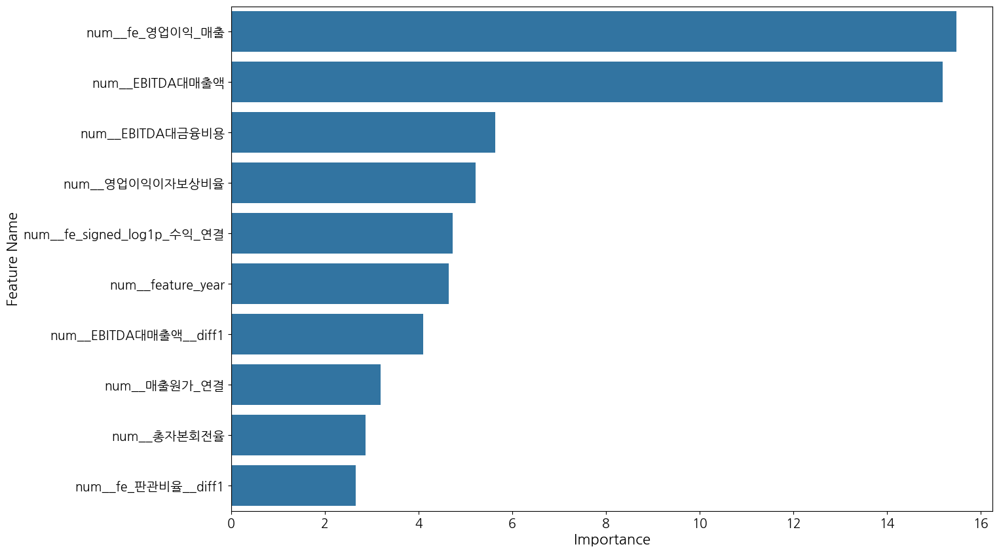

Performance Evaluations...:  2026-10-14 00:40:04.163786
Performance: 


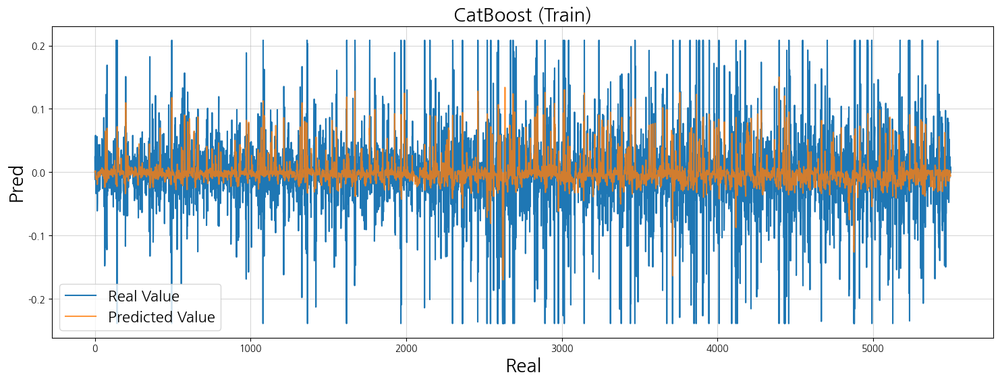

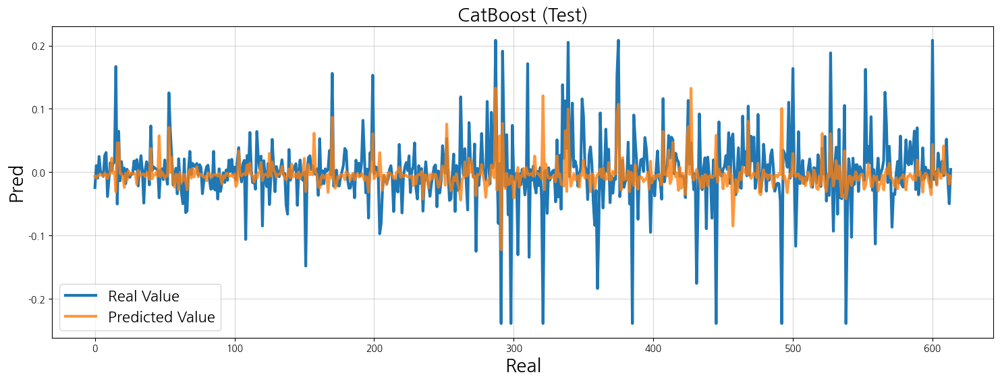

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0526,0.0028,0.0342,0.0342,0.0203,0.0203,0.2357
1,CatBoost,Validation(CV),0.0568,0.0032,0.0357,0.0357,0.0199,0.0199,0.1273
2,CatBoost,Test set,0.0515,0.0026,0.0315,0.0315,0.0181,0.0181,0.0786
3,CatBoost,Entire population,0.0525,0.0028,0.0339,0.0339,0.0201,0.0201,0.2231


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_model_CatBoost_20261014_004005.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/best_params_CatBoost_20261014_004005.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,1.4245,2.0291,0.8006,0.8006,0.2805,0.2805,-560.3113
4,Random Forest,Train set,0.0500,0.0025,0.0317,0.0317,0.0182,0.0182,0.3083
8,XGBoost,Train set,0.0499,0.0025,0.0327,0.0327,0.0199,0.0199,0.3108
12,LightGBM,Train set,0.0492,0.0024,0.0324,0.0324,0.0197,0.0197,0.3307
16,CatBoost,Train set,0.0526,0.0028,0.0342,0.0342,0.0203,0.0203,0.2357


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),0.3173,0.1007,0.1767,0.1767,0.0802,0.0802,-26.2612
5,Random Forest,Validation(CV),0.0569,0.0032,0.0353,0.0353,0.0192,0.0192,0.1244
9,XGBoost,Validation(CV),0.0562,0.0032,0.0353,0.0353,0.0195,0.0195,0.1450
13,LightGBM,Validation(CV),0.0572,0.0033,0.0354,0.0354,0.0200,0.0200,0.1151
17,CatBoost,Validation(CV),0.0568,0.0032,0.0357,0.0357,0.0199,0.0199,0.1273


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,1.3806,1.9061,0.7351,0.7351,0.1941,0.1941,-662.3734
6,Random Forest,Test set,0.0508,0.0026,0.0308,0.0308,0.0169,0.0169,0.1022
10,XGBoost,Test set,0.0505,0.0025,0.0308,0.0308,0.0187,0.0187,0.1126
14,LightGBM,Test set,0.0521,0.0027,0.0312,0.0312,0.0176,0.0176,0.0569
18,CatBoost,Test set,0.0515,0.0026,0.0315,0.0315,0.0181,0.0181,0.0786


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,1.4201,2.0168,0.7941,0.7941,0.2698,0.2698,-568.4764
7,Random Forest,Entire population,0.0501,0.0025,0.0316,0.0316,0.0181,0.0181,0.2917
11,XGBoost,Entire population,0.0500,0.0025,0.0325,0.0325,0.0197,0.0197,0.2948
15,LightGBM,Entire population,0.0495,0.0024,0.0323,0.0323,0.0196,0.0196,0.3086
19,CatBoost,Entire population,0.0525,0.0028,0.0339,0.0339,0.0201,0.0201,0.2231


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A+D (Financial + Macro) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261014_002716.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_D__Financial___Macro_
Loading Model: Random Forest
   - File: best_model_Random Forest_20261014_003429.pkl
   - Successfully Loaded.
▶ Searching Directory: /wor

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,1778219.2838 ± 5333679.6976,+1778219.2261,5.081,***,0.0000,1.3806
1,Random Forest,0.0578 ± 0.0109,+0.0001,-0.266,ns,0.7906,0.0508
2,XGBoost,0.0578 ± 0.0115,+0.0001,0.153,ns,0.8787,0.0505
3,LightGBM,0.0582 ± 0.0116,+0.0006,2.610,***,0.0091,0.0521
4,CatBoost (Best),0.0577 ± 0.0117,-,-,-,Benchmark,0.0515



################################################################################
 ▶ Processing Feature Block: [ Model A+B+C (Financial + Carbon + ESG) ]
################################################################################
▷ Valid Features: 318 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-14 00:40:28.767545


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 11] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 12] Params: {'fit_intercept': False, 'scaler_type': 'Norma

,Features,Coef,Features,Coef
0,cat__Scope3보고추정구분_보고값,"4,128.0000",missing__missingindicator_fe_signed_log1p_자산총계_연결,"-7,008.0000"
1,missing__missingindicator_fe_signed_log1p_Scope1직접배출량_tCO2e,"2,800.0000",missing__missingindicator_기말종가수정,"-4,256.0000"
2,missing__missingindicator_평균시가총액_보통주우선주,"2,712.0000",cat__Scope3자료출처_Exact_Value_from_CDP,"-4,016.0000"
3,cat__Scope1자료출처_Value_split_from_data_provided_in_Annual_Report/10K/Financial_Accounts_Disclosure,"2,224.0000",cat__Scope2사업장간접자료출처_Value_split_from_data_provided_in_Annual_Report/10K/Financial_Accounts_Disc...,"-2,304.0000"
4,missing__missingindicator_기말시가총액,"2,024.0000",missing__missingindicator_매출채권회전율,"-2,272.0000"
...,...,...,...,...
161,NaN,NaN,num__fe_감가상각부담,-0.0042
162,NaN,NaN,num__종업원1인당인건비증가율,-0.0028
163,NaN,NaN,num__fe_배출권_할당충족률,-0.0025
164,NaN,NaN,num__재고자산회전율2,-0.0017


Performance Evaluations...:  2026-10-14 00:41:44.220868
Performance: 


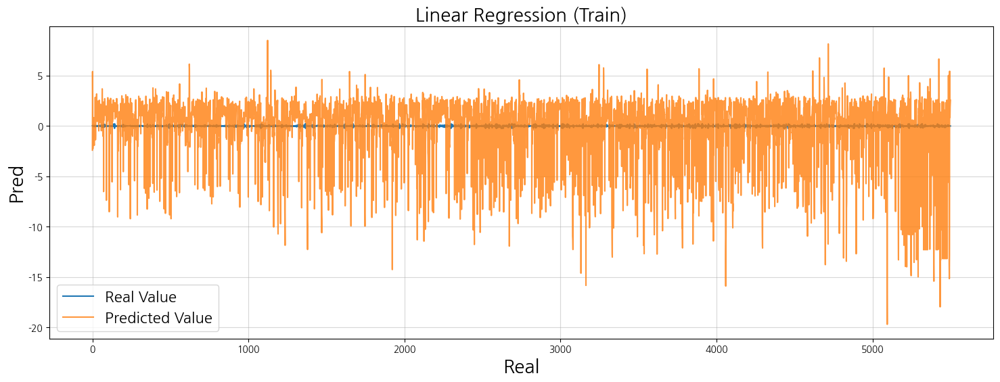

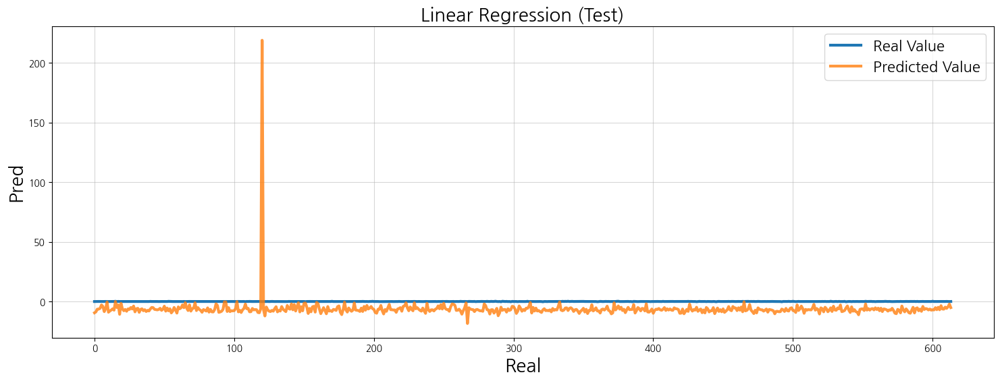

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,3.0303,9.1825,2.0138,2.0138,1.3800,1.3800,"-2,539.1044"
1,Linear Regression,Validation(CV),7.9466,63.1487,2.0961,2.0961,1.1144,1.1144,"-17,098.9453"
2,Linear Regression,Test set,11.2424,126.3909,6.9496,6.9496,6.8493,6.8493,"-43,985.3214"
3,Linear Regression,Entire population,4.5775,20.9532,2.5095,2.5095,1.5478,1.5478,"-5,915.4885"


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_model_Linear Regression_20261014_004144.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_params_Linear Regression_20261014_004144.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-14 00:41:44.744141


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

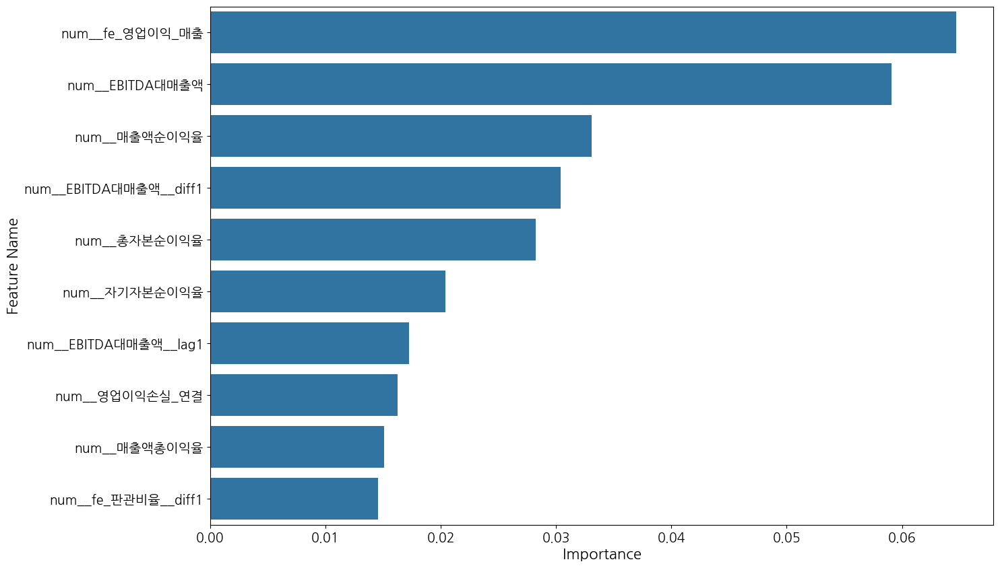

Performance Evaluations...:  2026-10-14 00:46:39.996724
Performance: 


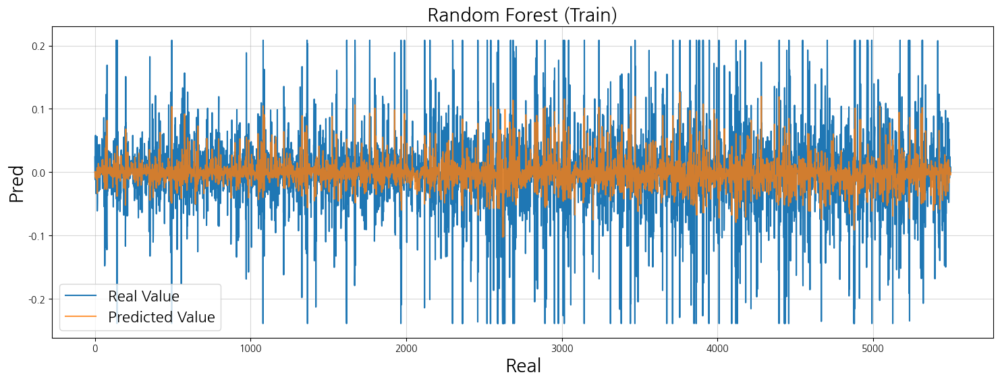

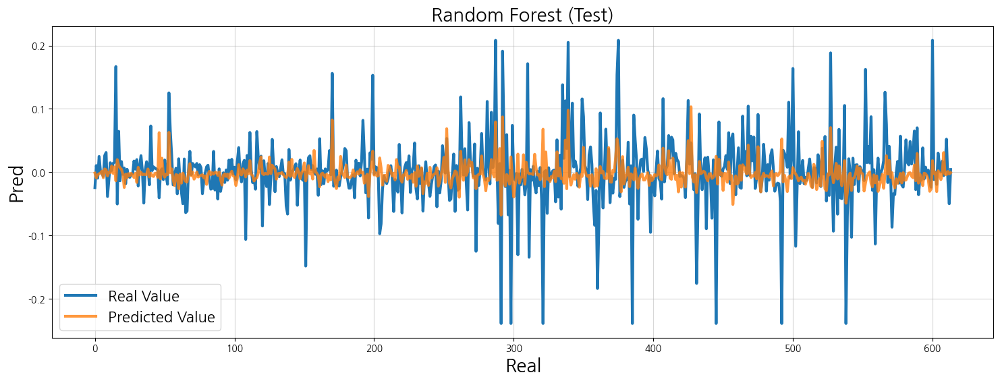

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0458,0.0021,0.0293,0.0293,0.0171,0.0171,0.4198
1,Random Forest,Validation(CV),0.0566,0.0032,0.0356,0.0356,0.0195,0.0195,0.1324
2,Random Forest,Test set,0.0504,0.0025,0.0313,0.0313,0.0179,0.0179,0.1167
3,Random Forest,Entire population,0.0463,0.0021,0.0295,0.0295,0.0172,0.0172,0.3953


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_model_Random Forest_20261014_004641.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_params_Random Forest_20261014_004641.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-14 00:46:41.229685


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

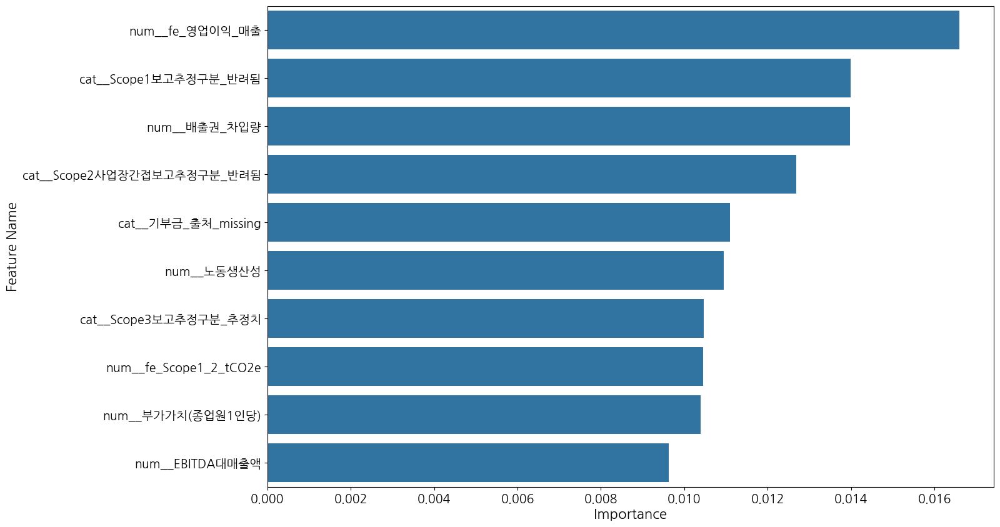

Performance Evaluations...:  2026-10-14 00:48:48.279154
Performance: 


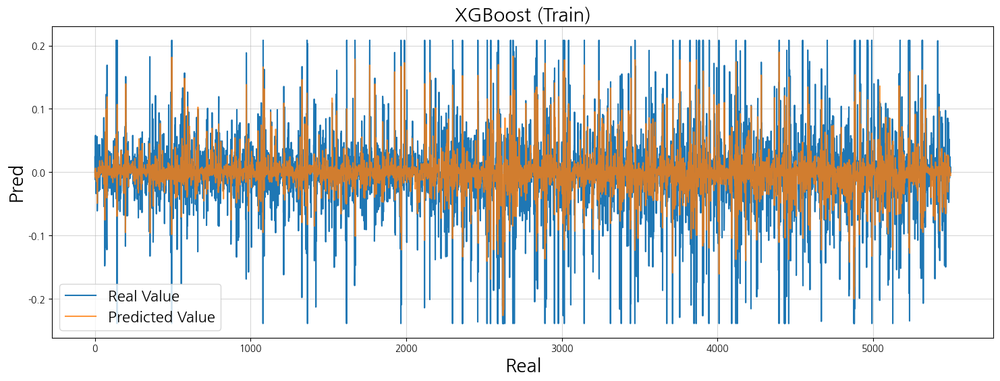

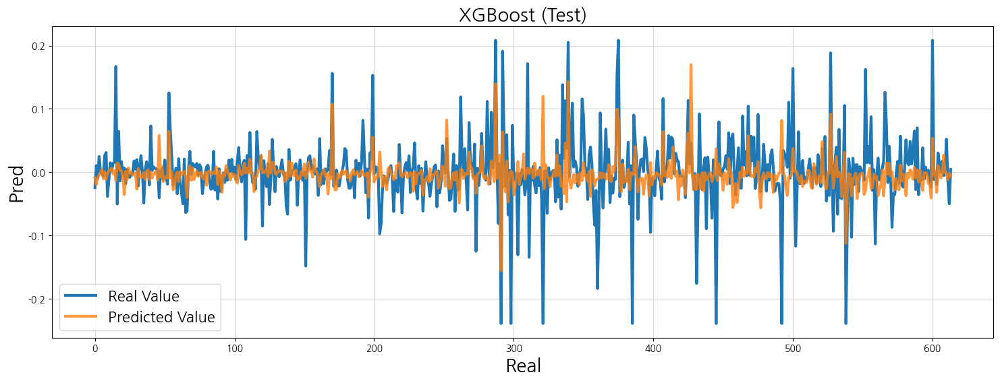

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0356,0.0013,0.0241,0.0241,0.0159,0.0159,0.6491
1,XGBoost,Validation(CV),0.0546,0.0030,0.0344,0.0344,0.0184,0.0184,0.1934
2,XGBoost,Test set,0.0502,0.0025,0.0312,0.0312,0.0181,0.0181,0.1231
3,XGBoost,Entire population,0.0373,0.0014,0.0248,0.0248,0.0161,0.0161,0.6063


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_model_XGBoost_20261014_004849.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_params_XGBoost_20261014_004849.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-14 00:48:49.173242


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

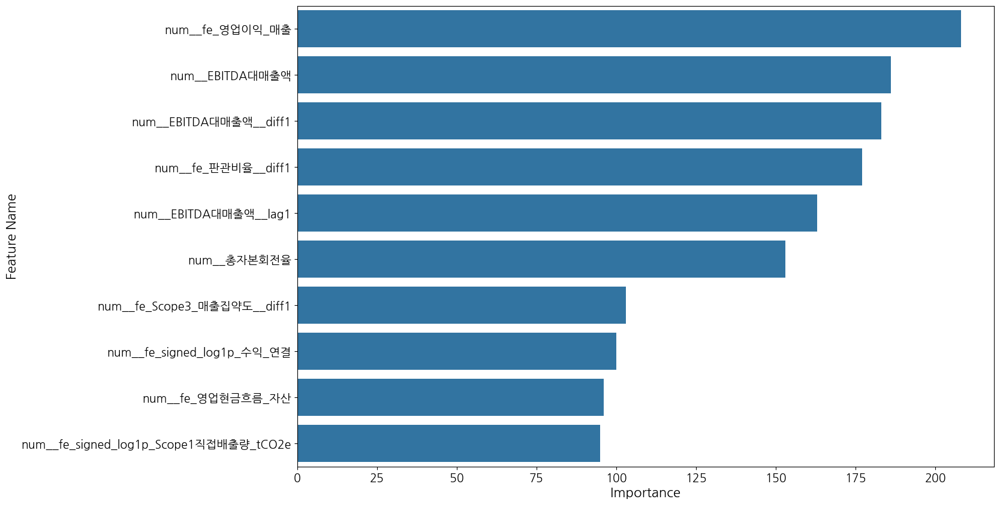

Performance Evaluations...:  2026-10-14 00:51:08.728888
Performance: 


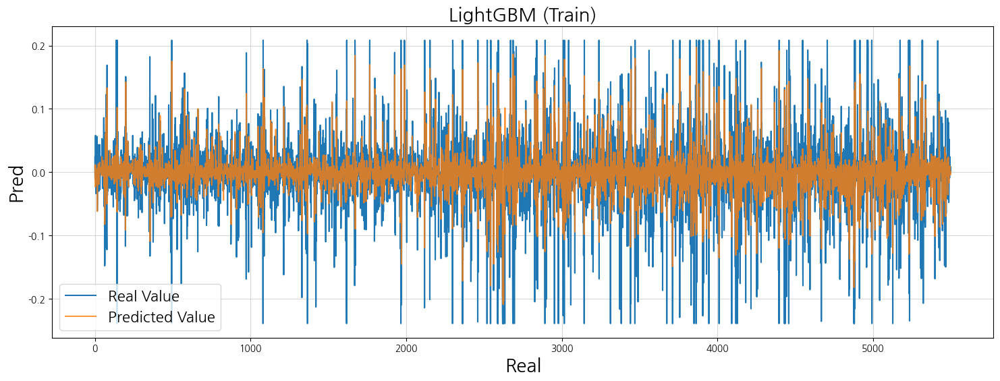

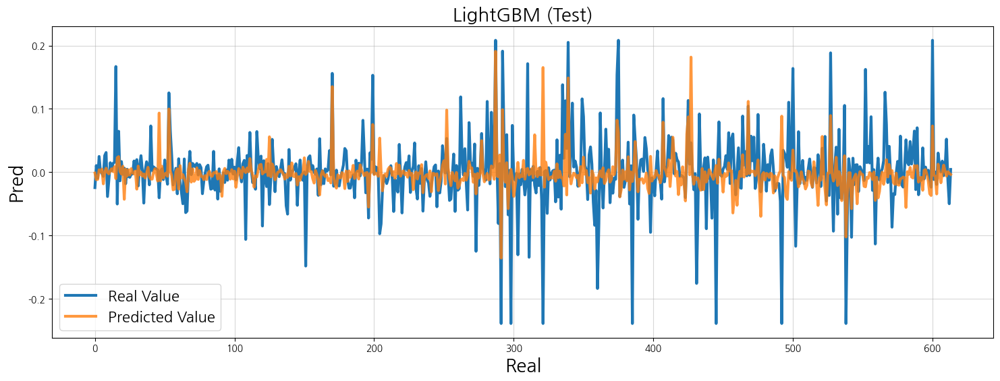

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0364,0.0013,0.0246,0.0246,0.0162,0.0162,0.6335
1,LightGBM,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0191,0.0191,0.1746
2,LightGBM,Test set,0.0508,0.0026,0.0312,0.0312,0.0185,0.0185,0.1033
3,LightGBM,Entire population,0.0381,0.0015,0.0252,0.0252,0.0164,0.0164,0.5904


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_model_LightGBM_20261014_005110.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_params_LightGBM_20261014_005110.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-14 00:51:10.602101


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

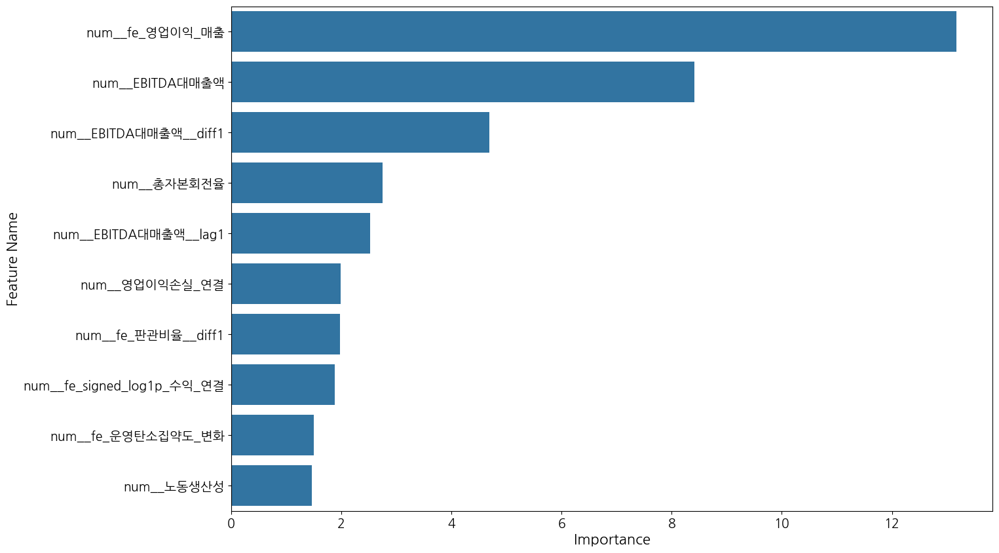

Performance Evaluations...:  2026-10-14 00:55:50.086730
Performance: 


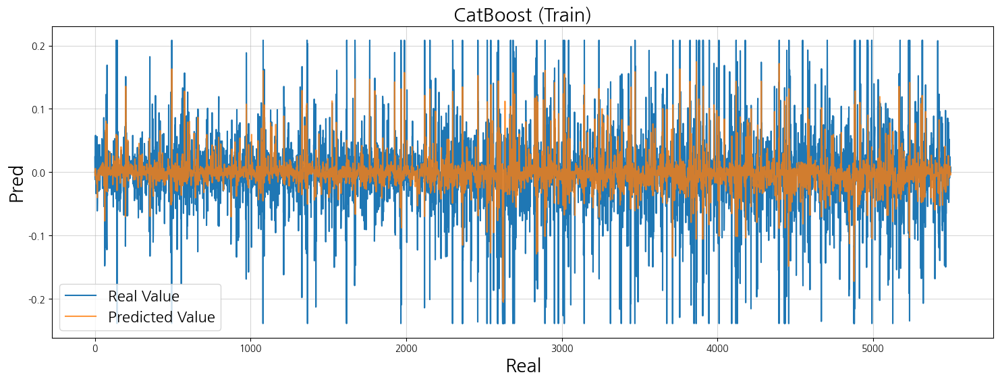

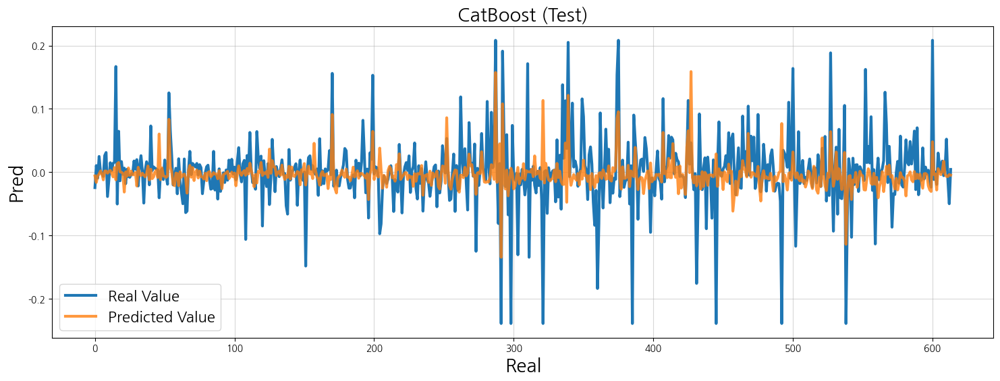

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0440,0.0019,0.0296,0.0296,0.0186,0.0186,0.4649
1,CatBoost,Validation(CV),0.0554,0.0031,0.0349,0.0349,0.0202,0.0202,0.1676
2,CatBoost,Test set,0.0499,0.0025,0.0309,0.0309,0.0183,0.0183,0.1327
3,CatBoost,Entire population,0.0446,0.0020,0.0297,0.0297,0.0185,0.0185,0.4380


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_model_CatBoost_20261014_005551.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/best_params_CatBoost_20261014_005551.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,3.0303,9.1825,2.0138,2.0138,1.3800,1.3800,-2539.1044
4,Random Forest,Train set,0.0458,0.0021,0.0293,0.0293,0.0171,0.0171,0.4198
8,XGBoost,Train set,0.0356,0.0013,0.0241,0.0241,0.0159,0.0159,0.6491
12,LightGBM,Train set,0.0364,0.0013,0.0246,0.0246,0.0162,0.0162,0.6335
16,CatBoost,Train set,0.0440,0.0019,0.0296,0.0296,0.0186,0.0186,0.4649


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),7.9466,63.1487,2.0961,2.0961,1.1144,1.1144,-17098.9453
5,Random Forest,Validation(CV),0.0566,0.0032,0.0356,0.0356,0.0195,0.0195,0.1324
9,XGBoost,Validation(CV),0.0546,0.0030,0.0344,0.0344,0.0184,0.0184,0.1934
13,LightGBM,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0191,0.0191,0.1746
17,CatBoost,Validation(CV),0.0554,0.0031,0.0349,0.0349,0.0202,0.0202,0.1676


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,11.2424,126.3909,6.9496,6.9496,6.8493,6.8493,-43985.3214
6,Random Forest,Test set,0.0504,0.0025,0.0313,0.0313,0.0179,0.0179,0.1167
10,XGBoost,Test set,0.0502,0.0025,0.0312,0.0312,0.0181,0.0181,0.1231
14,LightGBM,Test set,0.0508,0.0026,0.0312,0.0312,0.0185,0.0185,0.1033
18,CatBoost,Test set,0.0499,0.0025,0.0309,0.0309,0.0183,0.0183,0.1327


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,4.5775,20.9532,2.5095,2.5095,1.5478,1.5478,-5915.4885
7,Random Forest,Entire population,0.0463,0.0021,0.0295,0.0295,0.0172,0.0172,0.3953
11,XGBoost,Entire population,0.0373,0.0014,0.0248,0.0248,0.0161,0.0161,0.6063
15,LightGBM,Entire population,0.0381,0.0015,0.0252,0.0252,0.0164,0.0164,0.5904
19,CatBoost,Entire population,0.0446,0.0020,0.0297,0.0297,0.0185,0.0185,0.4380


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A+B+C (Financial + Carbon + ESG) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261014_004144.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C__Financial___Carbon___ESG_
Loading Model: Random Forest
   - File: best_model_Random Forest_20261014_004641.pkl
   - Successfully

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,11.5346 ± 9.1747,+11.4771,2.328,**,0.0200,11.2424
1,Random Forest,0.0579 ± 0.0109,+0.0003,0.539,ns,0.5900,0.0504
2,XGBoost,0.0581 ± 0.0117,+0.0006,2.920,***,0.0035,0.0502
3,LightGBM,0.0592 ± 0.0120,+0.0016,4.503,***,0.0000,0.0508
4,CatBoost (Best),0.0576 ± 0.0115,-,-,-,Benchmark,0.0499



################################################################################
 ▶ Processing Feature Block: [ Model A+B+C+D (Financial + Carbon + ESG + Macro) ]
################################################################################
▷ Valid Features: 838 / 838
▶ Inherited Task Type: [ REGRESSION ]

   Running Machine Learning Algorithm: Linear Regression (regression)
Learning...:  2026-10-14 00:56:21.158939


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 1] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 2] Params: {'fit_intercept': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 4] Params: {'fit_intercept': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 6] Params: {'fit_intercept': False, 'scaler_type': 'Normalizer'}
  ▶ [Trial 7] Params: {'fit_intercept': False, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 8] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 9] Params: {'fit_intercept': True, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 10] Params: {'fit_intercept': False, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 11] Params: {'fit_intercept': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 12] Params: {'fit_intercept': False, 'scaler_type': 

,Features,Coef,Features,Coef
0,cat__KSIC소분류_11차_C27300.사진장비_및_광학_기기_제조업,223.5000,cat__KSIC소분류_11차_E38200.폐기물_처리업,-230.2500
1,cat__KSIC소분류_11차_C23100.유리_및_유리제품_제조업,211.7500,missing__missingindicator_Scope2사업장간접배출량_tCO2e,-191.8750
2,cat__KSIC중분류_11차_A03000.어업,171.6875,cat__KSIC세분류_11차_G47120.음ㆍ식료품_위주_종합_소매업,-179.0000
3,cat__KSIC소분류_11차_G47100.종합_소매업,171.0000,cat__KSIC세분류_11차_G47110.대형_종합_소매업,-175.7500
4,cat__KSIC소분류_11차_C15100.가죽__가방_및_유사_제품_제조업,169.8750,cat__KSIC소분류_11차_S96900.그_외_기타_개인_서비스업,-174.3125
...,...,...,...,...
415,cat__기부금_출처_xml_table,0.0010,missing__missingindicator_지배구조등급,-0.0011
416,num__기말종가,0.0009,missing__missingindicator_환경등급,-0.0006
417,num__fe_배출권_부족여부,0.0004,cat__Trucost산업_Textiles__Apparel_and_Luxury_Goods,-0.0005
418,NaN,NaN,num__매입채무회전율,-0.0003


Performance Evaluations...:  2026-10-14 00:57:39.629247
Performance: 


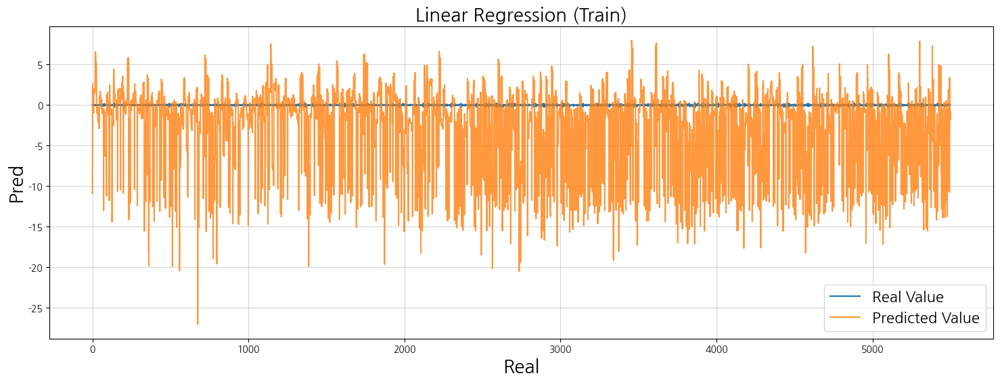

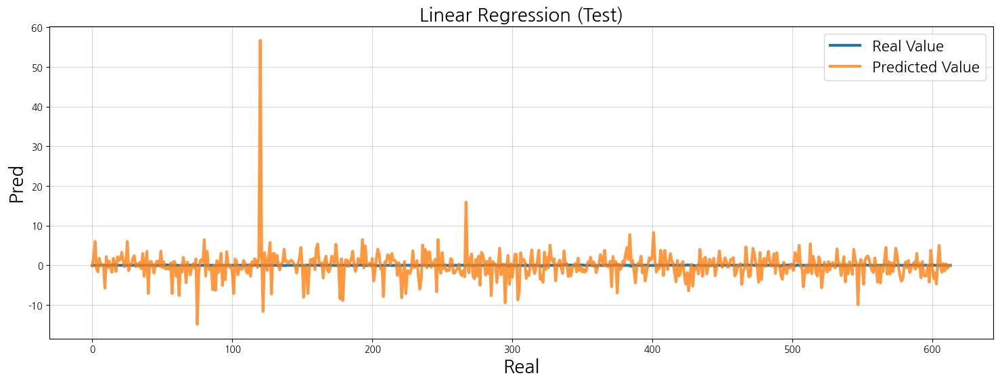

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,4.8747,23.7631,3.0720,3.0720,1.5652,1.5652,"-6,572.4555"
1,Linear Regression,Validation(CV),1.1520,1.3270,0.7035,0.7035,0.5329,0.5329,-358.3352
2,Linear Regression,Test set,3.6145,13.0648,2.0403,2.0403,1.3862,1.3862,"-4,545.7961"
3,Linear Regression,Entire population,4.7633,22.6888,2.9684,2.9684,1.5467,1.5467,"-6,405.5537"


   [Save] Linear Regression Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_model_Linear Regression_20261014_005740.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_params_Linear Regression_20261014_005740.json

   Running Machine Learning Algorithm: Random Forest (regression)
Learning...:  2026-10-14 00:57:40.188074


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'use_max_depth': True, 'n_estimators': 200, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_split': 10, 'min_samples_leaf': 38, 'bootstrap': True, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'use_max_depth': True, 'n_estimators': 100, 'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 39, 'bootstrap': False, 'scaler_type': 'None'}
  ▶ [Trial 2] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_split': 4, 'min_samples_leaf': 27, 'bootstrap': False, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 3] Params: {'use_max_depth': True, 'n_estimators': 300, 'max_depth': 12, 'max_features': 'log2', 'min_samples_split': 3, 'min_samples_leaf': 43, 'bootstrap': True, 'scaler_type': 'None'}
  ▶ [Trial 4] Params: {'use_max_depth': False, 'n_estimators': 300, 'max_features': 'log2', 'min_samples_split': 9, 'min_samples_leaf': 13, 'bootstrap': True, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 5] Par

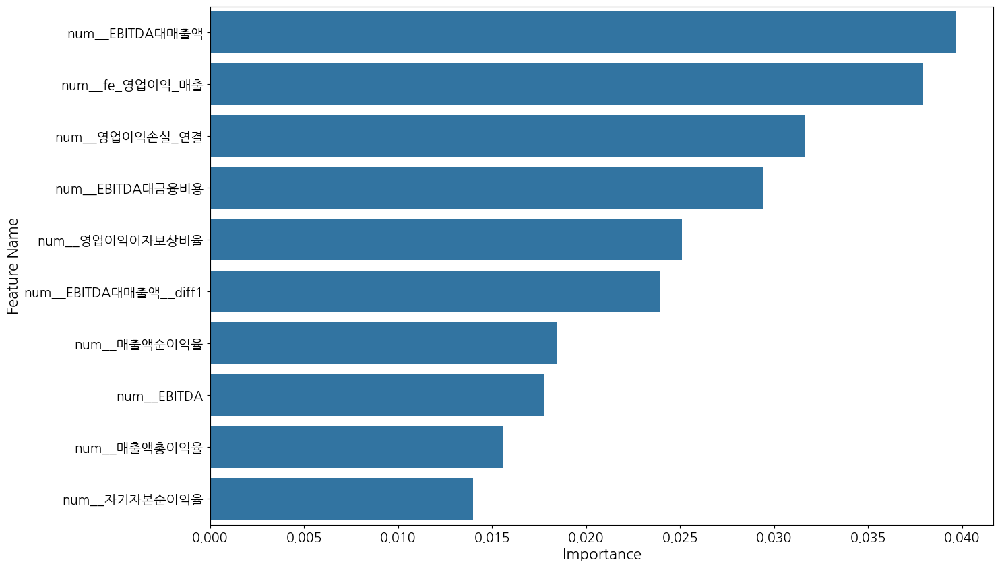

Performance Evaluations...:  2026-10-14 01:07:20.999310
Performance: 


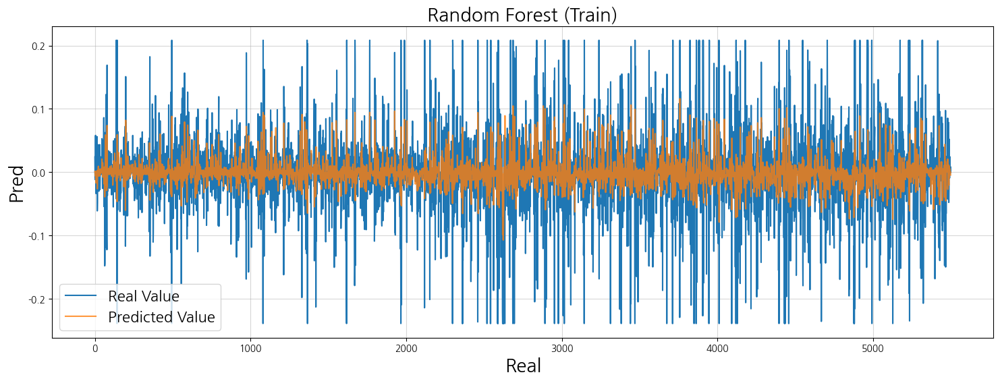

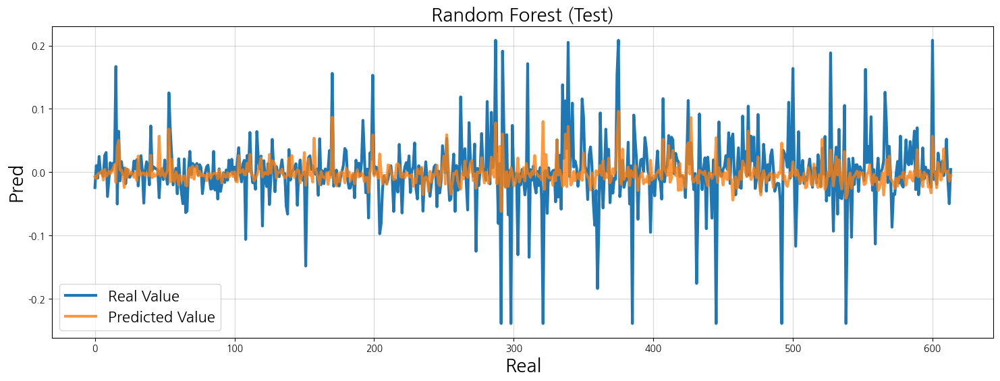

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Random Forest,Train set,0.0472,0.0022,0.0300,0.0300,0.0176,0.0176,0.3826
1,Random Forest,Validation(CV),0.0569,0.0032,0.0354,0.0354,0.0199,0.0199,0.1242
2,Random Forest,Test set,0.0508,0.0026,0.0311,0.0311,0.0171,0.0171,0.1019
3,Random Forest,Entire population,0.0476,0.0023,0.0301,0.0301,0.0175,0.0175,0.3599


   [Save] Random Forest Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_model_Random Forest_20261014_010723.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_params_Random Forest_20261014_010723.json

   Running Machine Learning Algorithm: XGBoost (regression)
Learning...:  2026-10-14 01:07:23.462993


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.019730611515265114, 'subsample': 0.6653944307248674, 'colsample_bytree': 0.7158406909356689, 'reg_alpha': 0.04925222337791059, 'reg_lambda': 8.376388146302443, 'scaler_type': 'None'}
  ▶ [Trial 1] Params: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03295091780345519, 'subsample': 0.7213986217196108, 'colsample_bytree': 0.55474751913605, 'reg_alpha': 0.005032769318663508, 'reg_lambda': 0.1337228103857309, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.029559555088916174, 'subsample': 0.5684789692636867, 'colsample_bytree': 0.5881142139166489, 'reg_alpha': 0.3341215561348895, 'reg_lambda': 0.002335714515891042, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'max_depth': 12, 'learning_rate': 0.16919226498808898, 'subsample': 0.650551002765301, 'colsample_bytree': 0.6871858855376334, 'reg_alpha': 0.0029005

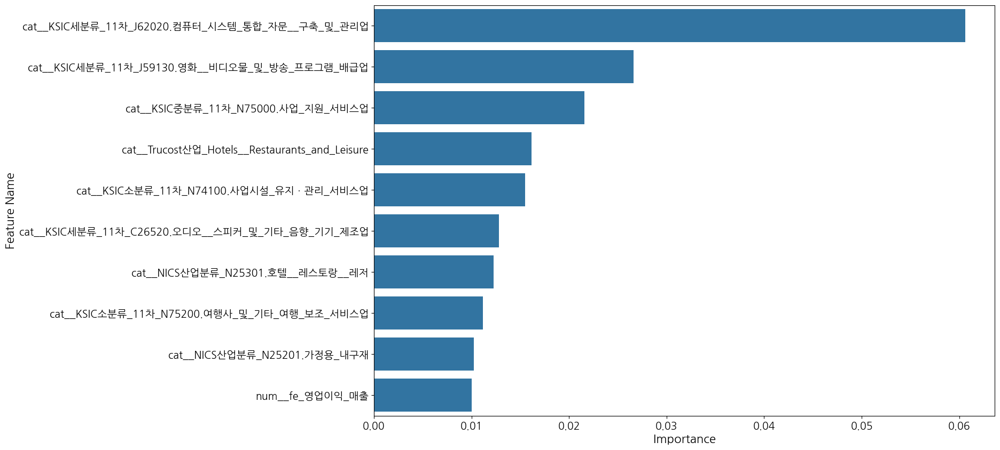

Performance Evaluations...:  2026-10-14 01:13:01.982319
Performance: 


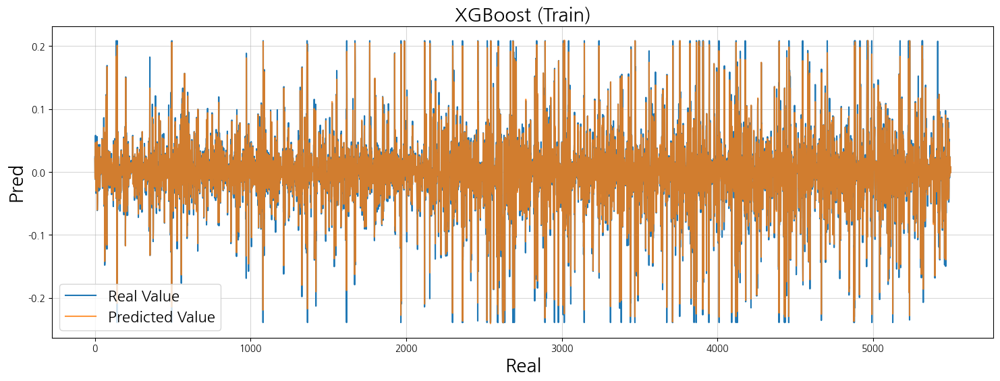

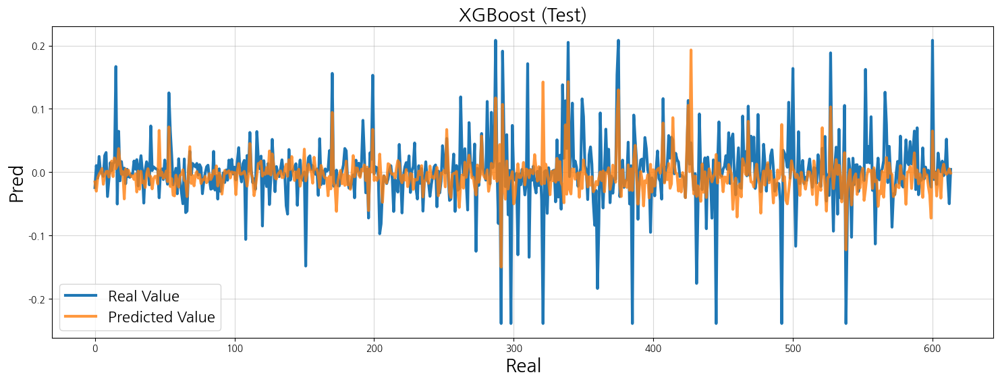

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,XGBoost,Train set,0.0052,0.0000,0.0031,0.0031,0.0018,0.0018,0.9926
1,XGBoost,Validation(CV),0.0555,0.0031,0.0352,0.0352,0.0190,0.0190,0.1647
2,XGBoost,Test set,0.0504,0.0025,0.0321,0.0321,0.0202,0.0202,0.1150
3,XGBoost,Entire population,0.0167,0.0003,0.0060,0.0060,0.0021,0.0021,0.9210


   [Save] XGBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_model_XGBoost_20261014_011305.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_params_XGBoost_20261014_011305.json

   Running Machine Learning Algorithm: LightGBM (regression)
Learning...:  2026-10-14 01:13:05.898843


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'learning_rate': 0.023565456530639496, 'num_leaves': 53, 'max_depth': 8, 'subsample': 0.7158406909356689, 'colsample_bytree': 0.6269319380373383, 'reg_alpha': 8.376388146302443, 'reg_lambda': 0.5486797781181635, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 100, 'learning_rate': 0.03295091780345519, 'num_leaves': 102, 'max_depth': 5, 'subsample': 0.5526355268442478, 'colsample_bytree': 0.6594654121525515, 'reg_alpha': 0.1340634367310212, 'reg_lambda': 0.3448290408913143, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 200, 'learning_rate': 0.01981423503611216, 'num_leaves': 59, 'max_depth': 9, 'subsample': 0.5276314819835226, 'colsample_bytree': 0.6301103518038584, 'reg_alpha': 0.052899437412125536, 'reg_lambda': 0.09434967110751795, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 300, 'learning_rate': 0.06483081872184877, 'num_leaves': 42, 'max_depth': 6, 'subsample': 0.62444786358608

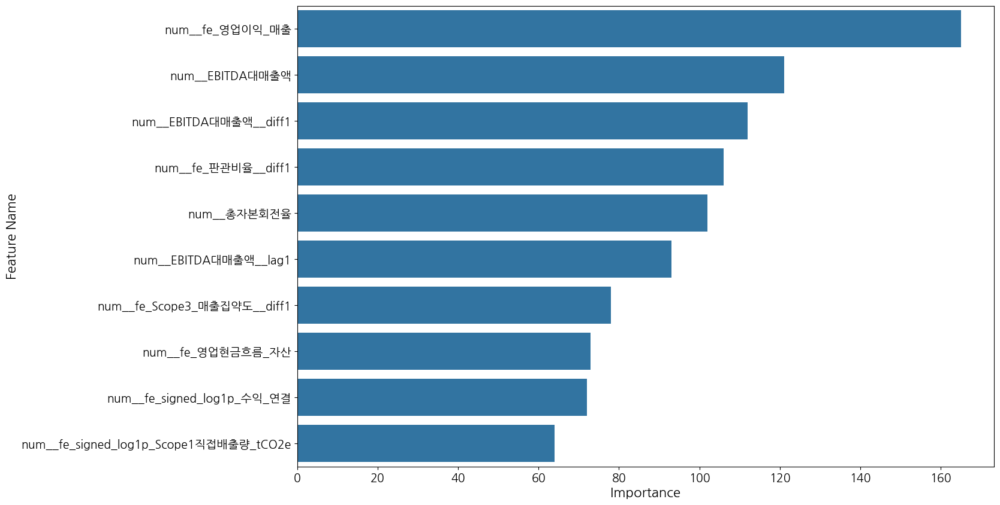

Performance Evaluations...:  2026-10-14 01:15:17.794718
Performance: 


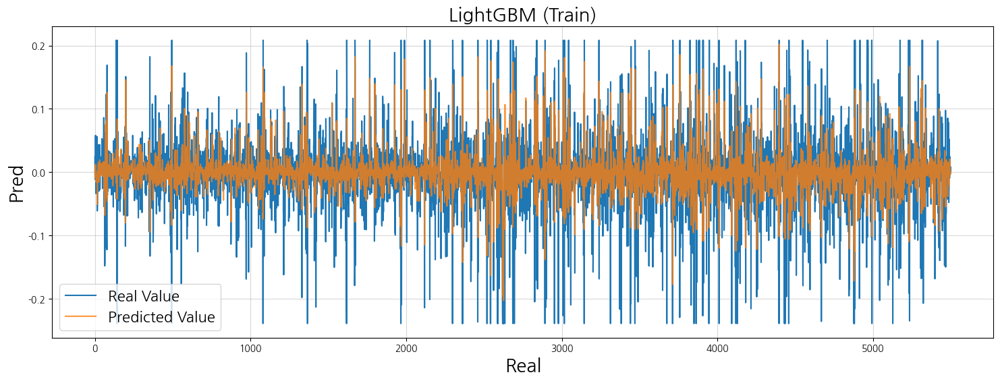

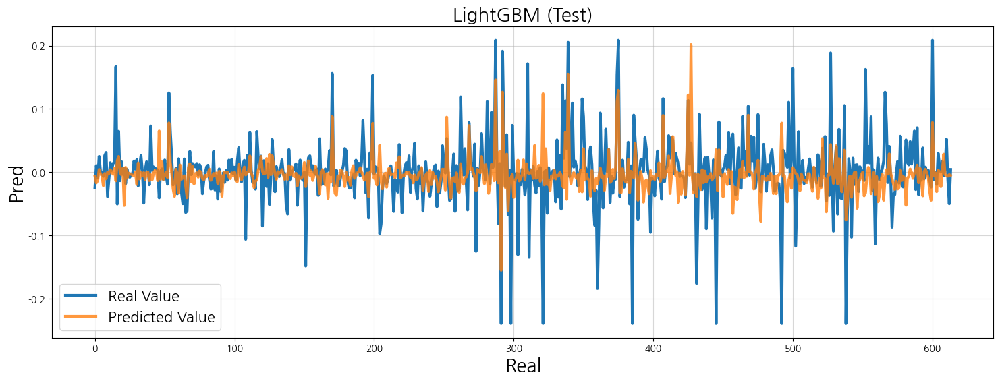

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0390,0.0015,0.0262,0.0262,0.0169,0.0169,0.5795
1,LightGBM,Validation(CV),0.0557,0.0031,0.0349,0.0349,0.0200,0.0200,0.1608
2,LightGBM,Test set,0.0503,0.0025,0.0312,0.0312,0.0190,0.0190,0.1202
3,LightGBM,Entire population,0.0403,0.0016,0.0267,0.0267,0.0171,0.0171,0.5422


   [Save] LightGBM Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_model_LightGBM_20261014_011519.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_params_LightGBM_20261014_011519.json

   Running Machine Learning Algorithm: CatBoost (regression)
Learning...:  2026-10-14 01:15:19.521518


  0%|          | 0/100 [00:00<?, ?it/s]

  ▶ [Trial 0] Params: {'n_estimators': 400, 'depth': 5, 'learning_rate': 0.019730611515265114, 'l2_leaf_reg': 6.859203383580239, 'subsample': 0.7158406909356689, 'scaler_type': 'MinMaxScaler'}
  ▶ [Trial 1] Params: {'n_estimators': 200, 'depth': 7, 'learning_rate': 0.0372045148431395, 'l2_leaf_reg': 3.417745276266978, 'subsample': 0.6194132765991295, 'scaler_type': 'Normalizer'}
  ▶ [Trial 2] Params: {'n_estimators': 400, 'depth': 8, 'learning_rate': 0.08760685869015218, 'l2_leaf_reg': 7.27716457474308, 'subsample': 0.7167330147710664, 'scaler_type': 'None'}
  ▶ [Trial 3] Params: {'n_estimators': 100, 'depth': 6, 'learning_rate': 0.03635510297463976, 'l2_leaf_reg': 6.455795683552143, 'subsample': 0.6277490870887484, 'scaler_type': 'RobustScaler'}
  ▶ [Trial 4] Params: {'n_estimators': 400, 'depth': 4, 'learning_rate': 0.025870089371054037, 'l2_leaf_reg': 5.903783483675422, 'subsample': 0.7598927473650099, 'scaler_type': 'StandardScaler'}
  ▶ [Trial 5] Params: {'n_estimators': 100, 'dep

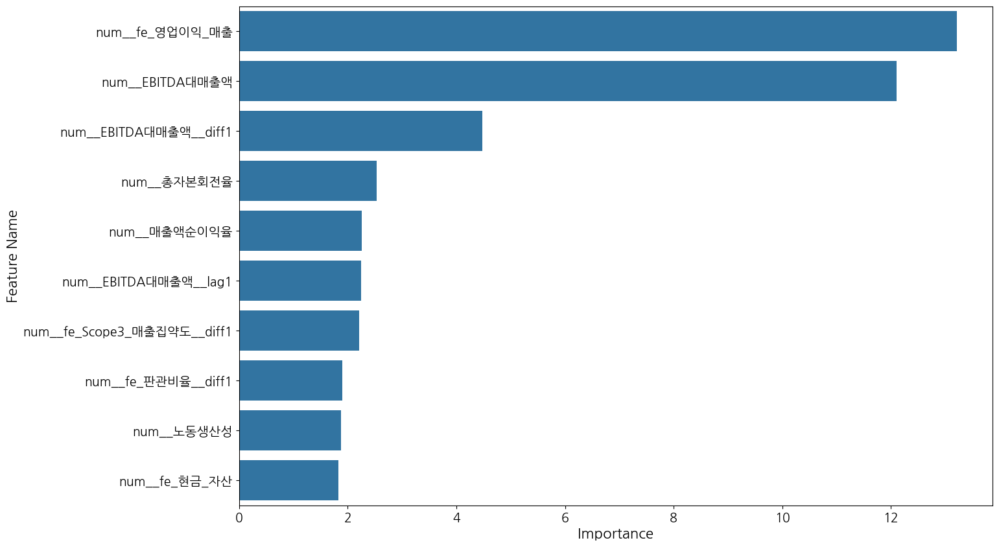

Performance Evaluations...:  2026-10-14 01:17:55.047764
Performance: 


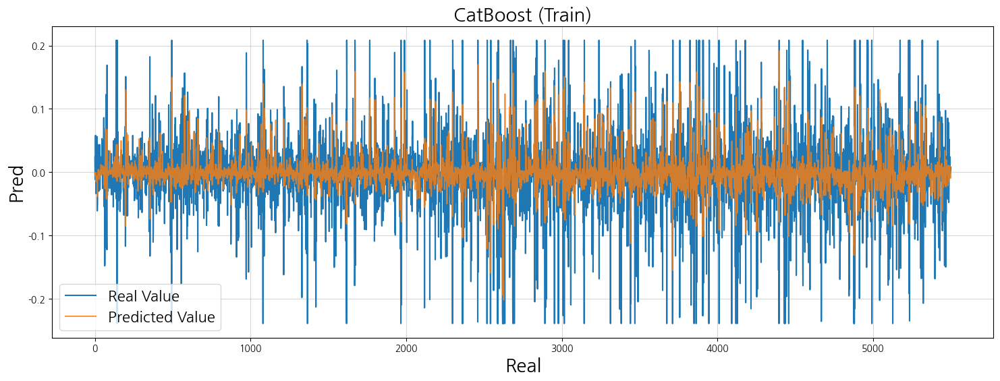

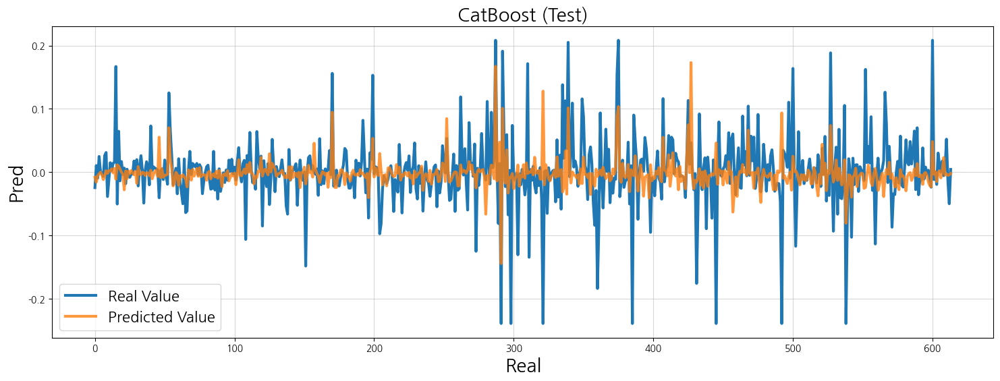

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,CatBoost,Train set,0.0463,0.0021,0.0311,0.0311,0.0197,0.0197,0.4058
1,CatBoost,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0200,0.0200,0.1748
2,CatBoost,Test set,0.0507,0.0026,0.0311,0.0311,0.0182,0.0182,0.1070
3,CatBoost,Entire population,0.0468,0.0022,0.0311,0.0311,0.0195,0.0195,0.3816


   [Save] CatBoost Checkpoint Saved:
     - Model : /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_model_CatBoost_20261014_011756.pkl
     - Params: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/best_params_CatBoost_20261014_011756.json

   Modeling Completed. Summary of Performance (regression)


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,Linear Regression,Train set,4.8747,23.7631,3.0720,3.0720,1.5652,1.5652,-6572.4555
4,Random Forest,Train set,0.0472,0.0022,0.0300,0.0300,0.0176,0.0176,0.3826
8,XGBoost,Train set,0.0052,0.0000,0.0031,0.0031,0.0018,0.0018,0.9926
12,LightGBM,Train set,0.0390,0.0015,0.0262,0.0262,0.0169,0.0169,0.5795
16,CatBoost,Train set,0.0463,0.0021,0.0311,0.0311,0.0197,0.0197,0.4058


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
1,Linear Regression,Validation(CV),1.1520,1.3270,0.7035,0.7035,0.5329,0.5329,-358.3352
5,Random Forest,Validation(CV),0.0569,0.0032,0.0354,0.0354,0.0199,0.0199,0.1242
9,XGBoost,Validation(CV),0.0555,0.0031,0.0352,0.0352,0.0190,0.0190,0.1647
13,LightGBM,Validation(CV),0.0557,0.0031,0.0349,0.0349,0.0200,0.0200,0.1608
17,CatBoost,Validation(CV),0.0552,0.0030,0.0346,0.0346,0.0200,0.0200,0.1748


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
2,Linear Regression,Test set,3.6145,13.0648,2.0403,2.0403,1.3862,1.3862,-4545.7961
6,Random Forest,Test set,0.0508,0.0026,0.0311,0.0311,0.0171,0.0171,0.1019
10,XGBoost,Test set,0.0504,0.0025,0.0321,0.0321,0.0202,0.0202,0.1150
14,LightGBM,Test set,0.0503,0.0025,0.0312,0.0312,0.0190,0.0190,0.1202
18,CatBoost,Test set,0.0507,0.0026,0.0311,0.0311,0.0182,0.0182,0.1070


,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
3,Linear Regression,Entire population,4.7633,22.6888,2.9684,2.9684,1.5467,1.5467,-6405.5537
7,Random Forest,Entire population,0.0476,0.0023,0.0301,0.0301,0.0175,0.0175,0.3599
11,XGBoost,Entire population,0.0167,0.0003,0.0060,0.0060,0.0021,0.0021,0.9210
15,LightGBM,Entire population,0.0403,0.0016,0.0267,0.0267,0.0171,0.0171,0.5422
19,CatBoost,Entire population,0.0468,0.0022,0.0311,0.0311,0.0195,0.0195,0.3816


Saved total performance to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Performance_ML(Trial100).csv
Saved total parameters to: /workspace/DataScience/DIVE/Project/CO2XAI/Result/Hyperparams_ML(Trial100).csv
Saved total results object to: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_/Best_Result_ML(Trial100).pkl
▷ [Warning] DL modeling skipped for Model A+B+C+D (Financial + Carbon + ESG + Macro) (name 'modeling_DL' is not defined)

★★★ Time-Series Walk-Forward CV & Diebold-Mariano Test (10-Splits) (REGRESSION) ★★★
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_
Loading Model: Linear Regression
   - File: best_model_Linear Regression_20261014_005740.pkl
   - Successfully Loaded.
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_
Loading Model: Random Forest
   - File: best_model_Random Fore

,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Linear Regression,450553.9050 ± 1351056.9822,+450553.8473,4.596,***,0.0000,3.6145
1,Random Forest (Best),0.0577 ± 0.0109,-,-,-,Benchmark,0.0508
2,XGBoost,0.0584 ± 0.0117,+0.0007,2.135,**,0.0328,0.0504
3,LightGBM,0.0586 ± 0.0118,+0.0010,2.325,**,0.0201,0.0503
4,CatBoost,0.0581 ± 0.0118,+0.0004,1.349,ns,0.1774,0.0507



 [Final Summary] Consolidated Feature Blocks Performance & Significance


,Model,Num_Features,Algorithm,TimeSeries CV (Mean ± Std),Diff vs Best,DM Statistic,Significance,p-value,Single RMSE
0,Model A (Financial),141,Linear Regression,0.2429 ± 0.2419,+0.1854,1.973,**,0.0485,0.1319
1,Model A (Financial),141,Random Forest,0.0577 ± 0.0112,+0.0001,0.663,ns,0.5072,0.0500
2,Model A (Financial),141,XGBoost,0.0581 ± 0.0117,+0.0006,2.156,**,0.0311,0.0510
3,Model A (Financial),141,LightGBM,0.0581 ± 0.0115,+0.0006,3.049,***,0.0023,0.0523
4,Model A (Financial),141,CatBoost (Best),0.0575 ± 0.0112,-,-,-,Benchmark,0.0509
5,Model A+B (Financial + Carbon),272,Linear Regression,5051.9011 ± 11203.0698,+5051.8436,5.204,***,0.0000,93.5633
6,Model A+B (Financial + Carbon),272,Random Forest (Best),0.0576 ± 0.0109,-,-,-,Benchmark,0.0504
7,Model A+B (Financial + Carbon),272,XGBoost,0.0579 ± 0.0114,+0.0003,1.127,ns,0.2596,0.0513
8,Model A+B (Financial + Carbon),272,LightGBM,0.0592 ± 0.0119,+0.0016,2.904,***,0.0037,0.0526
9,Model A+B (Financial + Carbon),272,CatBoost,0.0576 ± 0.0114,+0.0000,0.360,ns,0.7188,0.0511


▶ Comparison table saved to: 'Result/Performance_MetricSignificance_FeatureAblation.csv'



In [10]:
# Feature Ablation Statistical Test
df_significance_comparison, model_execution_results = evaluation_MetricSignificanceFeatureAblation(
    model_configs=model_configs,
    Y_train=Y_train, Y_test=Y_test, X_train_full=X_train, X_test_full=X_test, task=TASK,
    test_size=TEST_SIZE, target_metric=METRIC_FINAL,
    algo_names_ml=ALGO_NAMES_ML,
    algo_names_dl=ALGO_NAMES_DL,
    cv_splits=CV_SPLITS,
    tune_trials_ml=TUNE_TRIALS_ML, tune_metric_ml=TUNE_METRIC_ML, tune_trials_dl=TUNE_TRIALS_DL, tune_metric_dl=TUNE_METRIC_DL,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT, validation_data=VALIDATION_DATA,
    class_weight_method=CLASS_WEIGHT_METHOD, label_list=LABEL_LIST,
    random_state=RANDOM_STATE,
    force_rerun=False, # True 설정 시 기존 캐시 무시하고 전체 재실행
)

In [11]:
# Best Result Selection
BEST_BLOCK = 'Model A+B+C+D (Financial + Carbon + ESG + Macro)'
df_scores = model_execution_results[BEST_BLOCK]['scores']
df_significance = model_execution_results[BEST_BLOCK]['significance']
X_train_ablation = X_train[model_execution_results[BEST_BLOCK]['features']]
X_test_ablation = X_test[model_execution_results[BEST_BLOCK]['features']]
model_folder = model_execution_results[BEST_BLOCK]['model_dir']

## Performance

### Best Model Prediction

▶ [Auto-Detected Table]: Prediction Summary df_scores (Holdout Test set)
▶ Selected Best Algorithm: [ LightGBM ] (Task: REGRESSION)
▶ Searching Directory: /workspace/DataScience/DIVE/Project/CO2XAI/Model/Model_A_B_C_D__Financial___Carbon___ESG___Macro_
Loading Model: LightGBM
   - File: best_model_LightGBM_20261014_011519.pkl
   - Successfully Loaded.
[LightGBM] 모델 내부 변수명이 성공적으로 수정되었습니다.
Performance: 


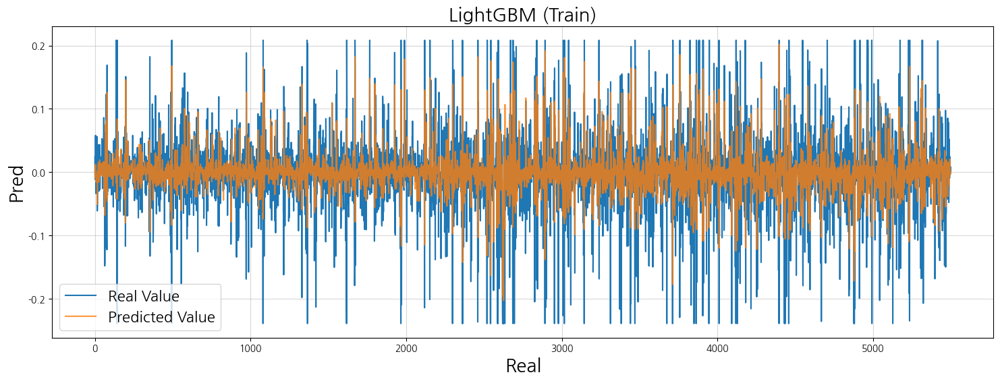

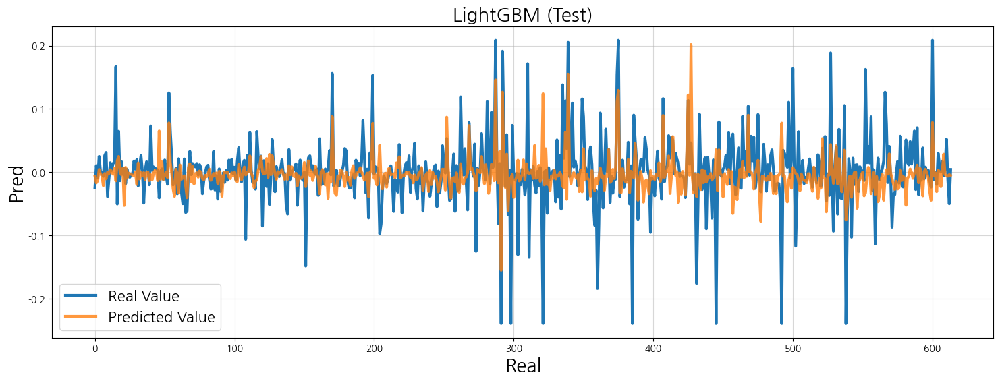

,Algorithm,Dataset,RMSE,MSPE,MAE,MAPE,MedAE,MedAPE,R2
0,LightGBM,Train set,0.0390,0.0015,0.0262,0.0262,0.0169,0.0169,0.5795
1,LightGBM,Test set,0.0503,0.0025,0.0312,0.0312,0.0190,0.0190,0.1202
2,LightGBM,Entire population,0.0403,0.0016,0.0267,0.0267,0.0171,0.0171,0.5422


Saved: ./Result/Screening_Report_LGBMRegressor.csv


,Feature,Feature Importance (Gini/Gain/Mask),Importance (%),Cumulative Importance (%)
0,num__fe_영업이익_매출,165,3.5987,3.5987
1,num__EBITDA대매출액,121,2.6390,6.2377
2,num__EBITDA대매출액__diff1,112,2.4427,8.6805
3,num__fe_판관비율__diff1,106,2.3119,10.9924
4,num__총자본회전율,102,2.2246,13.2170
...,...,...,...,...
833,cat__Scope3보고추정구분_반려됨,0,0.0000,100.0000
834,cat__Scope3보고추정구분_보고값,0,0.0000,100.0000
835,cat__Scope3보고추정구분_산출값,0,0.0000,100.0000
836,cat__KSIC세분류_11차_J59140.영화_및_비디오물_상영업,0,0.0000,100.0000


In [12]:
# Best Result
BEST_ALGO, BEST_MODEL, BEST_PARAMS, BEST_TESTSCORE, BEST_PREDIMPORTANCE = prediction_best(
    df_scores=df_scores,
    # df_scores=df_significance,
    X_train=locals().get('X_train_ablation', X_train), Y_train=Y_train, 
    X_test=locals().get('X_test_ablation', X_test), Y_test=Y_test,
    target_metric=METRIC_FINAL, task=TASK,
    folder_name=locals().get('model_folder', 'Model')
)


### Subgroup Robustness

In [ ]:
target_group = 'num__fe_Scope1_2_매출집약도'
# groups = {f"{target_group}_{val}": val for val in sorted(X_test[target_group].dropna().unique())}
groups = {
    '1': lambda x: x < 0,
    '2': lambda x: x>= 0
}
key_features=None

df_fairness = evaluation_reg_GroupFairness(
    best_model=BEST_MODEL,
    target_col=target_group,
    groups_dict=groups,
    X_test=X_test, Y_test=Y_test, X_colname=X_colname,
)

# XAI

## Explanation

[Auto-Config] Detected Algorithm: LightGBM | Type: Tree | Link: identity
[SHAP] Pipeline 객체가 감지되어 내부 스케일러로 데이터를 자동 변환합니다.
Total SHAP Calculation...: 2026-10-15 03:41:17.689320


 99%|===================| 14838/14918 [01:44<00:00]        

SHAP values saved to /workspace/DataScience/DIVE/Project/PublicProcurement/Model/shap_values_LightGBM_20261015_034924.pkl

[Train Dataset Contribution Calculation]: 2026-10-15 03:49:24.566417
Feature Total Contribution (Calculating Metrics)...
Feature Contribution Direction (Calculating Pearson & Spearman)...


Calculating 1D Directions: 100%|██████████| 22/22 [00:00<00:00, 193.89it/s]


,Feature,Importance,Importance Percentage,Contribution Range,"Ground Truth Correlation (Y, X)","Prediction Correlation (Y_hat, X)","Total Contribution Correlation (Y_shap, X)","Total Contribution Spearman Correlation (Y_shap, X)","Pure Main Effect Correlation (Y_pure, X)",Feature,Importance,Importance Percentage,Contribution Range,"Ground Truth Correlation (Y, X)","Prediction Correlation (Y_hat, X)","Total Contribution Correlation (Y_shap, X)","Total Contribution Spearman Correlation (Y_shap, X)","Pure Main Effect Correlation (Y_pure, X)"
0,base_amount_krw,"13,142,518.6915",2.8731,"25,029,940.0683",0.0082,0.0079,0.4858,0.4966,NaN,procurement_method_자체조달,"127,046,542.4012",27.7741,"287,471,309.7272",-0.0368,-0.0369,-0.0514,-0.9383,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,notice_status_등록공고,"94,507,926.7116",20.6607,"201,366,461.0050",-0.0350,-0.0351,-0.0447,-0.9527,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,procurement_method_중앙조달,"77,552,808.0683",16.9541,"150,762,714.6862",-0.0696,-0.0697,-0.4126,-0.3913,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,notice_month,"30,335,940.6855",6.6319,"140,727,490.8352",-0.0365,-0.0366,-0.0273,-0.6377,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,model_row_id,"25,894,286.2079",5.6608,"75,641,042.2868",-0.0294,-0.0295,-0.0249,-0.8980,NaN



[Test Dataset Contribution Calculation]: 2026-10-15 03:49:24.704367
Feature Total Contribution (Calculating Metrics)...
Feature Contribution Direction (Calculating Pearson & Spearman)...


Calculating 1D Directions: 100%|██████████| 22/22 [00:00<00:00, 631.82it/s]


,Feature,Importance,Importance Percentage,Contribution Range,"Ground Truth Correlation (Y, X)","Prediction Correlation (Y_hat, X)","Total Contribution Correlation (Y_shap, X)","Total Contribution Spearman Correlation (Y_shap, X)","Pure Main Effect Correlation (Y_pure, X)",Feature,Importance,Importance Percentage,Contribution Range,"Ground Truth Correlation (Y, X)","Prediction Correlation (Y_hat, X)","Total Contribution Correlation (Y_shap, X)","Total Contribution Spearman Correlation (Y_shap, X)","Pure Main Effect Correlation (Y_pure, X)"
0,base_amount_krw,"12,672,403.2054",3.1413,"22,323,928.1250",-0.0569,-0.0601,0.3733,0.7003,NaN,procurement_method_자체조달,"112,942,650.5492",27.9970,"273,738,073.3548",-0.0351,-0.0352,-0.0496,-0.9597,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,notice_status_등록공고,"80,545,430.6103",19.9661,"164,867,622.8040",-0.0329,-0.0329,-0.0441,-0.9536,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,procurement_method_중앙조달,"75,777,341.5959",18.7842,"142,388,200.6674",-0.0157,-0.0150,-0.1389,-0.2803,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,notice_month,"25,209,213.5099",6.2490,"142,136,406.6794",-0.0589,-0.0590,-0.0403,-0.5617,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,industry_restriction_Y,"17,318,514.8161",4.2930,"40,330,457.5532",-0.0313,-0.0313,-0.0286,-0.9105,NaN



[Train Dataset Beeswarm Visualization]: 2026-10-15 03:49:24.751212
Total Explanation (Beeswarm + Importance Percentage & Correlation Bar)...


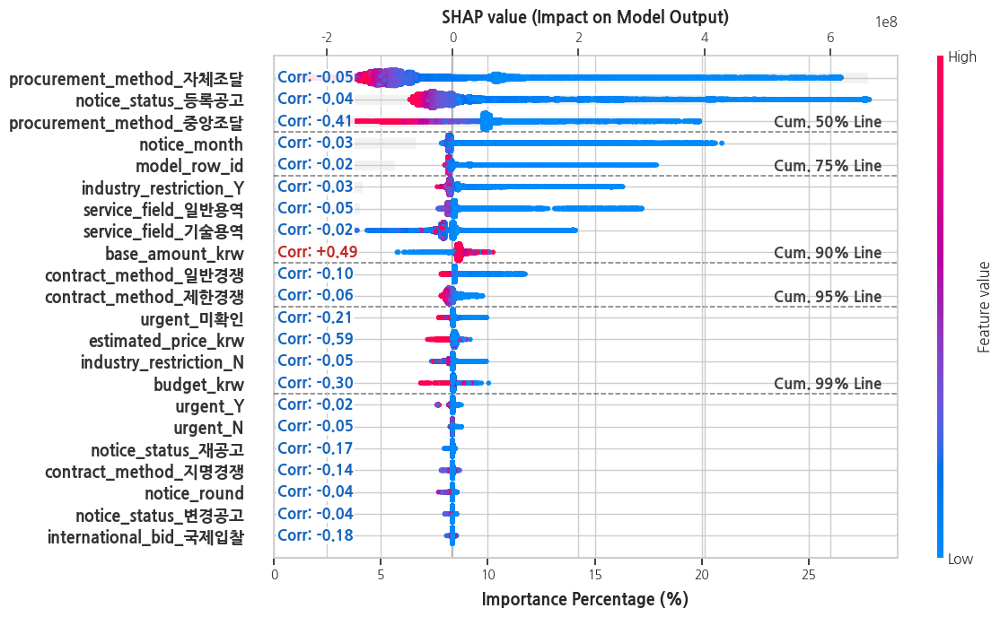


[Test Dataset Beeswarm Visualization]: 2026-10-15 03:49:27.439584
Total Explanation (Beeswarm + Importance Percentage & Correlation Bar)...


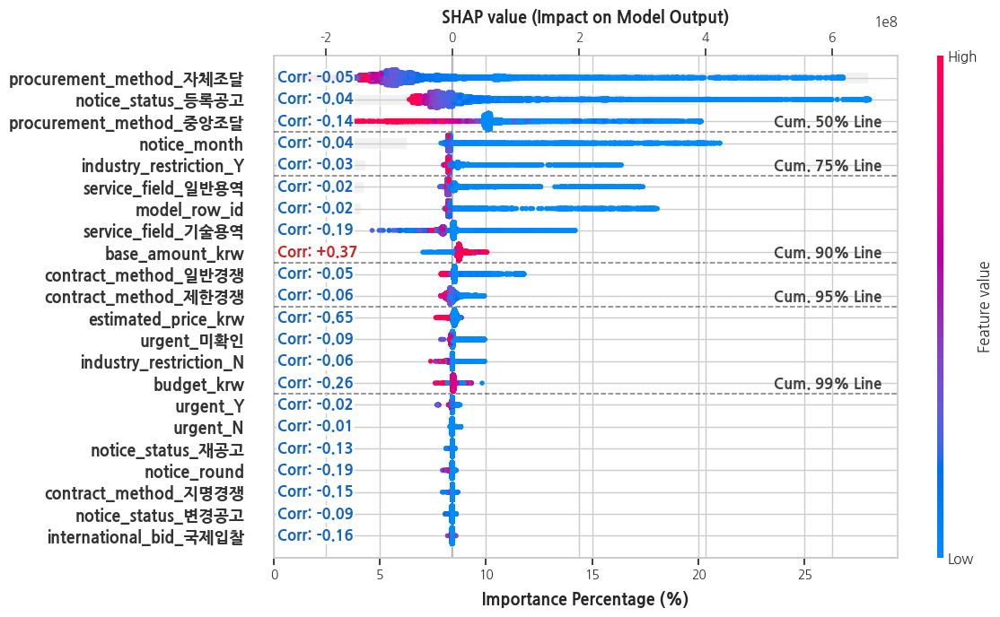


[Test Dataset Sensitivity Analysis]: 2026-10-15 03:49:28.370343
Sensitivity Analysis (ICE & PDP Plot) for Top 50 Features...
▶ [Warning] ICE Plot 생성 실패. 에러 메시지: Expected ax to have 22 axes, got 50

[Train Dataset Individual]: 2026-10-15 03:49:29.054458
Individual Explanation(1 Decision Plot -> 1 Force Plot -> 1000 Force Plot)...
Visualizing random index: 3793


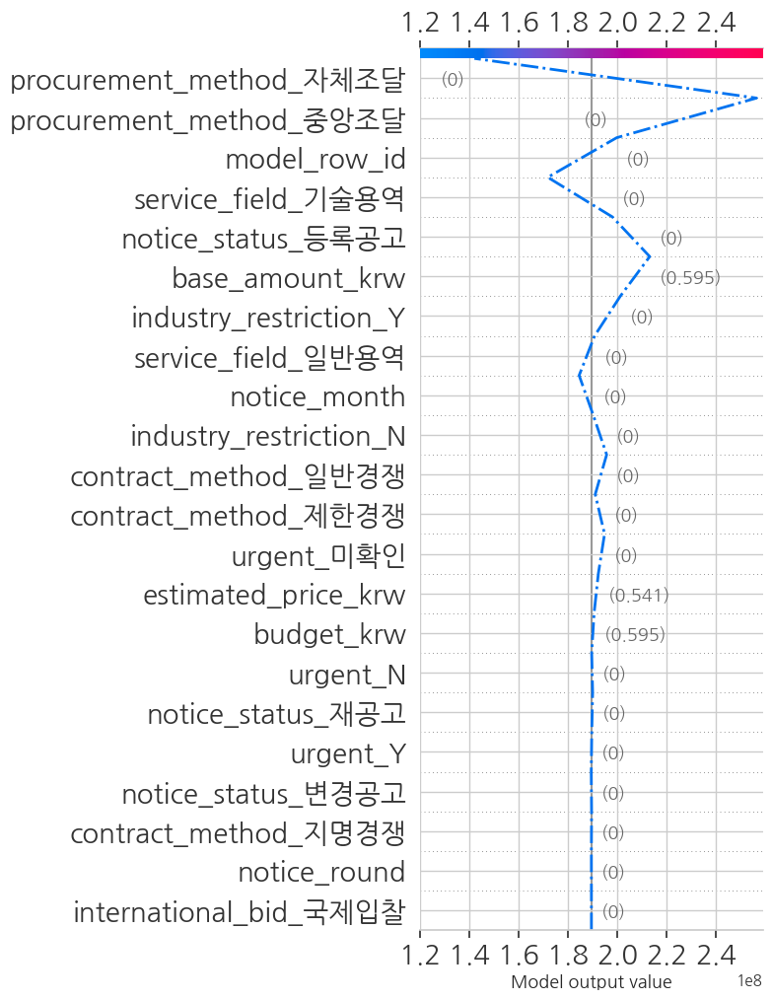


[Test Dataset Individual]: 2026-10-15 03:49:29.151384
Individual Explanation(1 Decision Plot -> 1 Force Plot -> 1000 Force Plot)...
Visualizing random index: 2302


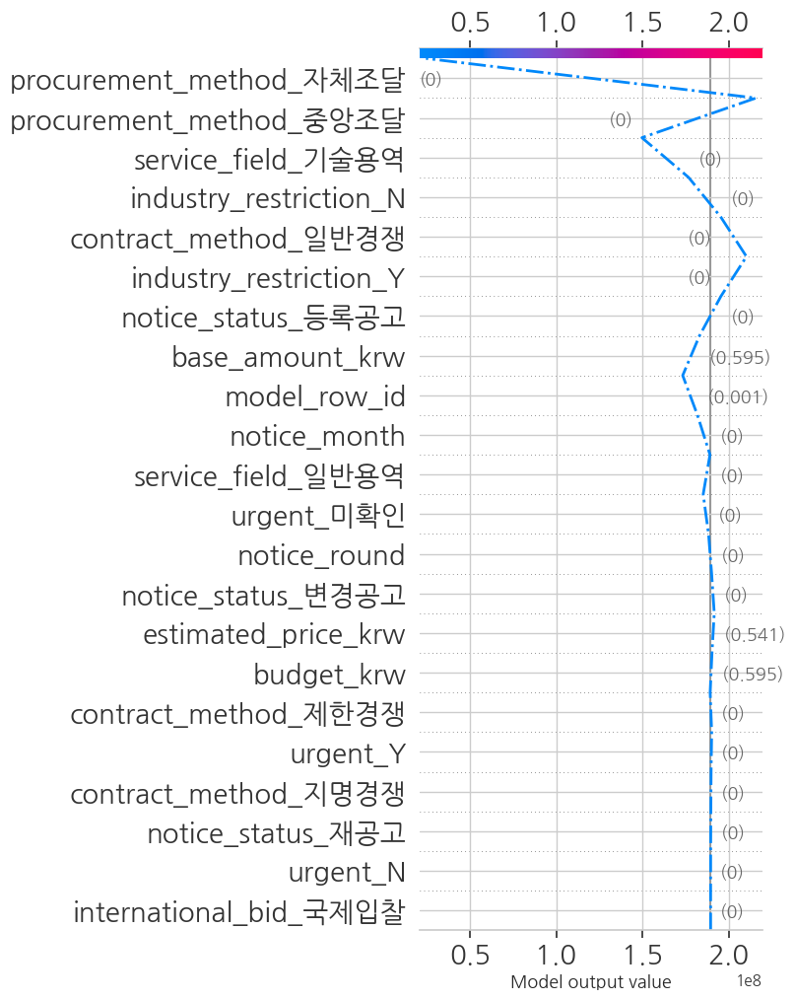

In [77]:
# Rename of Columns
X_selected = None
# df_domain_rename = pd.read_excel(os.path.join(FOLDER_GDM, '[Rename_20251228].xlsx'), sheet_name='Features_SI')
# df_domain_rename = {i[0]:i[1] for i in df_domain_rename[['변수설명(한글)', '변수설명(영어)']].values}
# if LANGUAGE == 'kr':
#     X_selected = [col for col in X_colname if col in list(df_domain_rename.keys())]
# else:
#     X_selected = [df_rename[col] for col in X_colname if col in list(df_domain_rename.keys())]

# SHAP 실행
explanation_SHAP(
    model=BEST_MODEL, 
    X_train=locals().get('X_train_ablation', X_train), Y_train=Y_train, 
    X_test=locals().get('X_test_ablation', X_test), Y_test=Y_test,
    X_colname=X_colname, X_selected=X_selected,
    interaction=INTERACTION,
    interaction_samples=INTERACTION_SAMPLES,
    interaction_batch=INTERACTION_BATCH,
    max_display=X_TOP_DISPLAY,
)


## Subgroup Comparison

In [ ]:
# # 연가구소득
# target_group = 'num__fe_Scope1_2_매출집약도'
# # groups = {f"{target_group}_{val}": val for val in sorted(X_test[target_group].dropna().unique())}
# groups = {
#     '1': lambda x: x < 0,
#     '2': lambda x: x>= 0
# }
# key_features=None

# df_comparison = explanation_SHAP_groupcomparing(
#     target_col=target_group,
#     groups_dict=groups,
#     X_train=X_train, X_test=X_test,
#     X_colname=X_colname,
#     # scaler_dict=BEST_PARAMS['scaler_type'],
#     best_algo=BEST_ALGO,
#     max_display=10,
#     save_csv=True,
#     target_features=key_features
# )

# Causality Analysis

In [ ]:
model_best, df_result, df_sensitivity = modeling_CF(
    df=df_prep,
    Y_colname=Y_colname,
    T_colname=T_colname,
    X_covariate=X_covariate,
    cv_candidate=CV_CANDIDATE,
    n_estimators=N_ESTIMATORS,      # 리뷰어 피드백 시 변경 가능
    cv_splits=CV_SPLITS,            # 강건성 확인 시 변경 가능
    random_state=RANDOM_STATE,
)